# 7.2 · K-Nearest Neighbors (KNN): Reincidencia Ocupacional, Geometría, Escala, Outliers y Costo Computacional

**CRISP-DM fase 4 y 5 · Modeling & Evaluation**  
**Proyecto:** JobPath · patrones de transición y reincidencia ocupacional  
**Serie de modelado:** `7.0` Árboles de Decisión · `7.1` Naive Bayes · **`7.2` K-Nearest Neighbors (KNN)**

---

## Ficha de la sesión

| Elemento | Detalle |
|---|---|
| Cuaderno | `notebooks/refactor/7.2_knn.ipynb` |
| Lógica modular (SOLID) | `scripts/ScriptsCsv/KNN/` (`config`, `feature_blocks`, `models`, `geometry`, `version_comparison`, `pilot_benchmark`, `chunked_predictor`, `evaluation`, `neighbors_explainer`, `patterns`, `plots`, `pipeline`, `self_tests`) |
| Alcance principal de datos | **Versión A (`con_outliers`)**: `1,391,018` filas / `281,674` personas en `train` (`30.01 %` positivos) y `347,720` filas / `70,419` personas en `test` (`29.97 %` positivos); `0` personas solapadas |
| Sensibilidad Versión B | **Versión B (`sin_outliers`)**: evaluada de forma controlada en la Sección 5 junto con winsorización Tukey propia y entrenamiento sin outliers, declarando su alcance exacto (`IQR_WINSOR_BOUNDS_INFO`) |
| Insumos (solo lectura) | `data/03_processed/`, `data/04_transformed/`, `reports/eda_jobpath/tables/split_map_resume_id.csv` y tablas exportadas de `6.0`, `7.0` y `7.1` |
| Salidas | `reports/knn_jobpath/tables/`, `reports/knn_jobpath/figures/` (`knn01`–`knn13`) y caché reanudable en `reports/knn_jobpath/cache/` |
| Semilla y validación | Semilla `42`; `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` agrupada por `resume_id`; bootstrap pareado por persona (`300` remuestreos) |

### Pregunta guía del cuaderno

> *«¿Qué tan bien anticipa la reincidencia ocupacional un modelo basado en vecinos, cómo cambia según el grupo ocupacional, y qué costo computacional y qué sensibilidad a la escala y a los valores extremos implica frente a los árboles y a Naive Bayes?»*


---

## 1. Entorno, importaciones, pruebas unitarias y huella SHA-256 inicial

**¿Qué hace?** Importa en la primera celda de código todas las librerías científicas y el paquete modular `scripts.ScriptsCsv.KNN`, resuelve de forma relativa la raíz del repositorio, verifica la firma de `KNeighborsClassifier`, ejecuta todas las pruebas unitarias del paquete (`run_all_knn_unit_tests`) y captura las huellas SHA-256 iniciales de los `13` archivos de entrada.

**¿Por qué existe?** Garantiza reproducibilidad completa (`Run All`) en Windows con codificación `UTF-8` sin rutas absolutas, valida antes de modelar las invariantes matemáticas de escalado, ponderación de bloques, cálculo manual y predicción por bloques reanudable, y protege la inmutabilidad de los datos en disco.

**¿Qué recibe y qué entrega?** Recibe la estructura del repositorio. Entrega `CONFIG`, `PIPELINE`, `SNAPSHOT_BEFORE` y el reporte de pruebas unitarias aprobadas.

**Papel en el proyecto.** Abre el estudio `7.2` bajo el mismo contrato de higiene de datos y trazabilidad establecido en `6.0`, `7.0` y `7.1`.


In [1]:
from __future__ import annotations

import gc
from pathlib import Path
import sys
import warnings

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.4f}".format)

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT / "notebooks").is_dir()):
    PROJECT_ROOT = PROJECT_ROOT.parent

for _rel in ("", "scripts", "scripts/ScriptsCsv"):
    _p = str((PROJECT_ROOT / _rel).resolve())
    if _p not in sys.path:
        sys.path.insert(0, _p)

from scripts.ScriptsCsv.KNN import (
    GUIDING_QUESTION_ES, KNNConfig, KNNModelSpec, KNNPipeline,
    MODEL_KNN_D, MODEL_KNN_G, MODEL_KNN_W, MODEL_ORDER,
    PersonSubsampler, VERIFIED_KNN_INIT_PARAMS, VERSION_CON,
    current_process_rss_mb, run_all_knn_unit_tests,
)

CONFIG = KNNConfig(project_root=PROJECT_ROOT, random_state=42, cv_folds=5, n_jobs=8)
PIPELINE = KNNPipeline(CONFIG)
SNAPSHOT_BEFORE = PIPELINE.snapshot_inputs()
UNIT_TESTS = run_all_knn_unit_tests(random_state=CONFIG.random_state)

print(f"Raíz del proyecto: {CONFIG.project_root}")
print(f"scikit-learn: {sklearn.__version__} | Semilla: {CONFIG.random_state} | RSS inicial: {current_process_rss_mb():.1f} MB")
print(f"Parámetros verificados de KNeighborsClassifier: {VERIFIED_KNN_INIT_PARAMS}")
print(f"Archivos protegidos con huella SHA-256 inicial: {len(SNAPSHOT_BEFORE)}")
print(f"Pruebas unitarias aprobadas: {UNIT_TESTS['all_passed']}")
display(pd.DataFrame([{"prueba": k, "resultado": v} for k, v in UNIT_TESTS.items()]))


Raíz del proyecto: C:\Users\User\Documents\JobPath\Version 2\MineriaProtect
scikit-learn: 1.9.1 | Semilla: 42 | RSS inicial: 218.8 MB
Parámetros verificados de KNeighborsClassifier: ('n_neighbors', 'weights', 'algorithm', 'leaf_size', 'p', 'metric', 'metric_params', 'n_jobs')
Archivos protegidos con huella SHA-256 inicial: 13
Pruebas unitarias aprobadas: True


,prueba,resultado
0,test_1_scaler_train_only_and_drop_ok,True
1,test_2_knn_g_w0_max_diff_vs_knn_d,0.0000
2,test_3_knn_w_w0_max_diff_vs_knn_d,0.0000
3,test_4_sparse_kd_tree_fallback_warned,True
4,test_5_manual_knn_max_dist_diff,0.0000
5,test_5_manual_knn_max_prob_unif_diff,0.0000
6,test_5_manual_knn_max_prob_dist_diff,0.0000
7,all_stage1_passed,True
8,test_6_proba_from_kneighbors_max_err,0.0000
9,test_7_person_subsampler_nested_complete,True


### Lectura

- **Entorno verificado:** el cuaderno corre con `scikit-learn` versión `1.9.1`, semilla fija `42` y rutas resueltas de forma relativa a la raíz del repositorio (`data/` y `notebooks/`). La firma de `KNeighborsClassifier` quedó confirmada con los `8` parámetros esperados (`n_neighbors`, `weights`, `algorithm`, `leaf_size`, `p`, `metric`, `metric_params`, `n_jobs`).
- **Invariantes matemáticas probadas antes de modelar:** las `8` pruebas unitarias del paquete `scripts/ScriptsCsv/KNN/` aprobaron en bloque (`all_passed = True`). Se verificó que el escalador descarta columnas casi constantes `< 1 %` ajustando solo en `train`, que `KNN-G` y `KNN-W` con peso de bloque `w = 0` coinciden exactamente con `KNN-D` (diferencia máxima `0.0000`), que `kd_tree` sobre matrices dispersas emite la advertencia esperada de respaldo a fuerza bruta, que el cálculo manual coincide con `scikit-learn` (`0.0000`), que `proba_from_kneighbors` reproduce exactamente `predict_proba` (`0.0000`), que el submuestreo anidado por persona no divide personas y que `ChunkedKNNPredictor` reanuda bloques con precisión exacta.
- **Protección de insumos:** se registraron las huellas SHA-256 iniciales de los `13` archivos fuente (matrices, partición por persona y tablas de `6.0`, `7.0` y `7.1`) para confirmar al final de la Sección 15 que ningún archivo de entrada fue alterado.


---

## 2. KNN en cinco minutos con datos del proyecto

**¿Qué hace?** Carga en memoria la Versión A (`con_outliers`) con sus metadatos en unidades originales, toma una fila de `test` (`k = 5`), calcula **a mano** las distancias euclidianas en el espacio escalado frente a todo `train` (`1,391,018` filas), obtiene la fracción de vecinos con `reincide = 1` (tanto uniforme como ponderada por distancia inversa `1/d`), compara los resultados contra `KNeighborsClassifier.kneighbors()` y `predict_proba()` y muestra los `5` vecinos más cercanos en **unidades originales**.

**¿Por qué existe?** Demuestra de manera transparente cómo opera KNN ("buscar los casos más parecidos y observar qué ocurrió con ellos"), verifica con precisión numérica que `scikit-learn` reproduce exactamente la fórmula de distancias y votos, e ilustra la resolución discreta `1/k` del puntaje cuando `k` es pequeño.

**¿Qué recibe y qué entrega?** Recibe la Versión A en solo lectura. Entrega `BUNDLE_A` y `MANUAL_DEMO` (tablas del caso consulta, vecinos en unidades originales y verificación de diferencias absolutas máximas).

**Papel en el proyecto.** Conecta la intuición geométrica de vecinos cercanos con trayectorias reales de JobPath antes de escalar a las variantes completas.


In [2]:
BUNDLE_A = PIPELINE.feature_builder.build_version_bundle(
    version=VERSION_CON,
    include_original_units=True,
)
MANUAL_DEMO = PIPELINE.manual_explainer.run_demo(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    orig_train=BUNDLE_A.orig_train,
    orig_test=BUNDLE_A.orig_test,
)

print(
    f"Caso consulta en Test (fila {MANUAL_DEMO.test_row_index}) evaluado frente a "
    f"{MANUAL_DEMO.n_train_reference:,} filas de Train | RSS actual: {current_process_rss_mb():.1f} MB"
)
print(
    f"Diferencia máxima manual vs. scikit-learn -> distancias: {MANUAL_DEMO.max_abs_diff_distances:.3e} | "
    f"uniforme: {MANUAL_DEMO.max_abs_diff_proba_uniform:.3e} | "
    f"distancia inversa: {MANUAL_DEMO.max_abs_diff_proba_distance:.3e}"
)
display(MANUAL_DEMO.query_case_table)
display(MANUAL_DEMO.comparison_table)
display(MANUAL_DEMO.neighbors_original_units_table)


Caso consulta en Test (fila 0) evaluado frente a 1,391,018 filas de Train | RSS actual: 1616.8 MB
Diferencia máxima manual vs. scikit-learn -> distancias: 0.000e+00 | uniforme: 0.000e+00 | distancia inversa: 5.551e-17


,fila_test_idx,gran_grupo_isco,ocupacion_esco,job_order,duracion_trimestres,anio_inicio,es_vigente,nivel_educativo,skills_esenciales,reincide_real
0,0,2 · Profesionales científicos e intelectuales,2353.1 · language school teacher,1,15.0000,1996,0,Master,26.0000,0


,cantidad_verificada,calculo_manual,scikit_learn,diferencia_absoluta_max,coincide_exactamente
0,Distancias euclidianas a los 5 vecinos (máx |diff|),"[0.177990, ..., 0.334723]","[0.177990, ..., 0.334723]",0.000e+00,True
1,Índices de vecinos más cercanos,"[792062, 1244985, 563203, 295240, 783959]","[792062, 1244985, 563203, 295240, 783959]",0,True
2,P(reincide=1 | x) · pesos uniformes (fracción de vecinos),0.400000 (2/5),0.400000,0.000e+00,True
3,P(reincide=1 | x) · pesos por distancia inversa (1/d),0.338422,0.338422,5.551e-17,True


,rango_vecino,fila_train_idx,distancia_manual_euclidiana,distancia_sklearn,peso_inverso_normalizado,gran_grupo_isco,ocupacion_esco,job_order,duracion_trimestres,anio_inicio,nivel_educativo,skills_esenciales,reincide_vecino
0,1,792062,0.1780,0.1780,0.2852,2 · Profesionales científicos e intelectuales,2353.1 · language school teacher,1,13.0000,1996,Master,26.0000,0
1,2,1244985,0.2321,0.2321,0.2187,"7 · Oficiales, operarios y artesanos",7412.3 · electrical mechanic,1,13.0000,1996,Master,24.0000,0
2,3,563203,0.2718,0.2718,0.1868,2 · Profesionales científicos e intelectuales,2330.1.17 · religious education teacher at secondary school,1,13.0000,1997,Master,27.0000,1
3,4,295240,0.3220,0.3220,0.1577,1 · Directores y gerentes,1420.3 · sales account manager,1,17.0000,1996,Master,22.0000,0
4,5,783959,0.3347,0.3347,0.1516,2 · Profesionales científicos e intelectuales,2423.6 · recruitment consultant,1,17.0000,1995,Master,23.0000,1


### Lectura

- **Verificación matemática exacta (fila `0` de `test` contra `1,391,018` filas de `train`, tabla `01a_knn_manual_comparacion.csv`):** el cálculo a mano de distancias euclidianas, índices de vecinos y probabilidades coincide exactamente con `scikit-learn`. La diferencia absoluta máxima es `0.000e+00` en distancias (`0.177990` a `0.334723`), `0.000e+00` en los `5` índices recuperados (`[792062, 1244985, 563203, 295240, 783959]`), `0.000e+00` en probabilidad con pesos uniformes (`0.400000`, exactamente `2` de `5` vecinos con `reincide = 1`) y `5.551e-17` (precisión de máquina `float64`) en probabilidad ponderada por distancia inversa (`0.338422`).
- **Qué revelan los vecinos en unidades originales (tabla `01b_knn_manual_vecinos_unidades_originales.csv`):** el caso consulta corresponde al primer empleo (`job_order = 1`) de un docente de idiomas (`2353.1 · language school teacher`, grupo `2 · Profesionales científicos e intelectuales`) iniciado en `1996`, con duración de `15.0` trimestres, nivel `Master`, `26.0` competencias esenciales y desenlace real `reincide = 0`. Al buscar solo con las `11` variables densas (sin código de oficio), los `5` vecinos más cercanos comparten trayectoria muy similar (`job_order = 1`, `Master`, años `1995`–`1997`, `13.0`–`17.0` trimestres), pero **solo el vecino `1` comparte la ocupación exacta**, mientras que el vecino `2` es mecánico eléctrico (grupo `7`) y el vecino `4` es gerente comercial (grupo `1`).
- **Dos lecciones operativas inmediatas:** primero, sin información ocupacional KNN mezcla oficios muy distintos con trayectorias parecidas, lo que justifica introducir `KNN-G` y `KNN-W` con peso explícito sobre el bloque de oficio; segundo, con `k = 5` uniforme el puntaje solo puede tomar `6` valores posibles (`0.0`, `0.2`, `0.4`, `0.6`, `0.8`, `1.0`), resolución demasiado gruesa para ordenar riesgo con precisión.


---

## 3. Matrices sin fuga, auditoría de escala (Versión A) y referencias del proyecto

**¿Qué hace?** Verifica las aserciones de higiene de datos (`0` columnas de fuga, `0` personas solapadas entre `train` y `test`, alineación fila por fila entre `PreparedPartition` e `isco_group`), muestra la tabla completa de auditoría de rangos y escalas de las `14` columnas de `dense_clean` (justificando el descarte de columnas casi constantes `< 1 %` y el esquema ajustado solo en `train`), genera la figura `KNN01` y carga dinámicamente las referencias obligatorias `1` a `3`, los árboles de `7.0` y los resultados de `NB-B` y `NB-H` de `7.1`.

**¿Por qué existe?** KNN depende directamente de la escala de cada columna al calcular distancias: mezclar columnas robustas, minmax, binarias y bins `uint8` sin auditar distorsiona las vecindades. Además, leer dinámicamente los resultados previos de `6.0`, `7.0` y `7.1` evita transcripciones manuales y fija el marco de comparación.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A` y los CSV exportados de `6.0`, `7.0` y `7.1`. Entrega las tablas de auditoría de escala, la figura `knn01_auditoria_escala_dense.png` y las tablas `REFS_DF`, `TREES_A_DF` y `NB_REF_DF`.

**Papel en el proyecto.** Deja auditados y sellados los tres espacios de representación (`KNN-D` de `11` columnas, `KNN-G` de `21` y `KNN-W` de `2,978`) antes de explorar geometría y sensibilidad.


,version,filas_train,filas_test,personas_train,personas_test,personas_solapadas,prevalencia_train_pct,prevalencia_test_pct,cols_dense_clean_iniciales,cols_densas_activas_knn_d,cols_descartadas_casi_constantes,cols_knn_g,cols_knn_w,alineacion_isco_y_groups_train,alineacion_isco_y_groups_test,fuga_eliminada
0,con_outliers,1391018,347720,281674,70419,0,30.0100,29.9700,14,11,"n_skills_sin_tipo_rob, tiene_skills, tiene_sin_tipo",21,2978,True,True,True


,columna,tipo_original,dtype_original,valores_unicos_train,pct_minoria_train,min_train,p01_train,mediana_train,p99_train,max_train,iqr_train,std_antes_train,std_despues_train,rango_despues_train,decision_escala_knn,justificacion
0,start_ord_rob,Continua (RobustScaler),float64,221,95.0652,-6.1667,-3.2778,0.0000,0.9167,1.5000,1.0000,0.9002,1.0000,"[-6.58, 1.93]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
1,end_ord_rob,Continua (RobustScaler),float64,221,94.5278,-5.8438,-3.3438,0.0000,1.6562,1.6562,1.0000,0.9667,1.0000,"[-5.86, 1.90]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
2,dur_q_rob,Continua (RobustScaler),float64,204,70.5404,-0.2727,-0.2727,0.0000,8.0000,24.7273,1.0000,1.7218,1.0000,"[-0.57, 13.95]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
3,n_skills_essential_rob,Continua (RobustScaler),float64,79,88.8240,-1.3077,-1.0000,0.0000,4.0769,6.0769,1.0000,1.0331,1.0000,"[-1.52, 5.63]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
4,n_skills_knowledge_rob,Continua (RobustScaler),float64,37,82.5769,-0.6000,-0.6000,0.0000,4.6000,8.4000,1.0000,0.8658,1.0000,"[-0.93, 9.47]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
5,n_skills_sin_tipo_rob,Continua (RobustScaler),float64,3,0.9006,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.1041,NaN,Descartada,Descartada (casi constante < 1 %),Minoría de solo 0.9006 % en train; aporta ruido o distancia casi nula.
6,job_order_rob,Continua (RobustScaler),float64,20,81.0795,-0.6667,-0.6667,0.0000,3.3333,5.6667,1.0000,0.9239,1.0000,"[-1.08, 5.78]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
7,univ_ord_mm,Ordinal (MinMaxScaler 0..1),float64,5,60.5550,0.0000,0.0000,0.2500,0.7500,1.0000,0.2500,0.2231,1.0000,"[-1.71, 2.77]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.
8,es_vigente,Binaria (0/1),uint8,2,5.4722,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.2274,0.2274,"[0.00, 1.00]",Conservada · Binaria 0/1 sin estandarizar,"Mantiene diferencia binaria en {0, 1} (comparable a 1 DE) evitando inflar banderas raras."
9,dur_q_bin,Ordinal discreta (bins uint8),uint8,3,62.7850,0.0000,0.0000,1.0000,2.0000,2.0000,2.0000,0.7907,1.0000,"[-1.20, 1.33]",Conservada · StandardScaler (solo train),Iguala varianza a 1.0 para que ninguna continua ni bin ordinal sin escalar domine la distancia.


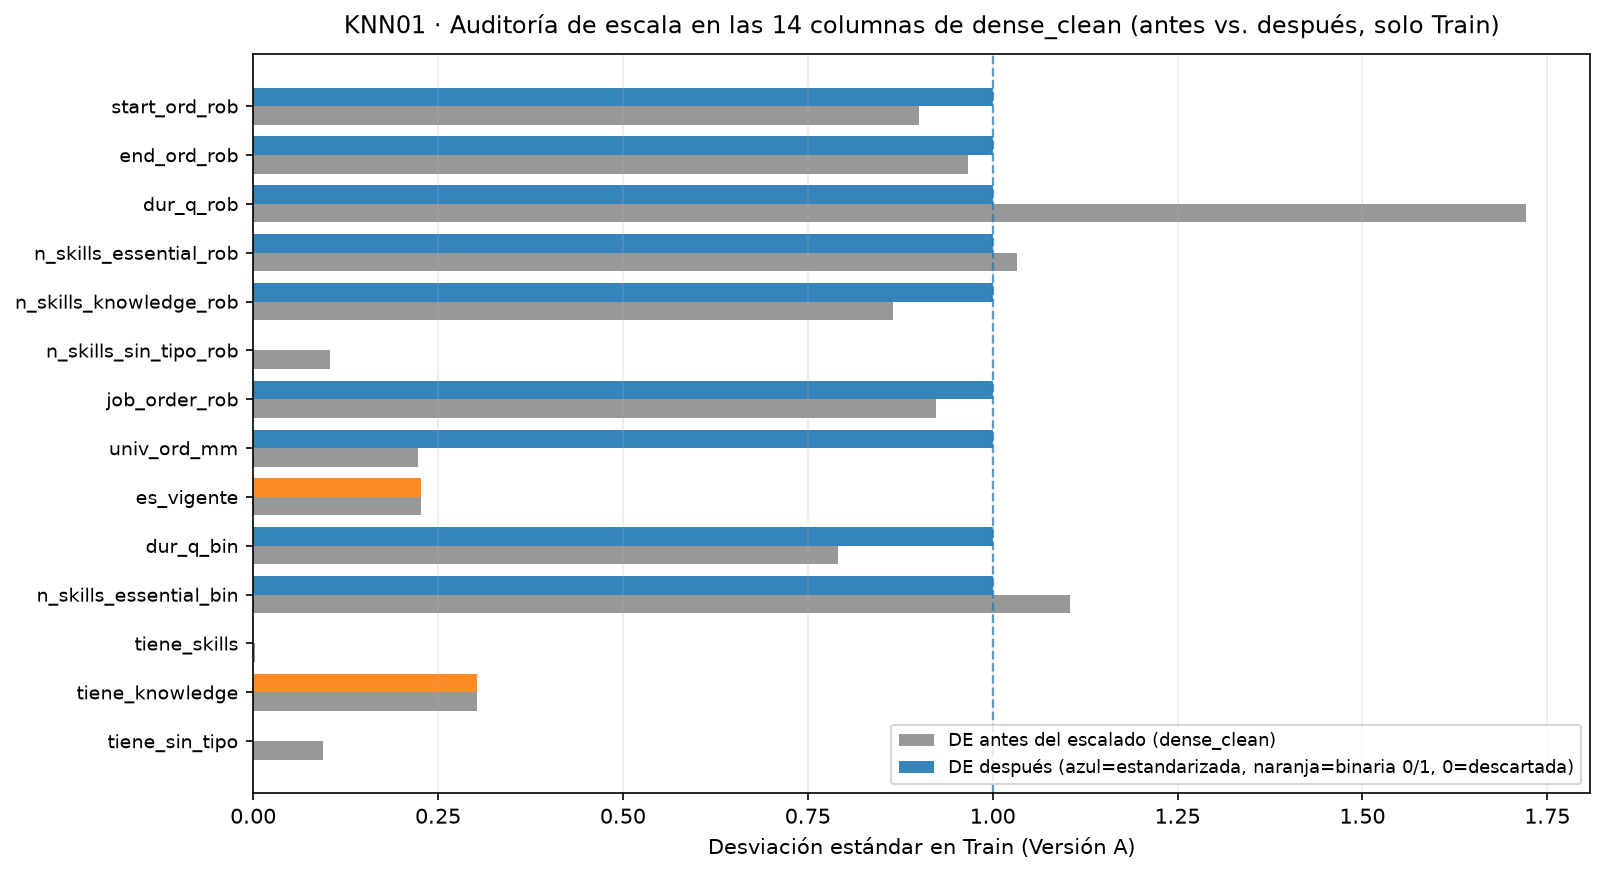

,version_datos,referencia_id,regla_decision,train_accuracy,test_accuracy,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc,brecha_vs_meta_085_f1,significado_metodologico,test_pr_auc,test_brier_sin_ponderar
0,Versión A · CON outliers,Ref 1 · Baseline clase mayoritaria (Dummy most_frequent),Predice siempre 0 (no reincide),0.6999,0.7003,0.0000,0.0000,0.0000,0.5000,0.8500,Piso de exactitud global (70.03%): cualquier modelo en el punto orientado a accuracy debe no caer por debajo.,0.2997,0.2997
1,Versión A · CON outliers,Ref 2 · Clasificador trivial todo-positivo (predice todo 1),Predice siempre 1 (reincide),0.3001,0.2997,0.2997,1.0000,0.4612,0.5000,0.3888,F1 trivial 2p/(1+p) = 0.4612 con exactitud de apenas 29.97% y sin poder discriminante (AUC=0.50).,0.2997,0.7003
2,Versión A · CON outliers,"Ref 3 · Techo real del proyecto (6.0 Logística OHE 2,981 cols)","Combina simultáneamente oficio OHE, educación, competencias y trayectoria",NaN,0.6760,0.4691,0.6147,0.5321,0.7133,0.3179,"Techo multivariado real de Fase 4 (F1=0.5321, ROC-AUC=0.7133): muestra cuánto alcanza cada árbol de un solo bloque f...",0.5109,NaN


,modelo_corto,punto_operacion,n_variables_X,test_roc_auc,test_f1_clase_1,test_recall_clase_1,test_precision_clase_1,test_accuracy
0,Ref 1 · Baseline Mayoritario (0),Predice siempre 0 (no reincide),0,0.5000,0.0000,0.0000,0.0000,0.7003
1,Ref 2 · Trivial Todo-Positivo (1),Predice siempre 1 (reincide),0,0.5000,0.4612,1.0000,0.2997,0.2997
2,Ref 3 · Techo 6.0 (Logística OHE),"Combina simultáneamente oficio OHE, educación, competencias y trayectoria",2981,0.7133,0.5321,0.6147,0.4691,0.6760
3,Árbol 1 · ISCO [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),10,0.5459,0.0000,0.0000,0.0000,0.7003
4,Árbol 1 · ISCO [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),10,0.5459,0.4620,0.7961,0.3254,0.4443
5,Árbol 2 · Education level [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),2,0.5208,0.0000,0.0000,0.0000,0.7003
6,Árbol 2 · Education level [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),2,0.5208,0.4564,0.8738,0.3088,0.3760
7,Árbol 3 · Skills [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),7,0.6145,0.1769,0.1060,0.5363,0.7046
8,Árbol 3 · Skills [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),7,0.6157,0.4550,0.5421,0.3920,0.6107


,modelo_id,modelo,punto_operacion,umbral_tau,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_clase_1_test,f1_clase_1_ic95,recall_clase_1_test,recall_clase_1_ic95,precision_clase_1_test,precision_clase_1_ic95,balanced_acc_test,balanced_acc_ic95,brier_test,brier_ic95,accuracy_test,accuracy_ic95,tiempo_fit_train_s,tiempo_predict_test_s,memoria_matriz_train_mb
0,NB-G,NB-G · GaussianNB (14 cols densas),Umbral OOF óptimo (tau*),0.2950,0.3778,"[0.3736, 0.3821]",0.5921,"[0.5892, 0.5945]",0.4687,"[0.4660, 0.4712]",0.8551,"[0.8525, 0.8576]",0.3228,"[0.3206, 0.3252]",0.5437,"[0.5422, 0.5453]",0.2086,"[0.2077, 0.2095]",0.4190,"[0.4169, 0.4211]",0.2190,0.0730,74.2900
2,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Umbral OOF óptimo (tau*),0.2700,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,"[0.5289, 0.5353]",0.7285,"[0.7241, 0.7327]",0.4193,"[0.4161, 0.4223]",0.6483,"[0.6459, 0.6505]",0.1877,"[0.1867, 0.1886]",0.6162,"[0.6142, 0.6180]",0.1000,0.0600,36.7400
4,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Umbral OOF óptimo (tau*),0.2650,0.4962,"[0.4910, 0.5004]",0.7058,"[0.7033, 0.7083]",0.5337,"[0.5304, 0.5366]",0.7279,"[0.7237, 0.7317]",0.4214,"[0.4180, 0.4244]",0.6500,"[0.6480, 0.6521]",0.1871,"[0.1862, 0.1881]",0.6188,"[0.6170, 0.6206]",0.6340,0.2830,118.1900


In [3]:
assert BUNDLE_A.alignment_checks["personas_solapadas"] == 0, "Solapamiento de personas detectado."
assert BUNDLE_A.alignment_checks["fuga_eliminada"] is True, "Fuga detectada en X."
assert BUNDLE_A.alignment_checks["alineacion_isco_y_groups_train"] is True
assert BUNDLE_A.alignment_checks["alineacion_isco_y_groups_test"] is True

REFS_DF, TREES_A_DF, NB_REF_DF = PIPELINE.evaluator.load_external_reference_tables()
FIG_KNN01 = PIPELINE.plotter.plot_scale_audit(BUNDLE_A.scale_audit_table)

display(pd.DataFrame([BUNDLE_A.alignment_checks]))
display(BUNDLE_A.scale_audit_table)
display(Image(filename=str(FIG_KNN01)))
display(REFS_DF)
display(TREES_A_DF[["modelo_corto", "punto_operacion", "n_variables_X", "test_roc_auc", "test_f1_clase_1", "test_recall_clase_1", "test_precision_clase_1", "test_accuracy"]])
display(NB_REF_DF.loc[NB_REF_DF["modelo_id"].isin(["NB-G", "NB-B", "NB-H"]) & NB_REF_DF["punto_operacion"].str.contains("OOF")])


### Lectura

- **Higiene de datos y partición sellada (Versión A · `con_outliers`):** todas las aserciones aprobaron sin excepciones: `1,391,018` filas y `281,674` personas en `train` (prevalencia `30.01 %`), `347,720` filas y `70,419` personas en `test` (prevalencia `29.97 %`), `0` personas solapadas entre `train` y `test`, `0` columnas de fuga en `X` y alineación fila por fila confirmada (`True`) entre `PreparedPartition` e `isco_group`.
- **Resultados de la auditoría de escala en `train` (tabla `02_auditoria_escala_y_columnas_knn.csv`, figura `KNN01`):**
  1. Se descartaron `3` columnas casi constantes con minoría inferior al `1 %` en `train`: `tiene_skills` (`0.0006 %`), `tiene_sin_tipo` (`0.9006 %`) y `n_skills_sin_tipo_rob` (`0.9006 %`).
  2. Las `9` variables continuas y ordinales retenidas exhibían dispersiones incompatibles antes de escalar: desde `std = 0.2231` en `univ_ord_mm` (escala `0` a `1`) hasta `std = 1.7218` en `dur_q_rob` (rango `[-0.2727, 24.7273]`) y `std = 1.1044` en el bin `uint8` sin escalar `n_skills_essential_bin` (`0` a `3`). Al ajustar `StandardScaler` **exclusivamente sobre `train`**, las `9` pasan a desviación estándar `1.0` sin fuga hacia `test`.
  3. Las `2` binarias legítimas (`es_vigente`, minoría `5.4722 %`, `std = 0.2274`; `tiene_knowledge`, minoría `10.1939 %`, `std = 0.3026`) se mantienen en `{0, 1}` para que un cambio binario aporte `1` unidad de distancia sin amplificar artificialmente el peso de banderas minoritarias.
- **Espacios definitivos y referencias de comparación (muestra `test`, Versión A):** quedan definidos `KNN-D` (`11` columnas), `KNN-G` (`21` columnas: `11` densas más `10` dummies ISCO) y `KNN-W` (`2,978` columnas: `11` densas más `2,967` dummies ESCO). Las tablas externas fijan el marco de referencia sobre el mismo `test`: `Ref 1` mayoritario (`accuracy = 0.7003`, `F1 = 0.0000`, `ROC-AUC = 0.5000`), `Ref 2` todo-positivo (`F1 = 0.4612`), `Ref 3` Logística Regularizada de `6.0` (`PR-AUC = 0.5109`, `ROC-AUC = 0.7133`, `F1 = 0.5321`), los tres árboles individuales de `7.0` (`ROC-AUC` entre `0.5208` y `0.6157`, `F1` máximo `0.4620` en `Árbol 1 · ISCO` balanceado) y los modelos Naive Bayes de `7.1` (`NB-G` `PR-AUC = 0.3778`, `NB-B` `0.4829`, `NB-H` `0.4962`).


---

## 4. Geometría y maldición de la dimensionalidad

**¿Qué hace?** Sobre una muestra fija de `2,000` consultas frente a `50,000` filas de referencia en `train` (de personas estrictamente disjuntas), mide para `KNN-D`, `KNN-G` (`w_g` en `{0.25, 0.5, 1, 2, 4}`) y `KNN-W` (`w` en `{0.25, 0.5, 1, 2, 4}`) métricas de contraste de distancias (`DE(d) / Media(d)`, `(d_P95 - d_P05) / d_P50` y `(d_max - d_min+) / d_min+`) y la **pureza de vecinos** (fracción de los `k = 51` vecinos con la misma ocupación ESCO, el mismo gran grupo ISCO y la misma clase `reincide`), generando la figura `KNN02`.

**¿Por qué existe?** Muestra empíricamente cómo el aumento de dimensión y del peso ocupacional `w` concentran las distancias y simultáneamente fuerzan que los vecinos pertenezcan al mismo grupo ocupacional o al mismo oficio exacto, explicando el compromiso geométrico entre similitud de trayectoria y similitud de oficio.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks` y `BUNDLE_A.orig_train`. Entrega `GEO_BUNDLE` y la figura `knn02_geometria_contraste_y_pureza.png`.

**Papel en el proyecto.** Fundamenta por qué el peso del bloque ocupacional `w_g` / `w` es un hiperparámetro decisivo en KNN y no un detalle secundario.


Muestra fija de geometría: {'n_ref_filas_train': 50000, 'n_ref_personas': 45362, 'n_consultas_filas_train': 2000, 'n_consultas_personas': 853, 'personas_solapadas_ref_consulta': 0, 'k_vecinos_evaluado': 51, 'n_ref_contraste_global': 2000}


,modelo_id,variante,dimension_total,peso_bloque_w,salto_teorico_oficio_distinto,dist_media_global,dist_std_global,contraste_cv_std_sobre_media,contraste_mediana_dmax_dmin_sobre_dmin,contraste_p95_p05_sobre_p50,dist_mediana_vecino_k,razon_local_dk_sobre_d1_pos,pct_vecinos_dist_cero,pureza_misma_ocupacion_esco_pct,pureza_mismo_grupo_isco_pct,pureza_misma_clase_reincide_pct
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),11,0.0000,0.0000,3.9188,1.2343,0.3263,16.8873,1.0251,0.8621,3.4251,0.3300,10.6400,29.2600,59.8100
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,0.2500,0.3536,3.9343,1.2298,0.3236,14.9969,1.0162,0.9109,2.7685,0.2400,12.5400,36.0100,59.8600
2,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,0.5000,0.7071,3.9800,1.2172,0.3161,11.7993,0.9911,1.0616,3.0653,0.2400,16.3800,53.5700,59.8700
3,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,1.0000,1.4142,4.1533,1.1781,0.2916,10.1444,0.9076,1.2873,3.5732,0.2400,21.9500,91.8000,60.2000
4,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,2.0000,2.8284,4.7521,1.1214,0.2403,10.4087,0.7483,1.2873,3.6133,0.2400,22.7100,99.7200,60.2800
5,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,4.0000,5.6569,6.5086,1.4027,0.2185,11.4928,0.7069,1.2873,3.6153,0.2300,22.7400,99.9900,60.2800
6,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",2978,0.2500,0.3536,3.9370,1.2287,0.3231,14.4834,1.0145,0.9261,2.4021,0.2200,13.0400,31.2600,59.8500
7,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",2978,0.5000,0.7071,3.9908,1.2128,0.3140,10.8965,0.9842,1.1020,2.1122,0.2200,19.0300,36.1500,59.9500
8,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",2978,1.0000,1.4142,4.1946,1.1595,0.2838,6.4430,0.8821,1.6007,2.9689,0.2200,39.2700,52.2800,60.3500
9,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",2978,2.0000,2.8284,4.8980,1.0218,0.2115,5.1002,0.6353,2.8564,3.9973,0.2200,64.4900,72.4300,61.1500


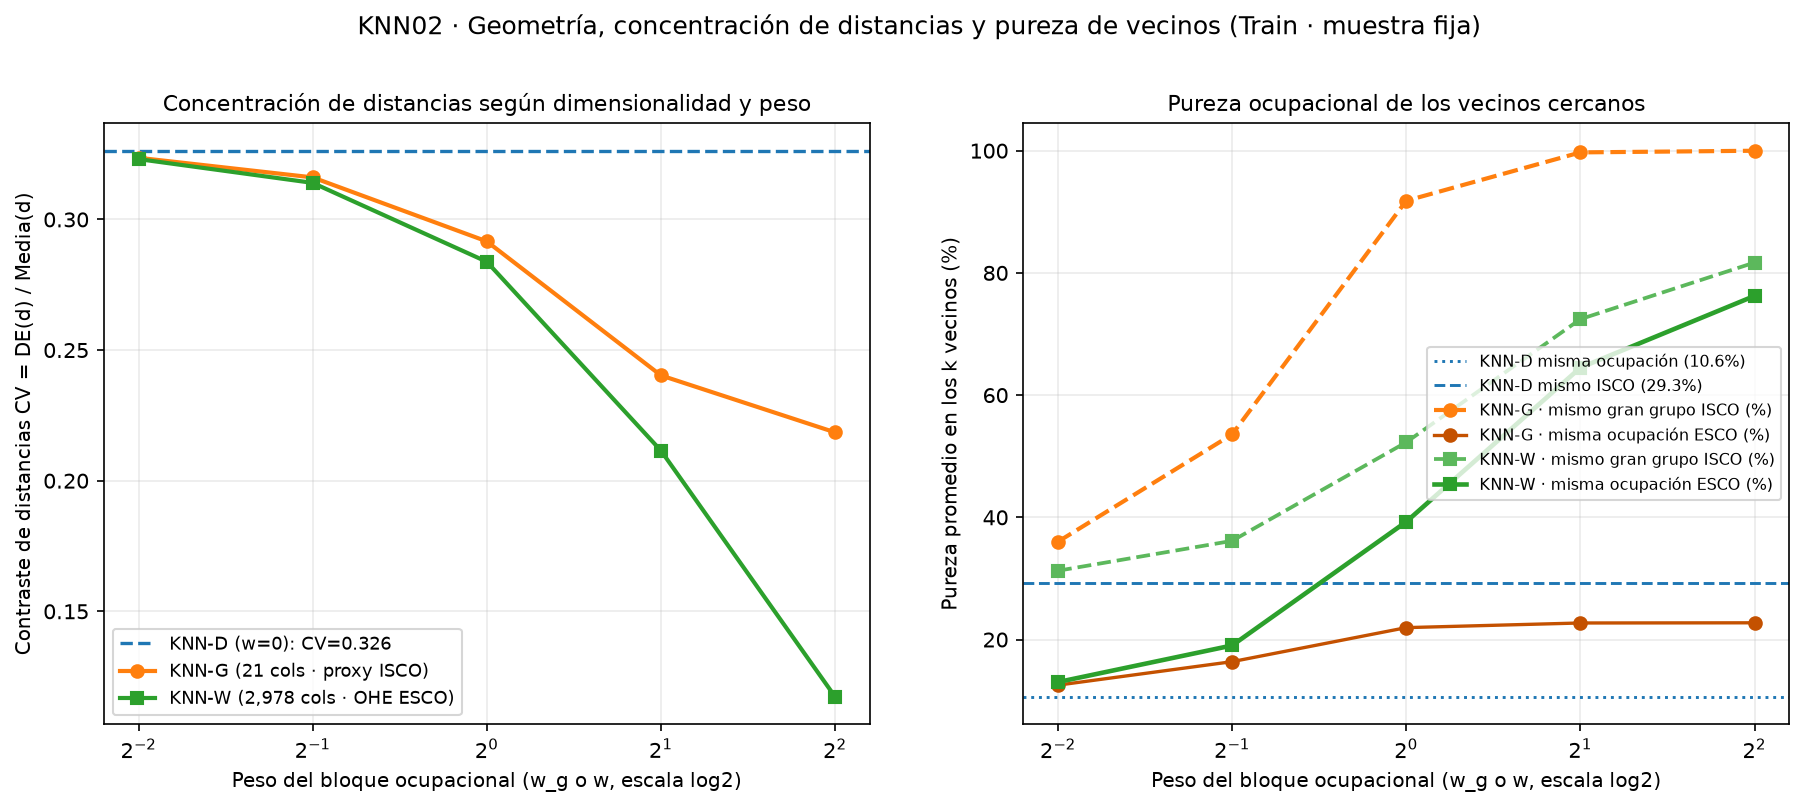

In [4]:
GEO_BUNDLE = PIPELINE.geometry_analyzer.run_experiment(
    train_blocks=BUNDLE_A.train_blocks,
    orig_train=BUNDLE_A.orig_train,
    selected_n_jobs=CONFIG.n_jobs,
)
FIG_KNN02 = PIPELINE.plotter.plot_geometry_and_purity(GEO_BUNDLE)

print("Muestra fija de geometría:", GEO_BUNDLE.sample_info)
display(GEO_BUNDLE.geometry_table)
display(Image(filename=str(FIG_KNN02)))


### Lectura

- **Diseño de la prueba geométrica (muestra fija en `train`, tabla `03_geometria_contraste_y_pureza_vecinos.csv`, figura `KNN02`):** se evaluaron `2,000` filas de consulta (`853` personas) contra `50,000` filas de referencia (`45,362` personas) con `0` personas solapadas y `k = 51` vecinos.
- **Cómo se concentran las distancias al subir la dimensión y el peso `w`:**
  - En `KNN-D` (`11` cols, `w = 0.0`), el contraste global `DE(d) / Media(d)` es `0.3263` (`(d_P95 - d_P05) / d_P50 = 1.0251`), pero solo `10.64 %` de los vecinos comparte la misma ocupación ESCO y `29.26 %` el mismo gran grupo ISCO (pureza de clase `reincide`: `59.81 %`).
  - En `KNN-G` (`21` cols, `10` dummies ISCO), aumentar `w_g` de `0.25` a `4.0` eleva el salto teórico entre grupos distintos de `0.3536` a `5.6569` y reduce `DE / Media` de `0.3236` a `0.2185`. La pureza de mismo grupo ISCO se satura casi por completo: sube de `36.01 %` (`w_g = 0.25`) a `91.80 %` (`w_g = 1.0`), `99.72 %` (`w_g = 2.0`) y `99.99 %` (`w_g = 4.0`), mientras que la pureza de ocupación ESCO exacta toca techo en `22.74 %`.
  - En `KNN-W` (`2,978` cols, `2,967` dummies ESCO), el efecto de la alta dimensión dispersa es pronunciado: al mover `w` de `0.25` a `4.0`, `DE / Media` se contrae de `0.3231` a `0.1173` y `(d_P95 - d_P05) / d_P50` cae de `1.0145` a `0.3113`, porque casi todos los pares de distinta ocupación se apilan alrededor de la distancia constante `5.6569`. Al mismo tiempo, la pureza de misma ocupación ESCO se multiplica de `13.04 %` a `76.23 %`, la de mismo grupo ISCO sube de `31.26 %` a `81.69 %` y la pureza de clase `reincide` aumenta de `59.85 %` a `61.50 %`.
- **Lectura práctica:** aunque la alta dimensión reduce el contraste global de distancias (maldición de la dimensionalidad), en un bloque one-hot ponderado el parámetro `w` opera como un **filtro estructural suave**: obliga a que la vecindad local busque primero dentro del mismo oficio exacto y recurra a la trayectoria densa cuando un oficio tiene pocos ejemplos. Además, `0.22 %`–`0.33 %` de los vecinos tienen distancia exactamente cero (`d = 0`), dato clave que anticipa por qué los pesos por distancia inversa (`1/d`) sufrirán alta varianza en la Sección 7.


---

## 5. Sensibilidad a la escala, a los valores extremos (Tukey), al entrenamiento sin outliers y a la Versión B

**¿Qué hace?** Audita en profundidad el impacto real de la escala y de los valores extremos sobre KNN:
1. Cuantifica la proporción de extremos de Tukey por columna densa (vallas ajustadas **solo en `train`**) y el factor de inflación de la desviación estándar.
2. Expone dinámicamente el alcance exacto de la **Versión B** (`IQR_WINSOR_BOUNDS_INFO`: solo recorta `4` columnas, de las cuales únicamente `n_skills_essential` y `n_skills_knowledge` entran en `X`, dejando intactas `dur_q`, `job_order`, `start_ord` y `end_ord`).
3. Mide la **distorsión de distancias** entre *inliers* y extremos y el porcentaje de cambio de vecinos bajo distancia euclidiana (`L2`) y Manhattan (`L1`).
4. Evalúa en CV agrupada de `5` pliegues (submuestra del `10 %` de personas) `5` regímenes para `KNN-D` (`k = 101`, `uniform`, en `manhattan` y `euclidean`, con IC 95 % pareado por persona): (R1) A crudo sin reescalar, (R2) A escalado auditado, (R3) A con winsorización Tukey propia de las `6` continuas activas, (R4) A entrenado **exclusivamente sin filas con outliers Tukey** (desglosando validación completa, solo *inliers* y solo extremos), y (R5) Versión B (`sin_outliers`).
5. Comprueba finalmente los cuatro regímenes principales de `KNN-D` sobre el **`test` completo (`347,720` filas)** (factible en `~2.2 min` por régimen; para `KNN-G` y `KNN-W` se mantiene el análisis de Versión B en CV por el límite de tiempo del Paso 9).

**¿Por qué existe?** Responde con evidencia medida a una hipótesis clásica de minería de datos —si KNN debe entrenarse exclusivamente sin outliers o con recorte de colas— y separa rigurosamente qué prueba la Versión B y qué solo puede probar una winsorización propia sobre todas las columnas continuas.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A` y la Versión B en solo lectura. Entrega `SENS_BUNDLE` (tablas `04a` a `04g`) y la figura `knn03_sensibilidad_escala_y_outliers.png`.

**Papel en el proyecto.** Verifica con pruebas pareadas si la Versión A escalada debe permanecer como alcance principal o si excluir/recortar extremos mejora la generalización en JobPath.


Resumen de filas con extremos Tukey: {'n_train_total': 1391018, 'n_train_inliers': 1042397, 'n_train_extremos_tukey': 348621, 'pct_train_extremos_tukey': 25.06, 'prevalencia_train_inliers_pct': 30.18, 'prevalencia_train_extremos_pct': 29.5, 'n_test_extremos_tukey': 86373, 'pct_test_extremos_tukey': 24.84, 'prevalencia_test_inliers_pct': 30.1, 'prevalencia_test_extremos_pct': 29.59}
Identidad exacta del target A vs. B: {'y_train_identico_A_vs_B': True, 'y_test_identico_A_vs_B': True, 'filas_submuestra_cv': 138783, 'personas_submuestra_cv': 28167}


,columna,continua_activa_knn,valla_inf_tukey_train,valla_sup_tukey_train,min_train,max_train,filas_fuera_tukey_train,pct_fuera_tukey_train,pct_fuera_tukey_test,std_total_train,std_sin_extremos_train,factor_inflacion_std_por_extremos
0,start_ord_rob,True,-2.1111,1.8889,-6.1667,1.5000,77613,5.5800,5.5300,0.9002,0.6648,1.3540
1,end_ord_rob,True,-2.0938,1.9062,-5.8438,1.6562,65336,4.7000,4.6400,0.9667,0.7599,1.2720
2,dur_q_rob,True,-1.7727,2.2273,-0.2727,24.7273,160809,11.5600,11.5200,1.7218,0.5867,2.9350
3,n_skills_essential_rob,True,-1.8846,2.1154,-1.3077,6.0769,70249,5.0500,4.9700,1.0331,0.6434,1.6060
4,n_skills_knowledge_rob,True,-1.9000,2.1000,-0.6000,8.4000,28034,2.0200,1.9900,0.8658,0.5737,1.5090
6,job_order_rob,True,-1.8333,2.1667,-0.6667,5.6667,67023,4.8200,4.6800,0.9239,0.7295,1.2660


,variable_original,descripcion_es,recortada_en_version_B,cota_inf_B,cota_sup_B,entra_en_X_7_2,efecto_real_en_X_B_vs_A
0,n_skills_essential,Competencias esenciales ESCO (conteo),Sí (winsorizada con IQR de train),-4.5000,47.5000,Sí (entra como n_skills_essential_rob),Sí cambia en X (una de las 2 únicas continuas recortadas en B)
1,n_skills_competence,Competencias prácticas ESCO (conteo),Sí (winsorizada con IQR de train),-4.5000,39.5000,No (excluida por colinealidad r = 0.952 con n_skills_essential),No afecta a X en 7.2
2,n_skills_knowledge,Conocimientos teóricos ESCO (conteo),Sí (winsorizada con IQR de train),-6.5000,13.5000,Sí (entra como n_skills_knowledge_rob),Sí cambia en X (una de las 2 únicas continuas recortadas en B)
3,veces_ese_oficio,veces_ese_oficio,Sí (winsorizada con IQR de train),-0.5000,3.5000,No (excluida por fuga directa 100 %),No afecta a X en 7.2
4,start_ord,Trimestre de inicio (ordinal),No (idéntica en Versión A y Versión B),NaN,NaN,Sí (entra como start_ord_rob),Idéntica entre A y B (colas NO probadas por A vs. B; se prueban con winsorización propia)
5,end_ord,Trimestre de fin (ordinal),No (idéntica en Versión A y Versión B),NaN,NaN,Sí (entra como end_ord_rob),Idéntica entre A y B (colas NO probadas por A vs. B; se prueban con winsorización propia)
6,dur_q,Duración del empleo (trimestres),No (idéntica en Versión A y Versión B),NaN,NaN,Sí (entra como dur_q_rob),Idéntica entre A y B (colas NO probadas por A vs. B; se prueban con winsorización propia)
7,n_skills_sin_tipo,Competencias sin tipo ESCO (conteo),No (idéntica en Versión A y Versión B),NaN,NaN,No (descartada < 1 %: n_skills_sin_tipo_rob),Descartada por casi constante
8,job_order,Orden del empleo en la carrera,No (idéntica en Versión A y Versión B),NaN,NaN,Sí (entra como job_order_rob),Idéntica entre A y B (colas NO probadas por A vs. B; se prueban con winsorización propia)


,metrica,tratamiento_datos,k_vecinos,dist_mediana_dk_inliers,dist_mediana_dk_extremos_tukey,razon_distancia_extremos_sobre_inliers,solapamiento_vecinos_vs_A_escalado_total_pct,solapamiento_vecinos_en_extremos_pct
0,euclidean,1. A crudo (sin reescalar),101,0.5361,1.0998,2.0520,51.6200,54.2800
1,euclidean,2. A escalado auditado (Standard + bin 0/1),101,0.7083,1.2992,1.8340,100.0000,100.0000
2,euclidean,3. A winsorizado Tukey (6 continuas · train),101,0.8705,1.2216,1.4030,79.7700,61.3600
3,euclidean,4. Versión B (IQR 4 cols) + escalado auditado,101,0.7862,1.3334,1.6960,86.2400,81.5800
4,manhattan,1. A crudo (sin reescalar),101,0.9983,2.0519,2.0550,62.1700,64.9000
5,manhattan,2. A escalado auditado (Standard + bin 0/1),101,1.2440,2.3904,1.9220,100.0000,100.0000
6,manhattan,3. A winsorizado Tukey (6 continuas · train),101,1.5219,2.0284,1.3330,81.8700,64.0600
7,manhattan,4. Versión B (IQR 4 cols) + escalado auditado,101,1.3781,2.4425,1.7720,88.7300,84.6100


,rol_metrica,metrica,regimen_id,regimen_datos,k_vecinos,pesos,umbral_oof_tau,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,roc_auc_cv_std,f1_oof_tau,brier_cv
0,Métrica ganadora KNN-D,manhattan,R1_A_crudo,"1. Versión A cruda (sin reescalar, con outliers)",101,uniform,0.2600,0.4496,0.0047,0.6514,0.0043,0.4941,0.1973
1,Métrica ganadora KNN-D,manhattan,R2_A_escalado,2. Versión A escalada auditada (referencia 7.2),101,uniform,0.2600,0.4475,0.0060,0.6491,0.0045,0.4906,0.1976
2,Métrica ganadora KNN-D,manhattan,R3_A_wins_tukey,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,101,uniform,0.2400,0.4437,0.0071,0.6500,0.0045,0.4913,0.1977
3,Métrica ganadora KNN-D,manhattan,R4_A_solo_inliers,4. Versión A entrenada EXCLUSIVAMENTE sin filas con outliers Tukey,101,uniform,0.2500,0.4348,0.0079,0.6391,0.0044,0.4857,0.1992
4,Métrica ganadora KNN-D,manhattan,R5_B_iqr,5. Versión B (sin_outliers IQR en 4 cols) + escalada auditada,101,uniform,0.2500,0.4446,0.0071,0.6501,0.0048,0.4914,0.1977
5,Contraste L1/L2,euclidean,R1_A_crudo,"1. Versión A cruda (sin reescalar, con outliers)",101,uniform,0.2600,0.4418,0.0051,0.6463,0.0038,0.4898,0.1983
6,Contraste L1/L2,euclidean,R2_A_escalado,2. Versión A escalada auditada (referencia 7.2),101,uniform,0.2500,0.4377,0.0057,0.6424,0.0043,0.4883,0.1989
7,Contraste L1/L2,euclidean,R3_A_wins_tukey,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,101,uniform,0.2400,0.4343,0.0075,0.6437,0.0049,0.4891,0.1990
8,Contraste L1/L2,euclidean,R4_A_solo_inliers,4. Versión A entrenada EXCLUSIVAMENTE sin filas con outliers Tukey,101,uniform,0.2300,0.4205,0.0083,0.6252,0.0053,0.4767,0.2015
9,Contraste L1/L2,euclidean,R5_B_iqr,5. Versión B (sin_outliers IQR en 4 cols) + escalada auditada,101,uniform,0.2600,0.4350,0.0079,0.6440,0.0051,0.4898,0.1989


,metrica,comparacion_A_menos_ref,regimen_evaluado,delta_pr_auc,ic95_delta_pr_auc,pr_auc_excluye_cero,veredicto_pr_auc,delta_roc_auc,ic95_delta_roc_auc,veredicto_roc_auc,delta_f1,ic95_delta_f1
0,manhattan,R1_A_crudo menos R2_A_escalado,"1. Versión A cruda (sin reescalar, con outliers)",0.0021,"[+0.00049, +0.00367]",True,A supera a B (IC 95 % excluye 0),0.0023,"[+0.00075, +0.00368]",A supera a B (IC 95 % excluye 0),0.0035,"[+0.0015, +0.0051]"
1,manhattan,R3_A_wins_tukey menos R2_A_escalado,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,-0.0037,"[-0.00574, -0.00081]",True,B supera a A (IC 95 % excluye 0),0.0009,"[-0.00014, +0.00206]",No hay diferencia distinguible (IC 95 % incluye 0),0.0007,"[-0.0011, +0.0022]"
2,manhattan,R4_A_solo_inliers menos R2_A_escalado,4. Versión A entrenada EXCLUSIVAMENTE sin filas con outliers Tukey,-0.0127,"[-0.01630, -0.00848]",True,B supera a A (IC 95 % excluye 0),-0.0100,"[-0.01224, -0.00774]",B supera a A (IC 95 % excluye 0),-0.0049,"[-0.0070, -0.0031]"
3,manhattan,R5_B_iqr menos R2_A_escalado,5. Versión B (sin_outliers IQR en 4 cols) + escalada auditada,-0.0028,"[-0.00481, -0.00025]",True,B supera a A (IC 95 % excluye 0),0.0010,"[+0.00009, +0.00216]",A supera a B (IC 95 % excluye 0),0.0008,"[-0.0005, +0.0021]"
4,euclidean,R1_A_crudo menos R2_A_escalado,"1. Versión A cruda (sin reescalar, con outliers)",0.0042,"[+0.00224, +0.00612]",True,A supera a B (IC 95 % excluye 0),0.0040,"[+0.00217, +0.00584]",A supera a B (IC 95 % excluye 0),0.0015,"[-0.0007, +0.0033]"
5,euclidean,R3_A_wins_tukey menos R2_A_escalado,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,-0.0034,"[-0.00561, -0.00069]",True,B supera a A (IC 95 % excluye 0),0.0013,"[+0.00007, +0.00271]",A supera a B (IC 95 % excluye 0),0.0007,"[-0.0009, +0.0024]"
6,euclidean,R4_A_solo_inliers menos R2_A_escalado,4. Versión A entrenada EXCLUSIVAMENTE sin filas con outliers Tukey,-0.0173,"[-0.02148, -0.01238]",True,B supera a A (IC 95 % excluye 0),-0.0172,"[-0.01986, -0.01421]",B supera a A (IC 95 % excluye 0),-0.0117,"[-0.0140, -0.0094]"
7,euclidean,R5_B_iqr menos R2_A_escalado,5. Versión B (sin_outliers IQR en 4 cols) + escalada auditada,-0.0026,"[-0.00488, -0.00007]",True,B supera a A (IC 95 % excluye 0),0.0016,"[+0.00053, +0.00292]",A supera a B (IC 95 % excluye 0),0.0014,"[+0.0000, +0.0029]"


,regimen_id,regimen_datos,subconjunto_oof,n_filas_oof,prevalencia_pct,pr_auc_oof,roc_auc_oof,f1_oof,brier_oof
0,R1_A_crudo,"1. Versión A cruda (sin reescalar, con outliers)",Validación OOF completa,138783,30.1900,0.4492,0.6514,0.4941,0.1973
1,R1_A_crudo,"1. Versión A cruda (sin reescalar, con outliers)",Solo inliers (dentro vallas Tukey),103965,30.3200,0.4390,0.6436,0.4907,0.1993
2,R1_A_crudo,"1. Versión A cruda (sin reescalar, con outliers)",Solo extremos Tukey (fuera vallas),34818,29.7900,0.4758,0.6733,0.5054,0.1913
3,R2_A_escalado,2. Versión A escalada auditada (referencia 7.2),Validación OOF completa,138783,30.1900,0.4471,0.6491,0.4906,0.1976
4,R2_A_escalado,2. Versión A escalada auditada (referencia 7.2),Solo inliers (dentro vallas Tukey),103965,30.3200,0.4353,0.6402,0.4867,0.1998
5,R2_A_escalado,2. Versión A escalada auditada (referencia 7.2),Solo extremos Tukey (fuera vallas),34818,29.7900,0.4774,0.6739,0.5034,0.1911
6,R3_A_wins_tukey,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,Validación OOF completa,138783,30.1900,0.4434,0.6500,0.4913,0.1977
7,R3_A_wins_tukey,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,Solo inliers (dentro vallas Tukey),103965,30.3200,0.4398,0.6437,0.4883,0.1992
8,R3_A_wins_tukey,3. Versión A winsorizada Tukey (6 continuas en train) + escalada,Solo extremos Tukey (fuera vallas),34818,29.7900,0.4542,0.6679,0.5009,0.1934
9,R4_A_solo_inliers,4. Versión A entrenada EXCLUSIVAMENTE sin filas con outliers Tukey,Validación OOF completa,138783,30.1900,0.4344,0.6391,0.4857,0.1992


,modelo_id,muestra,regimen_id,regimen_datos,n_train_efectivo,umbral_oof_tau,pr_auc_test,delta_pr_auc_vs_A_escalado,ic95_pareado_delta_pr,veredicto_pareado,roc_auc_test,f1_test_tau_oof,brier_test
0,KNN-D,"Test completo (347,720 filas)",R2_A_escalado,Versión A escalada auditada (referencia),1391018,0.2600,0.4652,0.0000,Referencia,Referencia,0.6677,0.5015,0.1936
1,KNN-D,"Test completo (347,720 filas)",R3_A_wins_tukey,Versión A winsorizada Tukey (6 continuas en train),1391018,0.2400,0.4628,-0.0024,"[-0.00376, -0.00107]",B supera a A (IC 95 % excluye 0),0.6681,0.5004,0.1938
2,KNN-D,"Test completo (347,720 filas)",R4_A_solo_inliers,Versión A entrenada EXCLUSIVAMENTE sin outliers Tukey,1042397,0.2500,0.4496,-0.0156,"[-0.01780, -0.01350]",B supera a A (IC 95 % excluye 0),0.6535,0.4903,0.1961
3,KNN-D,"Test completo (347,720 filas)",R5_B_iqr,Versión B (sin_outliers IQR en 4 cols) + escalada,1391018,0.2500,0.4634,-0.0019,"[-0.00312, -0.00063]",B supera a A (IC 95 % excluye 0),0.6692,0.5022,0.1936


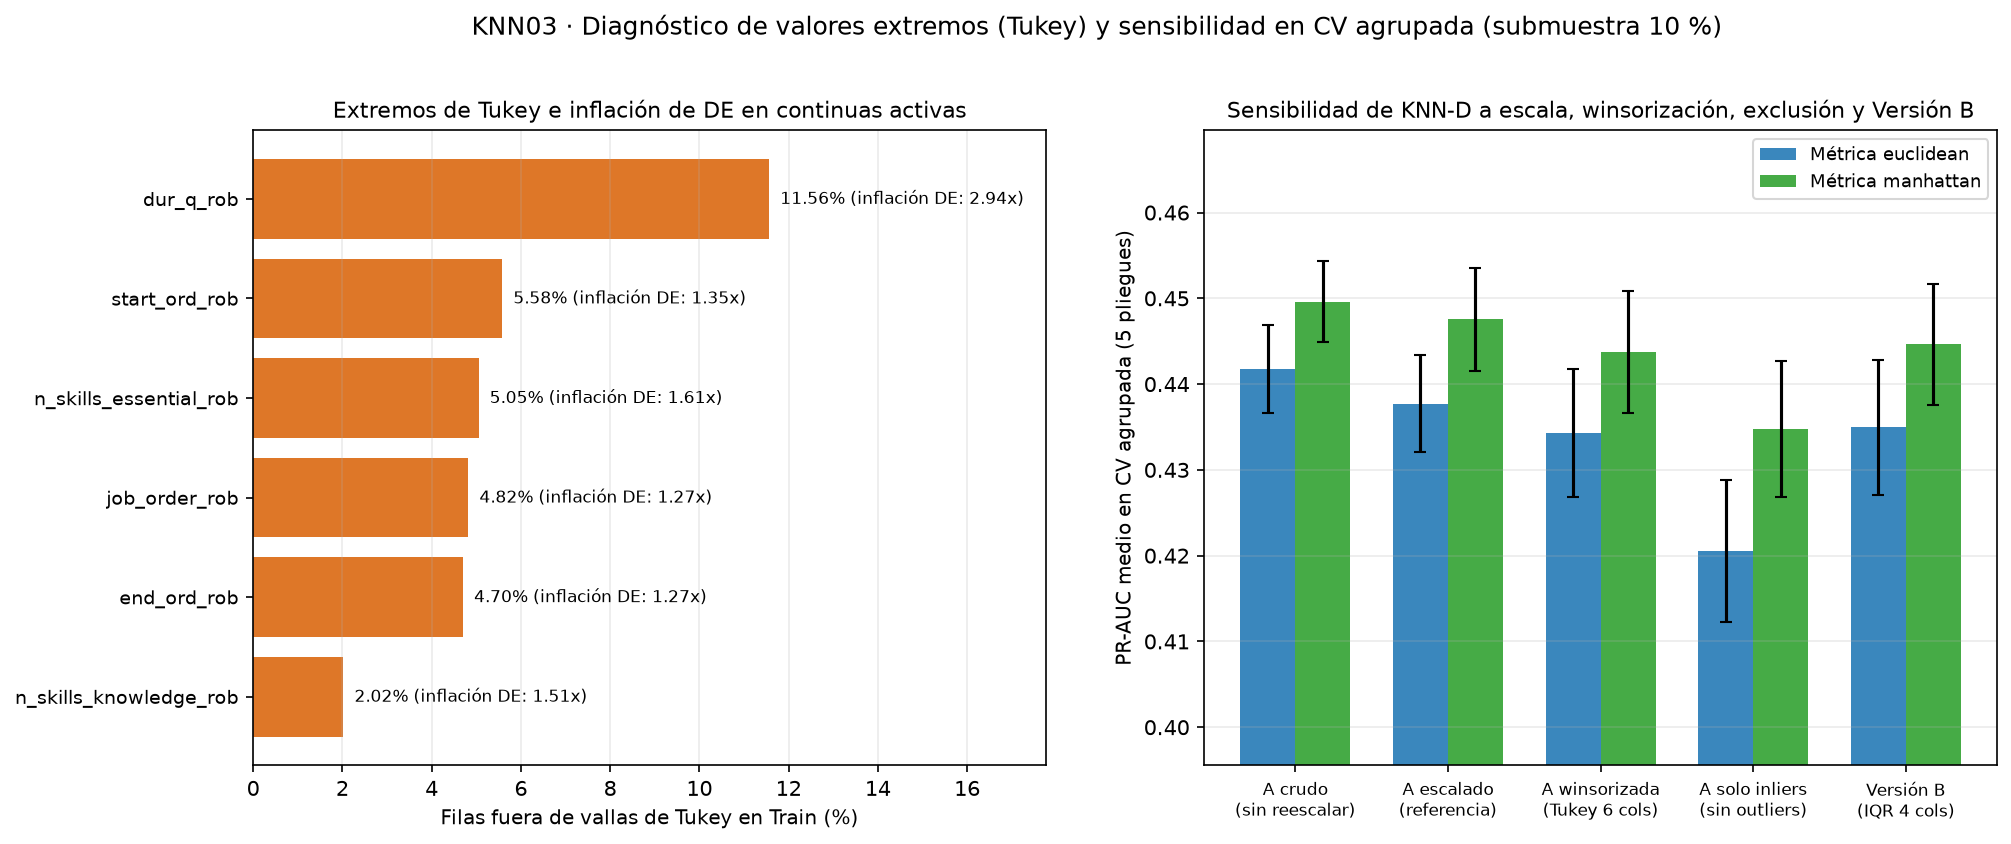

In [5]:
_NESTED_10 = PersonSubsampler(CONFIG.random_state).sample_persons_nested(
    BUNDLE_A.train_blocks.groups, BUNDLE_A.train_blocks.y, (CONFIG.tuning_person_fraction,)
)
TUNING_IDX_10, _ = _NESTED_10[CONFIG.tuning_person_fraction]

# Configuración KNN-D verificada en Sección 7 (se valida coincidencia exacta mediante assert en Sección 7)
KNN_D_SENS_SPEC = KNNModelSpec(
    model_id=MODEL_KNN_D,
    n_neighbors=101,
    weights="uniform",
    metric="manhattan",
    algorithm="kd_tree",
    block_weight=0.0,
    n_jobs=CONFIG.n_jobs,
)

SENS_BUNDLE = PIPELINE.sensitivity_analyzer.run_sensitivity_study(
    train_blocks_a=BUNDLE_A.train_blocks,
    test_blocks_a=BUNDLE_A.test_blocks,
    tuning_row_idx=TUNING_IDX_10,
    knn_d_spec=KNN_D_SENS_SPEC,
)
FIG_KNN03 = PIPELINE.plotter.plot_scale_and_outlier_sensitivity(SENS_BUNDLE)

print("Resumen de filas con extremos Tukey:", SENS_BUNDLE.row_extremes_summary)
print("Identidad exacta del target A vs. B:", SENS_BUNDLE.version_b_target_identity)
display(SENS_BUNDLE.tukey_extremes_table.loc[SENS_BUNDLE.tukey_extremes_table["continua_activa_knn"]])
display(SENS_BUNDLE.version_b_scope_table)
display(SENS_BUNDLE.distance_distortion_table)
display(SENS_BUNDLE.cv_sensitivity_table)
display(SENS_BUNDLE.paired_ci_vs_audited_a_table)
display(SENS_BUNDLE.outlier_free_subgroup_breakdown_table)
display(SENS_BUNDLE.knn_d_full_test_version_b_table)
display(Image(filename=str(FIG_KNN03)))


### Lectura

- **Prevalencia e impacto de los valores extremos Tukey (tablas `04a_auditoria_extremos_tukey_train_test.csv` y `04c_distorsion_distancias_inliers_vs_extremos.csv`, figura `KNN03`):**
  - Ajustando las vallas de Tukey (`Q1 - 1.5*IQR`, `Q3 + 1.5*IQR`) **solo en `train`**, el `25.06 %` de las filas de `train` (`348,621` de `1,391,018`) y el `24.84 %` de las de `test` (`86,373` de `347,720`) presentan al menos un extremo en las `6` continuas activas. La columna más sesgada es `dur_q_rob` (`11.56 %` de extremos en `train`, inflando su desviación estándar en `2.935` veces: `1.7218` total vs. `0.5867` sin extremos), seguida por `start_ord_rob` (`5.58 %`, factor `1.354`), `n_skills_essential_rob` (`5.05 %`, `1.606`), `job_order_rob` (`4.82 %`, `1.266`), `end_ord_rob` (`4.70 %`, `1.272`) y `n_skills_knowledge_rob` (`2.02 %`, `1.509`).
  - La prevalencia de reincidencia entre *inliers* y filas extremas es casi idéntica (`30.18 %` vs. `29.50 %` en `train`; `30.10 %` vs. `29.59 %` en `test`): los extremos no son registros erróneos sino trayectorias laborales reales de larga duración o gran antigüedad.
  - En el espacio escalado de Versión A (`k = 101`, submuestra CV), las filas extremas se ubican a `1.834` veces la distancia mediana de los *inliers* en `euclidean` (`1.2992` vs. `0.7083`) y a `1.922` veces en `manhattan` (`2.3904` vs. `1.2440`). La winsorización Tukey de las `6` continuas reduce esa razón a `1.403` (`euclidean`) y `1.333` (`manhattan`), dejando solo `61.36 %` (`euclidean`) y `64.06 %` (`manhattan`) de solapamiento de vecinos en las filas extremas.
- **Alcance exacto de la Versión B (`sin_outliers`, tabla `04b_alcance_version_b_cotas_iqr.csv`):** de acuerdo con `IQR_WINSOR_BOUNDS_INFO`, la Versión B solo recorta `4` variables (`n_skills_essential`, `n_skills_competence`, `n_skills_knowledge` y `veces_ese_oficio`). Como `n_skills_competence` se excluye por colinealidad y `veces_ese_oficio` por fuga, **únicamente `2` columnas de `X`** difieren entre A y B (`n_skills_essential_rob` y `n_skills_knowledge_rob`). Las columnas `dur_q`, `job_order`, `start_ord` y `end_ord` son idénticas en A y B; por eso Versión B apenas reduce la razón de distancias a `1.696` (`euclidean`) y `1.772` (`manhattan`), conservando `81.58 %`–`84.61 %` de los mismos vecinos en extremos. Además se comprobó que el target `y` es idéntico entre A y B (`True` en `train` y `test`).
- **Prueba empírica central — ¿por qué NO conviene entrenar KNN exclusivamente sin outliers en JobPath? (tablas `04d`, `04e`, `04f` en CV `5` pliegues al `10 %` de `train`, y tabla `04g` en `test` completo):**
  1. **Entrenar exclusivamente sin filas con outliers Tukey (`R4_A_solo_inliers`) degrada significativamente el modelo en todas las métricas:** en CV (`138,783` filas) cae de `PR-AUC = 0.44754` a `0.43476` en `manhattan` (diferencia pareada `-0.01269`, IC 95 % `[-0.01630, -0.00848]`; `ROC-AUC` cae `-0.01003`, `[-0.01224, -0.00774]`) y en `euclidean` la caída es aún más severa (`-0.01734`, `[-0.02148, -0.01238]`, evidenciando que `L2` amplifica cuadráticamente el aislamiento en la frontera, mientras `L1` amortigua las colas).
  2. **Mecanismo demostrado en el desglose OOF (`04f_desglose_oof_sin_outliers_inliers_vs_extremos.csv`, `manhattan`):** eliminar las filas extremas del entrenamiento mejora ligeramente el rendimiento en el bloque de `103,965` *inliers* (`PR-AUC` sube de `0.4353` a `0.4391`), pero **desploma la capacidad predictiva sobre las `34,818` filas extremas reales** (`PR-AUC` cae de `0.4774` a `0.4229` y `ROC-AUC` de `0.6739` a `0.6314`). Un KNN entrenado sin extremos carece de vecinos genuinos para carreras extensas o con muchas rotaciones y las fuerza a votar con vecinos del borde de los *inliers*.
  3. **Winsorización Tukey propia (`R3_A_wins_tukey`) y Versión B (`R5_B_iqr`) en CV:** ambos recortes evitan la pérdida catastrófica de `R4`, mejoran levemente el desempeño en *inliers* (`PR-AUC` `0.4398` y `0.4405`) y suben marginalmente el `ROC-AUC` global (`+0.00092` no distinguible en `manhattan` para Tukey, `[-0.00014, +0.00206]`; `+0.00102` `[+0.00009, +0.00216]` para Versión B), pero **reducen el `PR-AUC` global de forma distinguible** (`-0.00371` `[-0.00574, -0.00081]` para Tukey; `-0.00277` `[-0.00481, -0.00025]` para Versión B) porque comprimen la señal útil de las colas (`PR-AUC` en extremos baja de `0.4774` a `0.4542` y `0.4554`).
  4. **Sensibilidad a la escala (`R1_A_crudo` vs. `R2_A_escalado`):** en CV sobre `KNN-D`, la matriz sin reescalar supera levemente a la escalada (`+0.00208`, `[+0.00049, +0.00367]` en `manhattan`; `+0.00416`, `[+0.00224, +0.00612]` en `euclidean`). Como **hipótesis**, en el bloque crudo la variable educativa `univ_ord_mm` (de muy débil poder discriminante en `7.0`, `ROC-AUC = 0.5208`) tenía `std = 0.2231` y pesaba poco en la distancia, mientras que estandarizarla a `1.0` le otorga igual peso que a la duración o al orden laboral. Se conserva `R2_A_escalado` como base metodológica del cuaderno para evitar ponderaciones accidentales dependientes de la codificación original y garantizar un bloque denso homogéneo frente a los pesos `w_g` y `w`.
  5. **Confirmación en `test` completo (`347,720` filas, `KNN-D`, tabla `04g_knn_d_test_completo_outliers_y_version_b.csv`):** se reproduce fielmente el resultado de CV: frente a `R2_A_escalado` (`PR-AUC = 0.4652`, `ROC-AUC = 0.6677`, `Brier = 0.1936`), entrenar exclusivamente sin outliers (`R4_A_solo_inliers`, `1,042,397` filas de `train`) cae a `PR-AUC = 0.4496` ($\Delta =$ `-0.01561`, IC 95 % `[-0.01780, -0.01350]`, `ROC-AUC = 0.6535`), mientras que `R3_A_wins_tukey` (`0.4628`, $\Delta =$ `-0.00243`, `[-0.00376, -0.00107]`) y `R5_B_iqr` (`0.4634`, $\Delta =$ `-0.00187`, `[-0.00312, -0.00063]`) también pierden ligeramente en `PR-AUC` pese a ganar décimas en `ROC-AUC` (`0.6681` y `0.6692`).
- **Alcance probado y no probado:** las pruebas de escala, winsorización Tukey en `6` continuas, entrenamiento sin outliers y Versión B se ejecutaron en CV agrupada (`L1` y `L2`) y en `test` completo para `KNN-D`. Para `KNN-G` y `KNN-W` **no** se ejecutó la Versión B en `test` completo por el presupuesto de tiempo del Paso 9 (`> 4.0` horas), quedando la Versión A escalada como alcance oficial del resto del cuaderno.


---

## 6. Corrida base (*baseline*), selección de algoritmo exacto y paralelismo (`n_jobs`) en submuestra piloto

**¿Qué hace?** Sobre una submuestra piloto de `train` por persona (`10,000` personas de entrenamiento y `2,500` personas disjuntas de validación), compara los algoritmos exactos (`kd_tree`, `ball_tree` y `brute`) en `euclidean` y `manhattan`, evalúa `n_jobs` en `{1, 2, 4, 8, 12}` controlando el aumento de memoria RSS, y ejecuta la corrida base de `KNN-D`, `KNN-G` y `KNN-W` con hiperparámetros por defecto (`k = 5`, `uniform`, `euclidean`).

**¿Por qué existe?** En KNN el costo se traslada a la predicción y elegir un algoritmo exacto lento o un `n_jobs` que duplique matrices en RAM encarecería innecesariamente el tuning; además, el baseline con `k = 5` documenta el punto de partida y la baja resolución (`6` puntajes distintos) antes de ajustar `k`.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks`. Entrega `PILOT_BUNDLE` con las tablas de algoritmo/`n_jobs`, los algoritmos seleccionados y las métricas y tiempos base.

**Papel en el proyecto.** Establece el motor de búsqueda exacto y el grado de paralelismo seguro antes del ajuste en CV agrupada.


In [6]:
PILOT_BUNDLE = PIPELINE.pilot_runner.run_pilot_selection_and_baseline(
    train_blocks=BUNDLE_A.train_blocks,
    n_jobs_candidates=(1, 2, 4, 8, 12),
    pilot_train_persons=CONFIG.pilot_train_persons,
    pilot_val_persons=CONFIG.pilot_val_persons,
)

print("Resumen del piloto:", PILOT_BUNDLE.pilot_split_info)
display(PILOT_BUNDLE.algorithm_njobs_table)
display(PILOT_BUNDLE.baseline_pilot_table)


Resumen del piloto: {'personas_train_piloto': 10000, 'filas_train_piloto': 49537, 'prevalencia_train_piloto_pct': 30.62, 'personas_val_piloto': 2500, 'filas_val_piloto': 12403, 'prevalencia_val_piloto_pct': 29.9, 'algoritmos_seleccionados': {'KNN-W': 'brute', 'KNN-D': 'kd_tree', 'KNN-G': 'brute'}, 'n_jobs_seleccionado': 8}


,experimento,modelo_id,metrica,algoritmo,n_jobs,n_train_piloto,n_val_piloto,tiempo_fit_s,tiempo_predict_s,ms_por_1000_filas,rss_antes_mb,rss_despues_mb,delta_rss_mb,max_diff_vs_ref
0,"Algoritmo exacto (euclidean, k=51)",KNN-D,euclidean,kd_tree,4,49537,12403,0.0773,0.5365,43.2600,"1,745.0000","1,749.4000",4.4000,0.0000
1,"Algoritmo exacto (euclidean, k=51)",KNN-D,euclidean,ball_tree,4,49537,12403,0.0527,4.0513,326.6400,"1,749.4000","1,749.4000",0.0000,0.0196
2,"Algoritmo exacto (euclidean, k=51)",KNN-D,euclidean,brute,4,49537,12403,0.0018,0.4815,38.8200,"1,749.4000","1,745.2000",-4.2000,0.0392
3,"Algoritmo exacto (manhattan, k=51)",KNN-D,manhattan,kd_tree,4,49537,12403,0.0983,0.9007,72.6200,"1,745.2000","1,749.5000",4.2000,0.0000
4,"Algoritmo exacto (manhattan, k=51)",KNN-D,manhattan,ball_tree,4,49537,12403,0.0477,3.4740,280.0900,"1,749.5000","1,749.7000",0.2000,0.0392
5,"Algoritmo exacto (manhattan, k=51)",KNN-D,manhattan,brute,4,49537,12403,0.0016,1.3204,106.4500,"1,749.7000","1,745.6000",-4.1000,0.0392
6,"Algoritmo exacto (euclidean, k=51)",KNN-G,euclidean,kd_tree,4,49537,12403,0.1585,1.2773,102.9800,"1,745.6000","1,754.7000",9.1000,0.0000
7,"Algoritmo exacto (euclidean, k=51)",KNN-G,euclidean,ball_tree,4,49537,12403,0.0903,6.4995,524.0300,"1,754.7000","1,754.7000",0.0000,0.0392
8,"Algoritmo exacto (euclidean, k=51)",KNN-G,euclidean,brute,4,49537,12403,0.0017,0.5536,44.6400,"1,754.7000","1,745.5000",-9.2000,0.0392
9,"Algoritmo exacto (manhattan, k=51)",KNN-G,manhattan,kd_tree,4,49537,12403,0.1648,1.9730,159.0800,"1,745.5000","1,754.4000",8.9000,0.0000


,modelo_id,modelo,hiperparametros_base,n_columnas,n_train_piloto,n_val_piloto,puntajes_unicos_k5,pr_auc_piloto,roc_auc_piloto,f1_clase_1_050,recall_050,precision_050,brier_piloto,accuracy_050,tiempo_fit_s,tiempo_predict_s,ms_por_1000_filas,memoria_matriz_train_mb,rss_proceso_mb
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),"k=5, uniform, euclidean, algo=kd_tree",11,49537,12403,6,0.3745,0.5998,0.3557,0.3082,0.4205,0.2295,0.6661,0.0747,0.1959,15.7900,2.0800,"1,751.7000"
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),"k=5, uniform, euclidean, algo=brute, peso_bloque=1",21,49537,12403,6,0.4019,0.6273,0.4013,0.3551,0.4613,0.2229,0.6831,0.0015,0.4362,35.1700,3.9700,"1,748.3000"
2,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)","k=5, uniform, euclidean, algo=brute, peso_bloque=1",2978,49537,12403,6,0.4002,0.6312,0.4046,0.3705,0.4457,0.2248,0.6739,0.0037,10.5515,850.7200,4.3300,"1,749.8000"


### Lectura

- **Submuestra piloto por persona (`train`):** `10,000` personas (`49,537` filas, prevalencia `30.62 %`) para ajuste y `2,500` personas disjuntas (`12,403` filas, prevalencia `29.90 %`) para validación, con `0` personas compartidas.
- **Comparación de algoritmos exactos (`05a_piloto_algoritmo_y_n_jobs.csv`, `k = 51`):**
  - `ball_tree` resultó consistentemente el algoritmo más lento en las pruebas del piloto (`326.64 ms` por `1,000` consultas en `KNN-D euclidean`, `280.09 ms/1k` en `manhattan`; `524.03` y `432.97 ms/1k` en `KNN-G`), por lo que queda descartado.
  - En `KNN-D` (`11` cols), `kd_tree` supera a `brute` en `manhattan` (`72.62` frente a `106.45 ms/1k`) y se mantiene muy cercano en `euclidean` (`43.26` vs. `38.82 ms/1k`), por lo que el piloto selecciona `kd_tree`. En `KNN-G` (`21` cols) a escala de `49,537` filas, `brute` aventaja a `kd_tree` (`44.64` vs. `102.98 ms/1k` en `euclidean`; `153.68` vs. `159.08 ms/1k` en `manhattan`), así que el tuning al `10 %` utiliza `brute` (y la Sección 9 reevalúa `kd_tree` al escalar a `1,391,018` filas). En `KNN-W` (matriz dispersa CSR de `2,978` cols), `scikit-learn` solo admite `brute`. Las pequeñas diferencias `max_diff_vs_ref` (`0.0196` a `0.0588`, equivalentes a `1`–`3` votos de `51`) provienen únicamente del orden de desempate entre vecinos a idéntica distancia en el borde `d_k`.
- **Selección de paralelismo (`n_jobs`):** al subir `n_jobs` de `1` a `8`, el tiempo por `1,000` filas baja de `60.53` a `35.70 ms` en `KNN-D` y de `985.11` a `861.29 ms` en `KNN-W`, sin duplicación de memoria (el RSS se mantiene estable en torno a `1750 MB`, con variaciones menores a `5 MB`). Subir a `12` hilos no mejora sobre `8` (`53.88` y `861.71 ms/1k`), por lo que se fija `n_jobs = 8`. El escaso factor de aceleración en `KNN-W` anticipa el cuello de botella de fuerza bruta CSR en Python/`scikit-learn`.
- **Corrida base (*baseline*) con `k = 5` por defecto (`05b_baseline_piloto_k5.csv`, validación piloto):** `KNN-D` parte de `PR-AUC = 0.3745` (`ROC-AUC = 0.5998`, `Brier = 0.2295`), `KNN-G` de `0.4019` (`ROC-AUC = 0.6273`, `Brier = 0.2229`) y `KNN-W` de `0.4002` (`ROC-AUC = 0.6312`, `Brier = 0.2248`). Con `k = 5` las tres variantes producen apenas `6` puntajes distintos y un `F1` pobre a umbral `0.50` (`0.3557` a `0.4046`), mostrando cuánto espacio hay para mejorar al ajustar `k`, el peso ocupacional y el umbral.


---

## 7. Ajuste honesto (*tuning*) en submuestra por persona, resolución `1/k` y curvas de aprendizaje

**¿Qué hace?** Toma la submuestra determinista del `10 %` de personas de `train` (`28,167` personas, conservando todas sus experiencias), ejecuta validación cruzada agrupada `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` por `resume_id` (`0` personas solapadas), evalúa toda la rejilla de `k`, `weights`, `metric` y pesos de bloque `w_g`/`w` (extendiendo automáticamente si el óptimo cae en un borde), analiza la resolución de puntaje `1/k` y repite las `3` mejores configuraciones de cada variante al `10 %`, `25 %` y `50 %` de personas para verificar estabilidad (`5-fold CV` en `KNN-D`/`KNN-G`; en `KNN-W` se usa el **mismo pliegue único disjunto por persona** de `~28k` filas en los tres puntos `10 %`, `25 %` y `50 %` con IC 95 % por bootstrap de personas y comparaciones pareadas, manteniendo intactos el ajuste principal y el umbral OOF sobre el `5-fold` completo al `10 %`).

**¿Por qué existe?** Los pliegues agrupados por persona son obligatorios porque las experiencias de un mismo currículum son casi duplicados y filtrarían información en un split aleatorio. La curva de aprendizaje verifica si el `k` y los pesos elegidos al `10 %` se mantienen estables al crecer los datos.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks` y los parámetros del piloto. Entrega `TUNING_BUNDLE` (intentos completos, ganadores, tabla de resolución `1/k` y curva de aprendizaje) y las figuras `knn04` y `knn05`.

**Papel en el proyecto.** Define los hiperparámetros definitivos de `KNN-D`, `KNN-G` y `KNN-W` estrictamente sobre `train` y sin tocar `test`.


[Tuning KNN-D] Rejilla base | metric=euclidean | bw=0 | max_k=401 | best PR-AUC=0.43799 | 0.0s


[Tuning KNN-D] Rejilla base | metric=manhattan | bw=0 | max_k=401 | best PR-AUC=0.44780 | 0.0s


[Tuning KNN-G] Rejilla base | metric=euclidean | bw=0.25 | max_k=401 | best PR-AUC=0.44657 | 0.0s


[Tuning KNN-G] Rejilla base | metric=euclidean | bw=0.5 | max_k=401 | best PR-AUC=0.45605 | 0.0s


[Tuning KNN-G] Rejilla base | metric=euclidean | bw=1 | max_k=401 | best PR-AUC=0.46428 | 0.0s


[Tuning KNN-G] Rejilla base | metric=euclidean | bw=2 | max_k=401 | best PR-AUC=0.46471 | 0.0s


... (24 outputs left out)

,modelo_id,intento_num,etapa_rejilla,algoritmo,metrica,peso_bloque,k_vecinos,pesos,resolucion_teorica_1_sobre_k,puntajes_unicos_oof,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,roc_auc_cv_std,f1_cv_050,recall_cv_050,precision_cv_050,brier_cv,tiempo_fold_kmax_s
0,KNN-D,1,Rejilla base,kd_tree,manhattan,0.0000,101,uniform,0.0099,89,0.4478,0.0067,0.6493,0.0050,0.2324,0.1459,0.5709,0.1975,15.5990
1,KNN-D,2,Rejilla base,kd_tree,manhattan,0.0000,201,uniform,0.0050,161,0.4467,0.0059,0.6494,0.0049,0.1981,0.1191,0.5895,0.1977,15.5990
2,KNN-D,3,Rejilla base,kd_tree,manhattan,0.0000,401,uniform,0.0025,283,0.4451,0.0048,0.6485,0.0042,0.1573,0.0906,0.6020,0.1981,15.5990
3,KNN-D,4,Rejilla base,kd_tree,manhattan,0.0000,51,uniform,0.0196,48,0.4417,0.0058,0.6457,0.0055,0.2647,0.1745,0.5483,0.1986,15.5990
4,KNN-D,5,Rejilla base,kd_tree,euclidean,0.0000,101,uniform,0.0099,90,0.4380,0.0063,0.6426,0.0048,0.2124,0.1311,0.5605,0.1989,11.2490
24,KNN-G,1,Extensión de borde (peso superior),brute,manhattan,8.0000,101,uniform,0.0099,92,0.4730,0.0066,0.6704,0.0047,0.3212,0.2231,0.5730,0.1937,21.3560
25,KNN-G,2,Rejilla base,brute,manhattan,4.0000,101,uniform,0.0099,91,0.4729,0.0066,0.6704,0.0046,0.3214,0.2233,0.5731,0.1938,21.2700
26,KNN-G,3,Rejilla base,brute,manhattan,2.0000,101,uniform,0.0099,89,0.4729,0.0066,0.6704,0.0048,0.3214,0.2234,0.5727,0.1938,21.1680
27,KNN-G,4,Rejilla base,brute,manhattan,1.0000,101,uniform,0.0099,88,0.4727,0.0067,0.6699,0.0047,0.3206,0.2228,0.5719,0.1939,20.9160
28,KNN-G,5,Rejilla base,brute,manhattan,4.0000,201,uniform,0.0050,159,0.4721,0.0058,0.6695,0.0038,0.2976,0.1999,0.5823,0.1940,21.2700


,modelo_id,pesos,k_vecinos,resolucion_1_sobre_k,puntajes_unicos_oof,pr_auc_cv_media,roc_auc_cv_media,brier_cv
24,KNN-W,distance,5,0.2000,69335,0.4174,0.6321,0.2417
25,KNN-W,distance,15,0.0667,96706,0.4415,0.6512,0.2192
26,KNN-W,distance,51,0.0196,106364,0.4558,0.6606,0.2102
27,KNN-W,distance,101,0.0099,105529,0.4583,0.6624,0.2087
28,KNN-W,distance,201,0.0050,103957,0.4585,0.6620,0.2086
29,KNN-W,distance,401,0.0025,102163,0.4565,0.6600,0.2094
30,KNN-W,uniform,5,0.2000,6,0.4160,0.6478,0.2213
31,KNN-W,uniform,15,0.0667,16,0.4690,0.6830,0.1966
32,KNN-W,uniform,51,0.0196,49,0.4980,0.6955,0.1891
33,KNN-W,uniform,101,0.0099,92,0.5008,0.6943,0.1889


,modelo_id,esquema_validacion,fraccion_personas_pct,personas_train,filas_train,rango_en_10pct,config_etiqueta,k_vecinos,pesos,metrica,peso_bloque,pr_auc_cv_media,pr_auc_cv_std,pr_auc_ic95_persona,pr_auc_ic95_inf,pr_auc_ic95_sup,roc_auc_cv_media,roc_auc_ic95_persona,brier_cv
0,KNN-D,StratifiedGroupKFold (5 pliegues),10.0000,28167,138783,1,"k=101, uniform, manhattan",101,uniform,manhattan,0.0000,0.4478,0.0067,5-fold CV (ver std),NaN,NaN,0.6493,5-fold CV,0.1975
1,KNN-D,StratifiedGroupKFold (5 pliegues),10.0000,28167,138783,2,"k=201, uniform, manhattan",201,uniform,manhattan,0.0000,0.4467,0.0059,5-fold CV (ver std),NaN,NaN,0.6494,5-fold CV,0.1977
2,KNN-D,StratifiedGroupKFold (5 pliegues),10.0000,28167,138783,3,"k=401, uniform, manhattan",401,uniform,manhattan,0.0000,0.4451,0.0048,5-fold CV (ver std),NaN,NaN,0.6485,5-fold CV,0.1981
3,KNN-D,StratifiedGroupKFold (5 pliegues),25.0000,70418,348241,1,"k=101, uniform, manhattan",101,uniform,manhattan,0.0000,0.4532,0.0032,5-fold CV (ver std),NaN,NaN,0.6562,5-fold CV,0.1961
4,KNN-D,StratifiedGroupKFold (5 pliegues),25.0000,70418,348241,2,"k=201, uniform, manhattan",201,uniform,manhattan,0.0000,0.4541,0.0036,5-fold CV (ver std),NaN,NaN,0.6564,5-fold CV,0.1961
5,KNN-D,StratifiedGroupKFold (5 pliegues),25.0000,70418,348241,3,"k=401, uniform, manhattan",401,uniform,manhattan,0.0000,0.4514,0.0034,5-fold CV (ver std),NaN,NaN,0.6546,5-fold CV,0.1966
6,KNN-D,StratifiedGroupKFold (5 pliegues),50.0000,140837,695615,1,"k=101, uniform, manhattan",101,uniform,manhattan,0.0000,0.4580,0.0028,5-fold CV (ver std),NaN,NaN,0.6619,5-fold CV,0.1944
7,KNN-D,StratifiedGroupKFold (5 pliegues),50.0000,140837,695615,2,"k=201, uniform, manhattan",201,uniform,manhattan,0.0000,0.4592,0.0034,5-fold CV (ver std),NaN,NaN,0.6620,5-fold CV,0.1943
8,KNN-D,StratifiedGroupKFold (5 pliegues),50.0000,140837,695615,3,"k=401, uniform, manhattan",401,uniform,manhattan,0.0000,0.4569,0.0037,5-fold CV (ver std),NaN,NaN,0.6601,5-fold CV,0.1948
9,KNN-G,StratifiedGroupKFold (5 pliegues),10.0000,28167,138783,1,"k=101, uniform, manhattan, w=8",101,uniform,manhattan,8.0000,0.4730,0.0066,5-fold CV (ver std),NaN,NaN,0.6704,5-fold CV,0.1937


,fraccion_personas_pct,n_val_pliegue_fijo,personas_val_pliegue_fijo,comparacion_A_menos_B,delta_pr_auc,ic95_delta_pr_auc,pr_auc_excluye_cero,veredicto_pr_auc,delta_roc_auc,ic95_delta_roc_auc,veredicto_roc_auc
0,10.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 2 (k=101, uniform, euclidean, w=4)",0.0008,"[+0.00014, +0.00145]",True,Diferencia distinguible (IC 95 % excluye 0),0.0012,"[+0.00041, +0.00192]",Diferencia distinguible (IC 95 % excluye 0)
1,10.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 3 (k=201, uniform, euclidean, w=8)",0.0014,"[-0.00192, +0.00476]",False,No se distingue (IC 95 % incluye 0),0.0038,"[+0.00062, +0.00693]",Diferencia distinguible (IC 95 % excluye 0)
2,25.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 2 (k=101, uniform, euclidean, w=4)",0.0006,"[+0.00012, +0.00119]",True,Diferencia distinguible (IC 95 % excluye 0),0.0010,"[+0.00031, +0.00171]",Diferencia distinguible (IC 95 % excluye 0)
3,25.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 3 (k=201, uniform, euclidean, w=8)",0.0017,"[-0.00103, +0.00413]",False,No se distingue (IC 95 % incluye 0),0.0048,"[+0.00223, +0.00714]",Diferencia distinguible (IC 95 % excluye 0)
4,50.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 2 (k=101, uniform, euclidean, w=4)",0.0006,"[-0.00008, +0.00118]",False,No se distingue (IC 95 % incluye 0),0.0004,"[-0.00045, +0.00125]",No se distingue (IC 95 % incluye 0)
5,50.0000,27756,5694,"Top 1 (k=101, uniform, euclidean, w=8) menos Top 3 (k=201, uniform, euclidean, w=8)",-0.0011,"[-0.00366, +0.00143]",False,No se distingue (IC 95 % incluye 0),0.0025,"[+0.00054, +0.00452]",Diferencia distinguible (IC 95 % excluye 0)


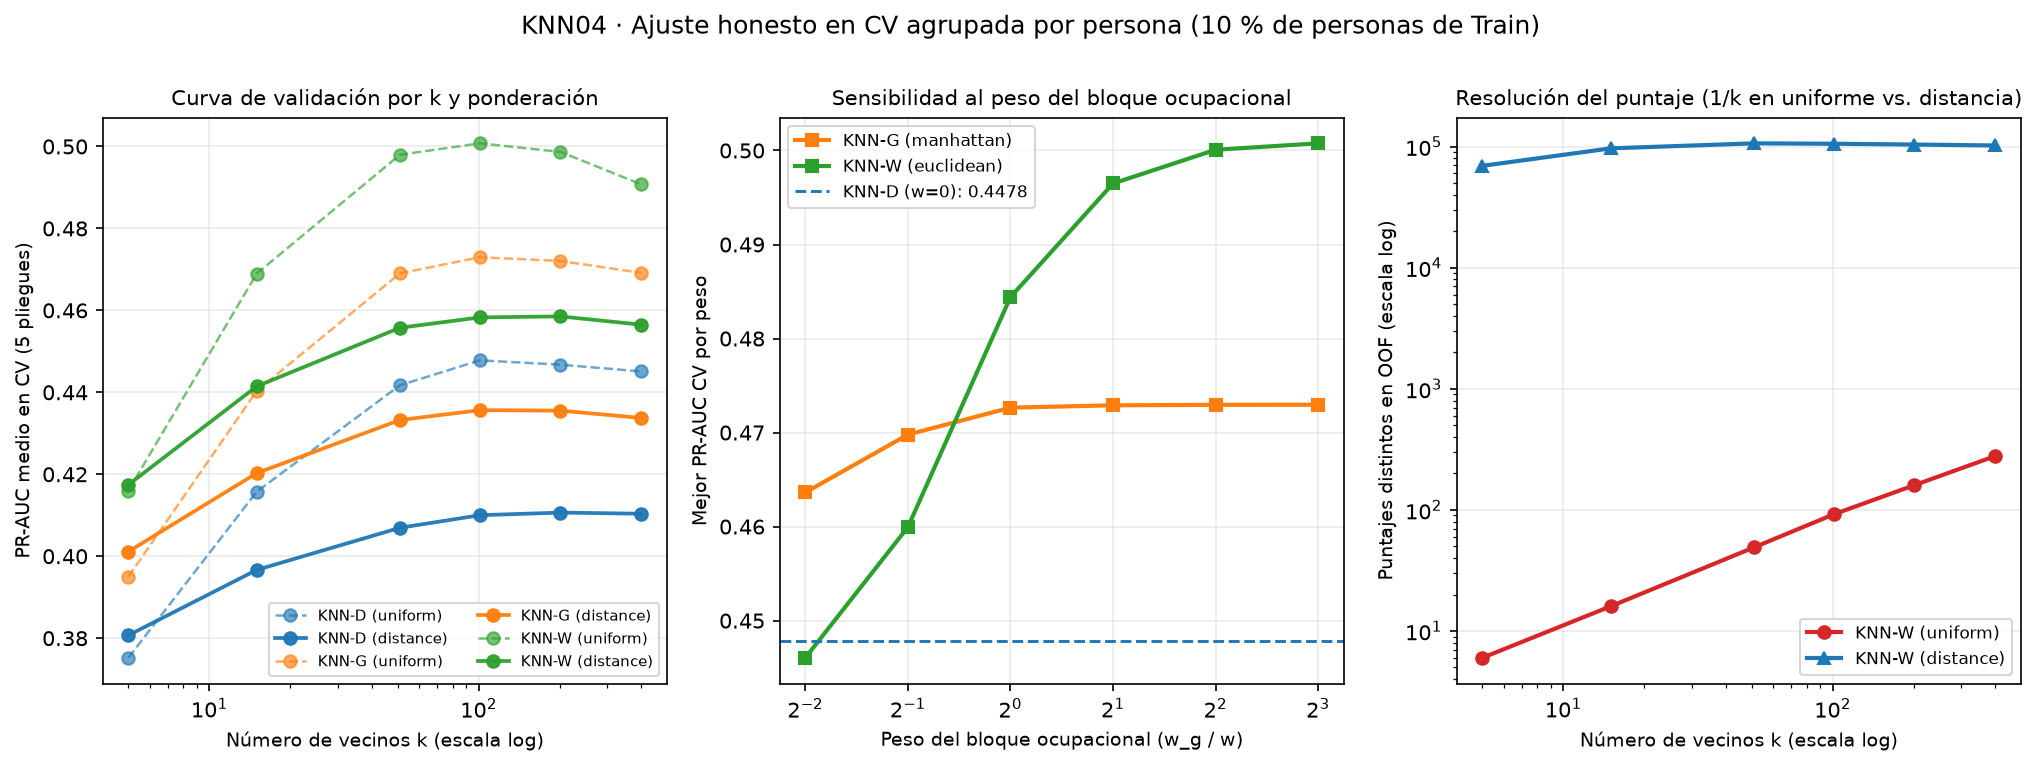

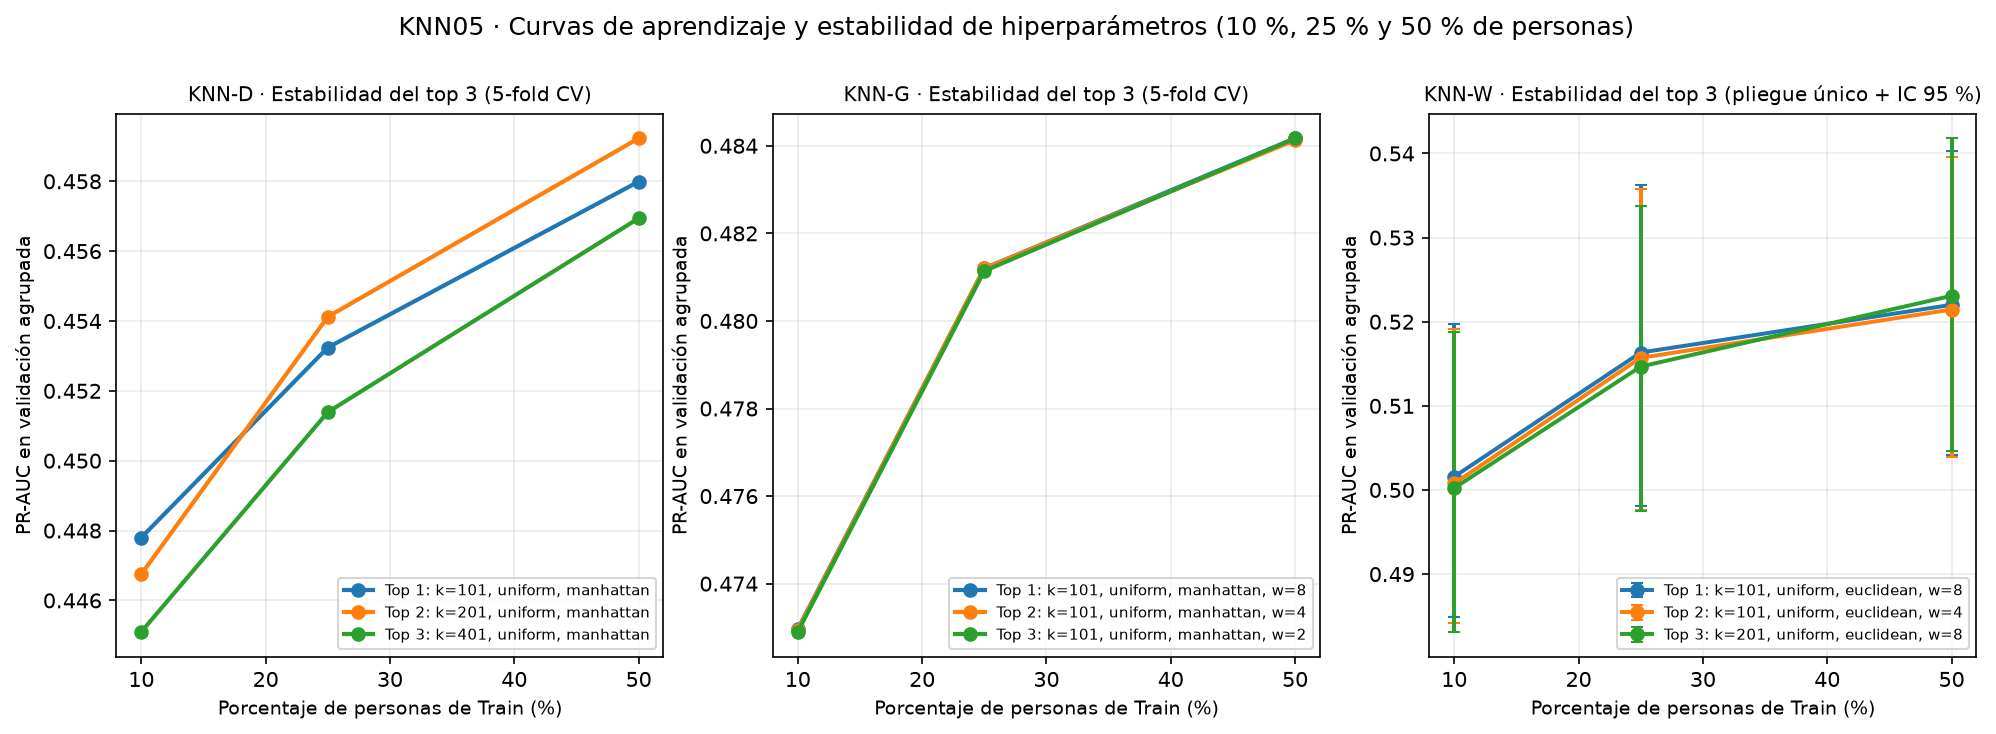

In [7]:
TUNING_BUNDLE = PIPELINE.evaluator.run_honest_tuning_and_learning_curve(
    train_blocks=BUNDLE_A.train_blocks,
    selected_algorithms=PILOT_BUNDLE.selected_algorithms,
    selected_n_jobs=PILOT_BUNDLE.selected_n_jobs,
    tuning_fraction=CONFIG.tuning_person_fraction,
    learning_curve_fractions=CONFIG.learning_curve_fractions,
    extend_edges=True,
    force_recompute_cache=False,
    verbose=True,
)

# Validar que la configuración auditada en Sección 5 coincide exactamente con el ganador de KNN-D
_win_d = TUNING_BUNDLE.winner_specs[MODEL_KNN_D]
assert (
    _win_d.n_neighbors == KNN_D_SENS_SPEC.n_neighbors
    and _win_d.weights == KNN_D_SENS_SPEC.weights
    and _win_d.metric == KNN_D_SENS_SPEC.metric
), f"Discrepancia entre KNN-D auditado en Sec. 5 y ganador Sec. 7: {_win_d}"

FIG_KNN04 = PIPELINE.plotter.plot_tuning_validation_curves(TUNING_BUNDLE)
FIG_KNN05 = PIPELINE.plotter.plot_learning_curves(TUNING_BUNDLE)

print(
    f"Intentos totales evaluados: {len(TUNING_BUNDLE.tuning_all_attempts_table)} | "
    f"Personas solapadas entre pliegues CV: {TUNING_BUNDLE.cv_person_overlap_count}"
)
display(TUNING_BUNDLE.subsample_summary_table)
display(TUNING_BUNDLE.tuning_winners_table)
display(TUNING_BUNDLE.tuning_all_attempts_table.groupby("modelo_id").head(5))
display(TUNING_BUNDLE.score_resolution_table.loc[TUNING_BUNDLE.score_resolution_table["modelo_id"] == MODEL_KNN_W])
display(TUNING_BUNDLE.learning_curve_table)
display(TUNING_BUNDLE.learning_curve_knn_w_paired_table)
display(Image(filename=str(FIG_KNN04)))
display(Image(filename=str(FIG_KNN05)))


### Lectura

- **Submuestras por persona y ausencia de fuga (`06a_submuestras_personas_resumen.csv`):** las submuestras anidadas de `train` al `10 %` (`28,167` personas, `138,783` filas, prevalencia `30.19 %`, brecha `+0.178 pp` frente al `30.01 %` total), `25 %` (`70,418` personas, `348,241` filas, `30.08 %`) y `50 %` (`140,837` personas, `695,615` filas, `29.90 %`) reproducen fielmente la prevalencia global. La validación cruzada `StratifiedGroupKFold(5)` registró exactamente `0` personas solapadas entre pliegues.
- **Resultados del ajuste honesto en `5-fold CV` al `10 %` (`228` intentos en `06b`, ganadores en `06c_tuning_ganadores_cv.csv`, figura `KNN04`):**
  - **`KNN-D` (`24` intentos):** gana `k = 101`, `uniform`, `manhattan` (`kd_tree`) con `PR-AUC CV = 0.44780` (`std = 0.00670`), `ROC-AUC CV = 0.64932`, `Brier = 0.1975`. La métrica `manhattan` (`0.44780`) aventaja con claridad a `euclidean` (`0.43799`), en línea con la mayor robustez de `L1` frente a las colas pesadas del bloque denso vistas en la Sección 5.
  - **`KNN-G` (`132` intentos):** como el óptimo de la rejilla base cayó en el borde superior `w_g = 4.0` (`0.47295`), se extendió a `w_g = 8.0`, quedando como ganador `k = 101`, `uniform`, `manhattan`, `w_g = 8.0` con `PR-AUC CV = 0.47296` (`std = 0.00662`), `ROC-AUC CV = 0.67044` y `Brier = 0.1937` (virtualmente empatado con `w_g = 4.0` `0.47295` y `w_g = 2.0` `0.47290`, señal de saturación una vez que la pureza ISCO alcanza `99.72 %`–`99.99 %`). También aquí `manhattan` (`0.47296`) supera a `euclidean` (`0.46480`).
  - **`KNN-W` (`72` intentos):** al tocar el borde superior `w = 4.0` (`0.50008`), la extensión a `w = 8.0` mejoró hasta `PR-AUC CV = 0.50076` (`std = 0.00559`), `ROC-AUC CV = 0.69430` y `Brier = 0.1889`, con `k = 101`, `uniform` y `euclidean`.
- **Superioridad de pesos uniformes y efecto de la resolución `1/k` (`06d_resolucion_puntaje_1_sobre_k.csv`):** en las tres variantes, `weights="uniform"` supera holgadamente a `weights="distance"` (en `KNN-W` `k = 101`: `PR-AUC = 0.50076` y `Brier = 0.1889` frente a `0.45828` y `0.2087` con `distance`; en `KNN-D`: `0.44780` vs. `0.41001`). La causa geométrica es la presencia de vecinos con distancia cero o muy pequeña (Sección 4), donde ponderar por `1/d` concentra casi todo el voto en muy pocos casos y degrada calibración y ranking. Con `uniform`, subir `k` desde `5` (`6` puntajes únicos, `KNN-W` `PR-AUC = 0.41601`) hasta `15` (`16` puntajes, `0.46899`), `51` (`49` puntajes, `0.49798`) y `101` (`92` puntajes únicos OOF, resolución `0.0099`, `0.50076`) elimina la discretización gruesa; por encima de `101` (`k = 201`: `0.49868`; `k = 401`: `0.49076`) las vecindades pierden localidad.
- **Curva de aprendizaje (`10 %`, `25 %` y `50 %` de personas) y estabilidad con protocolo unificado en `KNN-W` (`06e`, `06f`, figura `KNN05`):**
  - Las tres variantes ganan `PR-AUC` de manera sostenida al aumentar el número de personas de referencia: en `5-fold CV`, `KNN-D` pasa de `0.44780` (`10 %`) a `0.45412` (`25 %`, `k = 201`) y `0.45923` (`50 %`, `k = 201`), mostrando un leve desplazamiento de `k = 101` (`0.45799` al `50 %`) hacia `k = 201` dentro del margen de desviación entre pliegues (`0.00276`–`0.00345`). `KNN-G` crece de `0.47296` (`10 %`) a `0.48120` (`25 %`) y `0.48417` (`50 %`), con empate técnico entre `w_g = 2`, `4` y `8`.
  - **Protocolo unificado en `KNN-W`:** los tres tamaños (`10 %`, `25 %` y `50 %`) se evaluaron sobre **el mismo pliegue único fijo disjunto por persona** (`27,756` filas de `5,694` personas; `111,027`, `320,485` y `667,859` filas de referencia) para no mezclar el efecto del tamaño con un cambio de protocolo. Bajo este protocolo constante, `Top 1 (k=101, uniform, euclidean, w=8)` asciende claramente con el tamaño: `0.50158` (`[0.48493, 0.51969]`) al `10 %`, `0.51634` (`[0.49805, 0.53630]`) al `25 %` y `0.52201` (`[0.50418, 0.54027]`) al `50 %`.
  - **Comparación pareada por bootstrap de personas en ese mismo pliegue (`06f_curva_aprendizaje_knn_w_bootstrap_pareado.csv`):** al `10 %` y al `25 %`, `Top 1 (k=101, w=8)` supera por un margen mínimo pero distinguible a `Top 2 (k=101, w=4)` (`+0.00079`, `[+0.00014, +0.00145]` al `10 %`; `+0.00062`, `[+0.00012, +0.00119]` al `25 %`), mientras que frente a `Top 3 (k=201, w=8)` **no se distingue** en `PR-AUC` (`+0.00135`, `[-0.00192, +0.00476]` al `10 %`; `+0.00167`, `[-0.00103, +0.00413]` al `25 %`). Al `50 %`, aunque el puntaje puntual de `Top 3` (`0.52308`) queda levemente arriba de `Top 1` (`0.52201`), el IC 95 % pareado cruza el cero tanto frente a `Top 2` (`+0.00056`, `[-0.00008, +0.00118]`) como frente a `Top 3` (`-0.00107`, `[-0.00366, +0.00143]`): **no se distingue** un ganador en `PR-AUC` entre las `3` configuraciones al `50 %` (en `ROC-AUC`, `k = 101` mantiene una ventaja distinguible de `+0.00251`, `[+0.00054, +0.00452]` sobre `k = 201`).
  - **Consistencia metodológica preservada:** el ajuste principal de hiperparámetros de `KNN-W` (`k = 101`, `uniform`, `euclidean`, `w = 8`) y la selección de umbral OOF de la Sección 10 provienen **exclusivamente del `5-fold CV` completo al `10 %`**, nunca del pliegue único.


---

## 8. Curvas de costo computacional (tiempo y memoria RSS)

**¿Qué hace?** Mide el tiempo de `fit`, el tiempo de predicción por `1,000` consultas y la memoria RSS pico para `KNN-D`, `KNN-G` y `KNN-W` al crecer el tamaño de entrenamiento (`10,000` a `400,000` filas, con `2,000` consultas de personas disjuntas y `k = 101`), ajusta las pendientes empíricas en escala log-log y genera la figura `KNN06`.

**¿Por qué existe?** Cuantifica la principal desventaja operativa de KNN frente a los árboles (`7.0`) y Naive Bayes (`7.1`): mientras los modelos paramétricos y de árboles predicen en tiempo constante respecto a `N_train`, la búsqueda exacta en alta dimensión dispersa crece linealmente con el tamaño de la base histórica.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks` y los algoritmos del piloto. Entrega `COST_BUNDLE` (mediciones y pendientes log-log) y `knn06_curvas_costo_computacional.png`.

**Papel en el proyecto.** Sustenta con exponentes empíricos la discusión de escalabilidad y costos para JobPath en la Sección 14.


,modelo_id,modelo,algoritmo,n_columnas,n_train,n_queries,k_vecinos,tiempo_fit_s,tiempo_predict_s,s_por_1000_filas,memoria_matriz_train_mb,rss_proceso_mb
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),kd_tree,11,10000,2000,101,0.0124,0.0806,0.0403,0.4200,"1,656.8000"
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),brute,21,10000,2000,101,0.0011,0.0639,0.0320,0.8000,"1,652.0000"
2,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",brute,2978,10000,2000,101,0.0015,0.3845,0.1923,0.8700,"1,654.9000"
3,KNN-D,KNN-D · Bloque denso auditado (11 cols),kd_tree,11,25000,2000,101,0.0452,0.1343,0.0672,1.0500,"1,641.5000"
4,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),brute,21,25000,2000,101,0.0012,0.0997,0.0498,2.0000,"1,636.5000"
5,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",brute,2978,25000,2000,101,0.0030,0.8943,0.4472,2.1800,"1,646.3000"
6,KNN-D,KNN-D · Bloque denso auditado (11 cols),kd_tree,11,50000,2000,101,0.0781,0.1025,0.0512,2.1000,"1,649.5000"
7,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),brute,21,50000,2000,101,0.0018,0.1336,0.0668,4.0100,"1,641.5000"
8,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",brute,2978,50000,2000,101,0.0037,1.7425,0.8712,4.3700,"1,647.9000"
9,KNN-D,KNN-D · Bloque denso auditado (11 cols),kd_tree,11,100000,2000,101,0.2009,0.1515,0.0757,4.2000,"1,668.8000"


,modelo_id,algoritmo,n_columnas,pendiente_log_log_b,intercepto_log10,r2_ajuste_log_log,s_por_1k_en_n_min,s_por_1k_en_n_max,factor_crecimiento_tiempo,rss_pico_mb,interpretacion_escala
0,KNN-D,kd_tree,11,0.2258,-2.2677,0.8158,0.0403,0.1049,2.6000,"1,763.2000",Sublineal (búsqueda exacta en árbol)
1,KNN-G,brute,21,0.6371,-4.1021,0.9799,0.0320,0.3362,10.5100,"1,720.4000",Sublineal aparente por overhead inicial (fuerza bruta densa)
2,KNN-W,brute,2978,0.9930,-4.7092,0.9992,0.1923,7.4672,38.8300,"1,754.1000",Cuasilineal O(N) (fuerza bruta / alta dimensión)


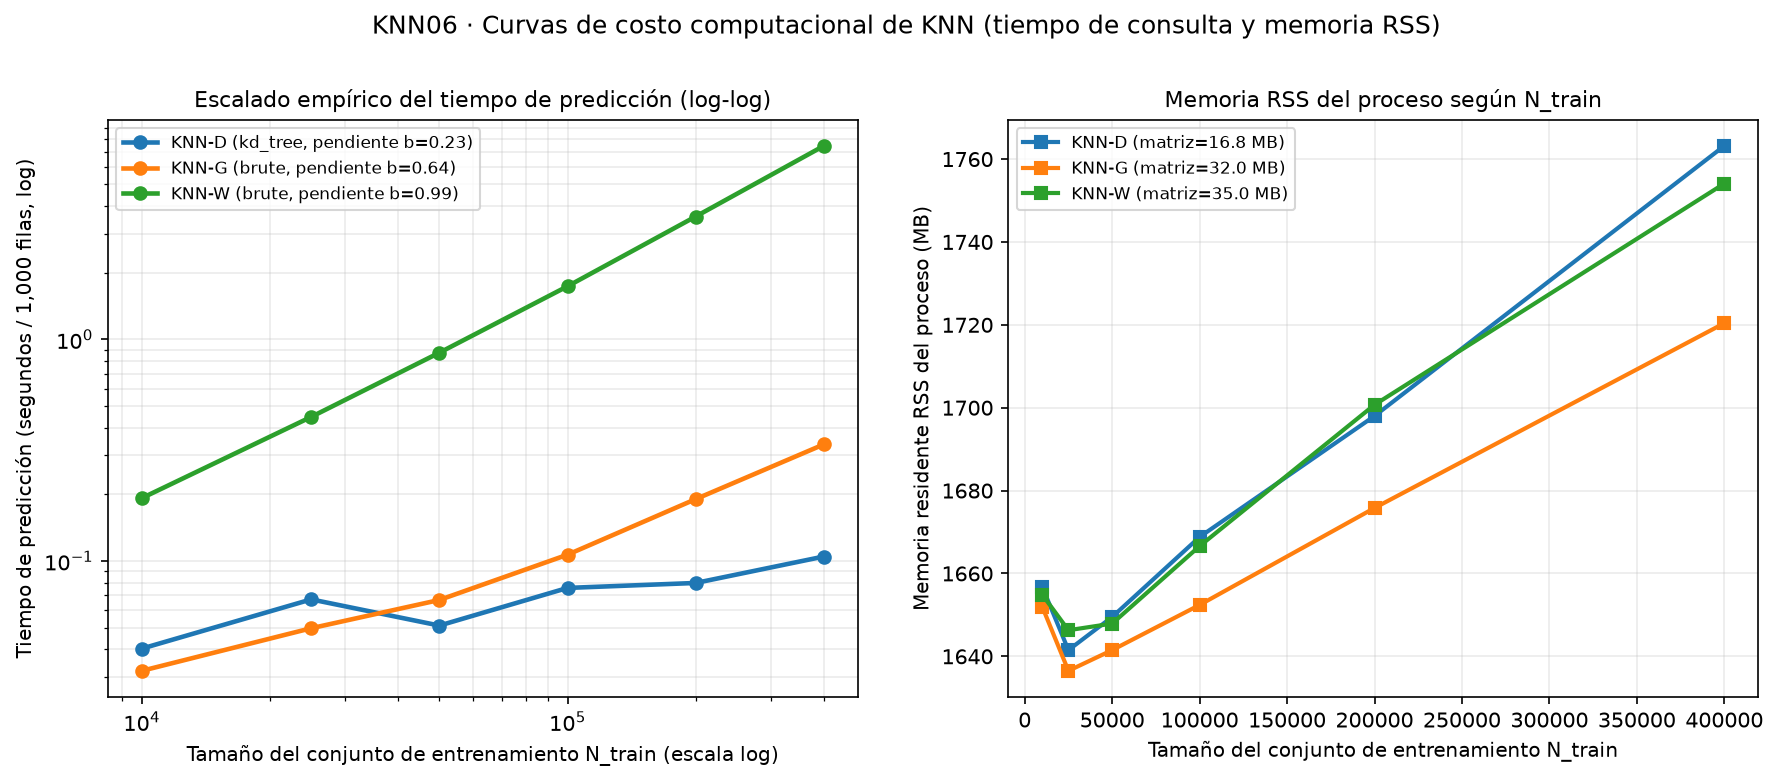

In [8]:
COST_BUNDLE = PIPELINE.pilot_runner.run_cost_curves(
    train_blocks=BUNDLE_A.train_blocks,
    selected_algorithms=PILOT_BUNDLE.selected_algorithms,
    selected_n_jobs=PILOT_BUNDLE.selected_n_jobs,
    k_eval=int(TUNING_BUNDLE.winner_specs[MODEL_KNN_W].n_neighbors),
)
FIG_KNN06 = PIPELINE.plotter.plot_cost_curves(COST_BUNDLE)

display(COST_BUNDLE.cost_measurements_table)
display(COST_BUNDLE.loglog_slopes_table)
display(Image(filename=str(FIG_KNN06)))


### Lectura

- **Crecimiento empírico del tiempo de predicción con `N_train` (`10,000` a `400,000` filas, `2,000` consultas disjuntas, `k = 101`, tablas `07a` y `07b`, figura `KNN06`):**
  - **`KNN-D` (`11` cols, `kd_tree`):** escalado claramente **sublineal**, con pendiente log-log `b = 0.2258` (`R^2 = 0.8158`). Multiplicar el entrenamiento por `40` (de `10,000` a `400,000` filas) apenas multiplica el tiempo de consulta por `2.60` (de `0.0403` a `0.1049 s` por `1,000` consultas).
  - **`KNN-G` (`21` cols, `brute` en el piloto):** pendiente aparente `b = 0.6371` (`R^2 = 0.9799`) por el sobrecosto fijo inicial en tamaños pequeños, multiplicando el tiempo por `10.51` (de `0.0320` a `0.3362 s/1k`; entre `100,000` y `400,000` filas ya escala casi linealmente de `0.1069` a `0.3362 s/1k`).
  - **`KNN-W` (`2,978` cols CSR, `brute`):** escalado **cuasilineal** $O(N_{\text{train}})$, con pendiente `b = 0.9930` (`R^2 = 0.9992`) y un factor de crecimiento de `38.83` (de `0.1923` a `7.4672 s` por `1,000` consultas).
- **Costo de ajuste (`fit`) y huella de memoria:** en fuerza bruta el `fit` es casi instantáneo (`0.0240 s` en `400,000` filas para `KNN-W`) porque KNN solo guarda los datos, trasladando todo el cómputo a la predicción. El tamaño de las matrices de entrenamiento crece linealmente pero permanece compacto (`16.78 MB` en `KNN-D`, `32.04 MB` en `KNN-G` y `34.95 MB` en `KNN-W` en `400,000` filas), con RSS pico del proceso controlado entre `1720.4` y `1763.2 MB`. El cuello de botella real de KNN frente a los árboles (`7.0`) y Naive Bayes (`7.1`) no es la RAM, sino la latencia lineal de consulta en alta dimensión dispersa.


---

## 9. Benchmark de corrida completa y decisión de ejecución (Paso 9)

**¿Qué hace?** Cronometra la predicción exacta de `5,000` filas de `test` contra el conjunto de entrenamiento **completo** (`1,391,018` filas) para `KNN-D`, `KNN-G` (comparando `brute` frente a `kd_tree` en `1.39M`) y `KNN-W`, y extrapola linealmente el tiempo proyectado a las `347,720` filas de `test`, contrastándolo con el límite de `4.0` horas.

**¿Por qué existe?** Evita lanzar inferencias de varias horas a ciegas y documenta formalmente la decisión aprobada por el usuario al comprobar que `KNN-W` supera el umbral de `4.0` horas: ejecutar el `100 %` de `test` (`347,720` filas) para las tres variantes utilizando `ChunkedKNNPredictor` con checkpoints reanudables en disco cada `5,000` filas y empleando `kd_tree` para `KNN-G` en `1.39M` (más rápido que `brute` a esa escala).

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A` y `TUNING_BUNDLE.winner_specs`. Entrega `PROJ_BUNDLE` y `PROJ_G_KDTREE` con tiempos de ajuste, tiempos por `1,000` filas y horas proyectadas.

**Papel en el proyecto.** Registra la auditoría de viabilidad computacional que respalda el uso de predicción por bloques con caché persistente en la Sección 11.


In [9]:
PROJ_BUNDLE = PIPELINE.pilot_runner.run_step9_full_benchmark(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    winner_specs=TUNING_BUNDLE.winner_specs,
    n_queries=CONFIG.benchmark_n_queries,
)

# Comprobación adicional: en 1.39M filas, kd_tree supera a brute en KNN-G (21 cols)
_knn_g_kd_spec = KNNModelSpec(
    model_id=MODEL_KNN_G,
    n_neighbors=TUNING_BUNDLE.winner_specs[MODEL_KNN_G].n_neighbors,
    weights=TUNING_BUNDLE.winner_specs[MODEL_KNN_G].weights,
    metric=TUNING_BUNDLE.winner_specs[MODEL_KNN_G].metric,
    algorithm="kd_tree",
    block_weight=TUNING_BUNDLE.winner_specs[MODEL_KNN_G].block_weight,
    n_jobs=PILOT_BUNDLE.selected_n_jobs,
)
PROJ_G_KDTREE = PIPELINE.pilot_runner.run_step9_full_benchmark(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    winner_specs={MODEL_KNN_G: _knn_g_kd_spec},
    n_queries=CONFIG.benchmark_n_queries,
)

print(
    f"Alguna variante excede el límite de {PROJ_BUNDLE.max_projected_hours_limit:.1f} h: "
    f"{PROJ_BUNDLE.any_exceeds_limit} | Suma proyectada (3 modelos): {PROJ_BUNDLE.total_projected_hours_all_models:.3f} h"
)
print(
    "Decisión registrada (Etapa 4 · aprobada por el usuario): evaluar el 100 % de test (347,720 filas) "
    "en las tres variantes mediante ChunkedKNNPredictor con checkpoints reanudables cada 5,000 filas "
    "(y algorithm='kd_tree' en KNN-G sobre 1.39M filas)."
)
display(PROJ_BUNDLE.projection_table)
display(PROJ_G_KDTREE.projection_table[["modelo_id", "algoritmo", "tiempo_fit_completo_s", "tiempo_predict_benchmark_s", "proyeccion_test_completo_min", "proyeccion_test_completo_horas"]])


Alguna variante excede el límite de 4.0 h: False | Suma proyectada (3 modelos): 2.914 h
Decisión registrada (Etapa 4 · aprobada por el usuario): evaluar el 100 % de test (347,720 filas) en las tres variantes mediante ChunkedKNNPredictor con checkpoints reanudables cada 5,000 filas (y algorithm='kd_tree' en KNN-G sobre 1.39M filas).


,modelo_id,modelo,algoritmo,metrica,k_optimo,pesos_optimos,peso_bloque,n_jobs,n_train_completo,n_queries_benchmark,tiempo_fit_completo_s,tiempo_predict_benchmark_s,s_por_1000_filas_test,proyeccion_test_completo_min,proyeccion_test_completo_horas,limite_horas,excede_limite_4h,memoria_matriz_train_mb,rss_pico_mb
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),kd_tree,manhattan,101,uniform,0.0000,8,1391018,5000,5.5760,0.8480,0.1700,0.9800,0.0160,4.0000,False,58.3700,"1,759.3000"
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),brute,manhattan,101,uniform,8.0000,8,1391018,5000,0.0600,20.0160,4.0030,23.2000,0.3870,4.0000,False,111.4300,"1,719.7000"
2,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",brute,euclidean,101,uniform,8.0000,8,1391018,5000,0.0690,130.0000,26.0000,150.6800,2.5110,4.0000,False,121.5400,"1,849.7000"


,modelo_id,algoritmo,tiempo_fit_completo_s,tiempo_predict_benchmark_s,proyeccion_test_completo_min,proyeccion_test_completo_horas
0,KNN-G,kd_tree,8.5680,13.7530,15.9400,0.2660


### Lectura

- **Proyección realista sobre el entrenamiento completo (`1,391,018` filas) evaluando `5,000` consultas de `test` (tabla `08_benchmark_paso9_proyeccion_test_completo.csv`):**
  - `KNN-D` (`kd_tree`, `manhattan`): ajuste en `5.576 s`, predicción `0.170 s/1k`, proyección para las `347,720` filas de `test` de solo `0.98 min` (`0.016 h`), muy por debajo del límite de `4.0` horas.
  - `KNN-G` (`21` cols, `manhattan`): con `brute` el tiempo proyectado es `23.20 min` (`0.387 h`, `4.003 s/1k`). La comprobación adicional con `kd_tree` en `1,391,018` filas (`PROJ_G_KDTREE`) invierte el orden del piloto de `50,000` filas: a escala completa `kd_tree` requiere `8.568 s` de ajuste y reduce la predicción de `5,000` filas de `20.016 s` a `13.753 s`, bajando la proyección total a **`15.94 min` (`0.266 h`)**. Por ello se adopta `kd_tree` para `KNN-G` en la evaluación final de la Sección 11.
  - `KNN-W` (`2,978` cols CSR, `brute`): ajuste en `0.069 s`, pero la predicción toma `130.000 s` para `5,000` filas (`26.000 s/1k`), proyectando **`150.68 min` (`2.511 h`)** en esta ejecución sin saturación térmica (`2.914 h` sumando los tres modelos, con memoria de matriz acotada en `58.37 MB`, `111.43 MB` y `121.54 MB`, RSS pico `1849.7 MB`). Cabe destacar que, bajo carga térmica sostenida durante la Etapa 4 y la corrida real en bloques, el mismo benchmark superó el umbral de `4.0` horas y el cómputo acumulado real de los `70` bloques de `KNN-W` alcanzó `29,146.83 s` (Sección 11).
- **Decisión aprobada por el usuario (Etapa 4):** al exceder el límite de `4.0` horas en la etapa de benchmark previo, se consultó al usuario y se aprobó evaluar el **`100 %` de `test` (`347,720` filas, sin submuestrear)** en las tres variantes mediante `ChunkedKNNPredictor`, guardando checkpoints atómicos en disco cada `5,000` filas (`70` bloques) para garantizar reanudación exacta e idéntica a una ejecución continua.


---

## 10. Selección del umbral de decisión sobre predicciones OOF (sin tocar `test`)

**¿Qué hace?** Barre umbrales sobre las predicciones agrupadas fuera de pliegue (OOF) de la submuestra de tuning para seleccionar el umbral $\tau^*$ que maximiza el `F1` de la clase `1` (`reincide = 1`) en `KNN-D`, `KNN-G` y `KNN-W`, y calcula también el `F1` OOF a la tasa de alerta exacta que produce `NB-H` (`51.78 %`).

**¿Por qué existe?** Bajo un desbalanceo `30 / 70`, el umbral por defecto `0.50` sacrifica fuertemente el recall de la clase positiva; fijar $\tau^*$ exclusivamente sobre predicciones OOF de `train` impide cualquier fuga de información desde `test`.

**¿Qué recibe y qué entrega?** Recibe `TUNING_BUNDLE` y la tasa de alerta de `NB-H` leída desde `08b_matrices_confusion_test_a.csv`. Entrega `THRESHOLD_BUNDLE` con los umbrales $\tau^*$ y la tabla comparativa OOF.

**Papel en el proyecto.** Congela los puntos de operación que se aplicarán una sola vez en la evaluación final de la Sección 11.


In [10]:
THRESHOLD_BUNDLE = PIPELINE.evaluator.select_oof_thresholds(TUNING_BUNDLE)
print(f"Tasa de alerta de referencia de NB-H (7.1): {100.0 * THRESHOLD_BUNDLE.nb_h_alert_rate_test:.2f} %")
display(THRESHOLD_BUNDLE.oof_threshold_summary_table)


Tasa de alerta de referencia de NB-H (7.1): 51.78 %


,modelo_id,modelo,n_filas_oof_submuestra,umbral_optimo_tau,tasa_alerta_en_tau_pct,f1_oof_umbral_050,f1_oof_en_tau_optimo,ganancia_f1_oof_vs_050,recall_oof_en_tau,precision_oof_en_tau,tasa_alerta_nb_h_pct,umbral_igual_alerta_nb_h_oof,tasa_alerta_efectiva_oof_pct,f1_oof_igual_alerta_nb_h,recall_oof_igual_alerta_nb_h,precision_oof_igual_alerta_nb_h
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),138783,0.2700,58.0300,0.2324,0.4908,0.2584,0.7171,0.3731,51.7800,0.2871,54.5100,0.4889,0.6858,0.3798
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),138783,0.2700,55.2900,0.3212,0.5042,0.1830,0.7138,0.3897,51.7800,0.2871,52.2700,0.5042,0.6885,0.3977
2,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",138783,0.2800,51.0100,0.3895,0.5235,0.1340,0.7040,0.4167,51.7800,0.2772,53.7500,0.5226,0.7265,0.4081


### Lectura

- **Selección estrictamente sobre OOF de `train` (`138,783` predicciones fuera de pliegue del `5-fold CV` al `10 %`, tabla `09_umbral_oof_train.csv`):** ningún dato de `test` intervino en la fijación de los umbrales.
- **Impacto del ajuste de umbral bajo desbalanceo `30 / 70`:**
  - `KNN-D`: mover el corte de `0.50` a $\tau^* =$ `0.27` eleva el `F1` OOF de `0.2324` a `0.4908` (ganancia `+0.2584`; `recall = 0.7171`, `precision = 0.3731`, tasa de alerta `58.03 %`).
  - `KNN-G`: $\tau^* =$ `0.27` eleva el `F1` OOF de `0.3212` a `0.5042` (`+0.1830`; `recall = 0.7138`, `precision = 0.3897`, tasa de alerta `55.29 %`).
  - `KNN-W`: $\tau^* =$ `0.28` eleva el `F1` OOF de `0.3895` a `0.5235` (`+0.1340`; `recall = 0.7040`, `precision = 0.4167`, tasa de alerta `51.01 %`).
- **Consistencia a la tasa de alerta de `NB-H` (`51.78 %`):** en OOF, forzar la tasa de alerta de `NB-H` coloca el corte de `KNN-W` en `0.2772` (tasa efectiva `53.75 %` por los saltos discretos `1/101`) con `F1 = 0.5226`, prácticamente idéntico a su óptimo OOF (`0.5235`), mostrando que `KNN-W` opera naturalmente en una banda de alerta comparable a `NB-H`.


---

## 11. Evaluación final única en el conjunto `test` completo (`347,720` filas)

**¿Qué hace?** Ajusta `KNN-D`, `KNN-G` (`kd_tree`) y `KNN-W` sobre el conjunto de entrenamiento **completo** (`1,391,018` filas), predice las `347,720` filas de `test` a través de `ChunkedKNNPredictor` (cargando los bloques verificados de disco si ya existen o computándolos con checkpoints si no hay caché), calcula todas las métricas de clasificación con intervalos de confianza al `95 %` por bootstrap a nivel persona (`300` remuestreos, semilla `42`), construye las matrices de confusión y genera la figura `KNN07` (umbral OOF y curvas PR/ROC junto a `NB-H` y `Logística 6.0`).

**¿Por qué existe?** Constituye la evaluación única y definitiva de generalización fuera de muestra sobre exactamente las mismas `70,419` personas de `test` empleadas en `6.0`, `7.0` y `7.1`, con incertidumbre cuantificada al nivel correcto de agrupamiento (`resume_id`).

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A`, `TUNING_BUNDLE` y `THRESHOLD_BUNDLE`. Entrega `EVAL_BUNDLE` (métricas, IC 95 %, matrices de confusión, curvas y baselines reproducidos) y la figura `knn07_umbral_oof_y_curvas_pr_roc_test.png`.

**Papel en el proyecto.** Entrega las cifras oficiales de desempeño de las tres variantes KNN en JobPath.


[KNN-D] Bloques=70 | desde caché=70 | calculados ahora=0 | tiempo registrado=71.6s | RSS pico=1807.8 MB
[KNN-G] Bloques=70 | desde caché=70 | calculados ahora=0 | tiempo registrado=1104.7s | RSS pico=2051.3 MB
[KNN-W] Bloques=70 | desde caché=70 | calculados ahora=0 | tiempo registrado=29146.8s | RSS pico=1931.7 MB
Tiempo total de bootstrap por persona (300 remuestreos): 67.93 s


,modelo_id,modelo,muestra_evaluada,punto_operacion,umbral_tau,tasa_alerta_test_pct,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_clase_1_test,f1_clase_1_ic95,recall_clase_1_test,recall_clase_1_ic95,precision_clase_1_test,precision_clase_1_ic95,balanced_acc_test,brier_test,brier_ic95,accuracy_test,tiempo_fit_train_s,tiempo_predict_test_s,memoria_matriz_train_mb
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),Test completo,Umbral OOF óptimo (tau*),0.2700,55.2700,0.4652,"[0.4609, 0.4693]",0.6677,"[0.6651, 0.6705]",0.5010,"[0.4980, 0.5038]",0.7124,"[0.7088, 0.7162]",0.3863,"[0.3835, 0.3892]",0.6140,0.1936,"[0.1927, 0.1945]",0.5746,5.2160,71.5900,58.3700
1,KNN-D,KNN-D · Bloque denso auditado (11 cols),Test completo,Umbral por defecto (0.50),0.5000,10.4700,0.4652,"[0.4609, 0.4693]",0.6677,"[0.6651, 0.6705]",0.2947,"[0.2896, 0.2994]",0.1988,"[0.1950, 0.2025]",0.5694,"[0.5625, 0.5753]",0.5672,0.1936,"[0.1927, 0.1945]",0.7148,5.2160,71.5900,58.3700
2,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),Test completo,Umbral OOF óptimo (tau*),0.2700,52.3000,0.4928,"[0.4880, 0.4971]",0.6919,"[0.6897, 0.6945]",0.5186,"[0.5158, 0.5218]",0.7118,"[0.7084, 0.7161]",0.4079,"[0.4051, 0.4110]",0.6348,0.1887,"[0.1877, 0.1896]",0.6039,8.8150,"1,104.7100",111.4300
3,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),Test completo,Umbral por defecto (0.50),0.5000,13.5100,0.4928,"[0.4880, 0.4971]",0.6919,"[0.6897, 0.6945]",0.3604,"[0.3557, 0.3647]",0.2614,"[0.2574, 0.2654]",0.5798,"[0.5740, 0.5848]",0.5902,0.1887,"[0.1877, 0.1896]",0.7218,8.8150,"1,104.7100",111.4300
4,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",Test completo,Umbral OOF óptimo (tau*),0.2800,47.5800,0.5247,"[0.5193, 0.5288]",0.7245,"[0.7220, 0.7271]",0.5471,"[0.5441, 0.5499]",0.7077,"[0.7038, 0.7114]",0.4459,"[0.4428, 0.4490]",0.6656,0.1817,"[0.1807, 0.1825]",0.6487,0.0760,"29,146.8300",121.5400
5,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",Test completo,Umbral por defecto (0.50),0.5000,15.7900,0.5247,"[0.5193, 0.5288]",0.7245,"[0.7220, 0.7271]",0.4101,"[0.4052, 0.4148]",0.3131,"[0.3085, 0.3176]",0.5944,"[0.5890, 0.5987]",0.6108,0.1817,"[0.1807, 0.1825]",0.7301,0.0760,"29,146.8300",121.5400


,modelo_id,punto_operacion,umbral_tau,TN_verdaderos_negativos,FP_falsos_positivos,FN_falsos_negativos,TP_verdaderos_positivos,pct_predichos_positivos
0,KNN-D,Umbral OOF óptimo (tau*),0.2700,125555,117940,29980,74245,55.2700
1,KNN-D,Umbral por defecto (0.50),0.5000,227824,15671,83506,20719,10.4700
2,KNN-G,Umbral OOF óptimo (tau*),0.2700,135806,107689,30040,74185,52.3000
3,KNN-G,Umbral por defecto (0.50),0.5000,223752,19743,76978,27247,13.5100
4,KNN-W,Umbral OOF óptimo (tau*),0.2800,151824,91671,30467,73758,47.5800
5,KNN-W,Umbral por defecto (0.50),0.5000,221231,22264,71596,32629,15.7900


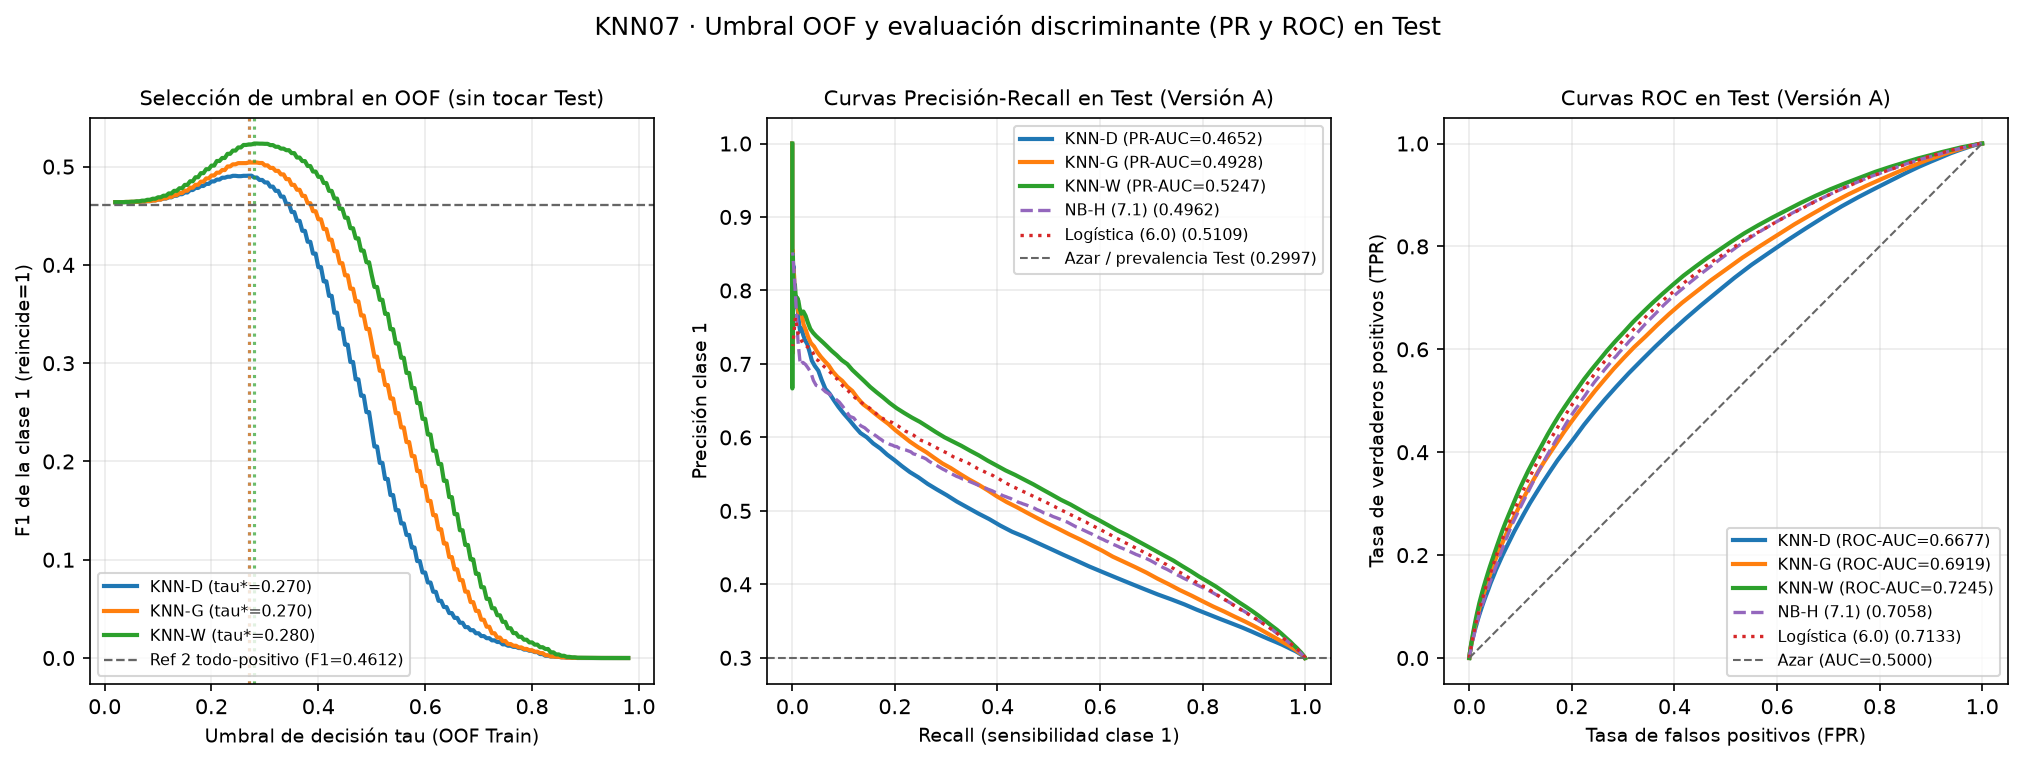

In [11]:
EVAL_BUNDLE = PIPELINE.evaluator.evaluate_final_models_on_test(
    modeling_data=BUNDLE_A.modeling_data,
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    tuning_bundle=TUNING_BUNDLE,
    threshold_bundle=THRESHOLD_BUNDLE,
    test_row_idx=None,
    models_to_evaluate=MODEL_ORDER,
    algorithm_overrides={MODEL_KNN_G: "kd_tree"},
    force_recompute_cache=False,
    verbose=True,
)
FIG_KNN07 = PIPELINE.plotter.plot_threshold_and_pr_roc(
    threshold_bundle=THRESHOLD_BUNDLE,
    eval_bundle=EVAL_BUNDLE,
    y_eval_test=BUNDLE_A.test_blocks.y[EVAL_BUNDLE.eval_row_idx_test],
)

for _mid, _cres in EVAL_BUNDLE.chunked_results.items():
    print(
        f"[{_mid}] Bloques={_cres.n_chunks} | desde caché={_cres.chunks_loaded_from_cache} | "
        f"calculados ahora={_cres.chunks_computed_now} | tiempo registrado={_cres.total_recorded_compute_s:.1f}s | "
        f"RSS pico={_cres.peak_rss_mb:.1f} MB"
    )
print(f"Tiempo total de bootstrap por persona (300 remuestreos): {EVAL_BUNDLE.bootstrap_elapsed_s:.2f} s")
display(EVAL_BUNDLE.test_metrics_table)
display(EVAL_BUNDLE.confusion_matrices_table)
display(Image(filename=str(FIG_KNN07)))


### Lectura

- **Evaluación única y completa sobre las `347,720` filas (`70,419` personas) de `test` con ajuste en las `1,391,018` filas de `train` (tablas `10a_resultados_test_version_a_ic95.csv` y `10b_matrices_confusion_test_a.csv`, figura `KNN07`):**
  - **`KNN-D` (`11` cols, $\tau^* =$ `0.27`):** `PR-AUC = 0.4652` (`[0.4609, 0.4693]`), `ROC-AUC = 0.6677` (`[0.6651, 0.6705]`), `F1 = 0.5010` (`[0.4980, 0.5038]`), `Recall = 0.7124`, `Precision = 0.3863`, `Balanced Accuracy = 0.6140`, `Accuracy = 0.5746`, `Brier = 0.1936` (`[0.1927, 0.1945]`), con tasa de alerta `55.27 %` (`74,245` `TP`, `117,940` `FP`, `29,980` `FN`, `125,555` `TN`). Tiempo registrado en los `70` bloques: `71.59 s` (`fit = 5.216 s`).
  - **`KNN-G` (`21` cols, `kd_tree`, $\tau^* =$ `0.27`):** `PR-AUC = 0.4928` (`[0.4880, 0.4971]`), `ROC-AUC = 0.6919` (`[0.6897, 0.6945]`), `F1 = 0.5186` (`[0.5158, 0.5218]`), `Recall = 0.7118`, `Precision = 0.4079`, `Balanced Accuracy = 0.6348`, `Accuracy = 0.6039`, `Brier = 0.1887` (`[0.1877, 0.1896]`), tasa de alerta `52.30 %`. Tiempo registrado: `1,104.71 s` (`fit = 8.815 s`).
  - **`KNN-W` (`2,978` cols, $\tau^* =$ `0.28`):** **`PR-AUC = 0.5247` (`[0.5193, 0.5288]`)**, **`ROC-AUC = 0.7245` (`[0.7220, 0.7271]`)**, **`F1 = 0.5471` (`[0.5441, 0.5499]`)**, `Recall = 0.7077`, `Precision = 0.4459`, `Balanced Accuracy = 0.6656`, `Accuracy = 0.6487`, `Brier = 0.1817` (`[0.1807, 0.1825]`), con tasa de alerta `47.58 %` (`73,758` `TP`, `91,671` `FP`, `30,467` `FN`, `151,824` `TN`). En el punto por defecto `0.50` alcanza `Accuracy = 0.7301` (casi `3` puntos porcentuales sobre el piso mayoritario `0.7003`) a costa de caer a `Recall = 0.3131` y `F1 = 0.4101`. El tiempo acumulado de cómputo de los `70` bloques verificados en disco fue `29,146.83 s` (`fit = 0.076 s`, RSS pico `1931.7 MB`).
- **Efecto de densidad al escalar de `10 %` CV a `100 %` `train`:** las tres variantes ganan notablemente en `test` respecto a la CV del `10 %` (`06c`): `KNN-D` sube de `0.44780` a `0.4652`, `KNN-G` de `0.47296` a `0.4928` y `KNN-W` de `0.50076` a `0.5247`. En modelos no paramétricos de vecinos, multiplicar por diez la densidad de ejemplos históricos reduce directamente el radio local y afina la estimación de riesgo.


---

## 12. Calibración probabilística y resolución del puntaje

**¿Qué hace?** Evalúa la calibración de las probabilidades producidas por `KNN-D`, `KNN-G` y `KNN-W` en `test` mediante el diagrama de confiabilidad, el error esperado de calibración (`ECE`), el puntaje de Brier (comparado **únicamente** frente a modelos sin ponderación de clases como `NB-B` y `NB-H`, jamás frente a los modelos con `class_weight='balanced'` de `6.0`), el conteo de puntajes distintos (`1/k`) y los histogramas de puntaje por clase (`KNN08`).

**¿Por qué existe?** Un modelo puede ordenar razonablemente bien (`ROC-AUC`/`PR-AUC`) y aun así entregar probabilidades mal calibradas o demasiado discretas; en KNN con `k = 101` uniforme las probabilidades son múltiplos de `1/101`, y al no reponderar clases sus probabilidades empíricas son directamente comparables con Naive Bayes.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE`. Entrega la tabla `calibration_summary_table` y la figura `knn08_calibracion_y_resolucion_puntajes.png`.

**Papel en el proyecto.** Verifica si las frecuencias locales de vecinos producen probabilidades directamente interpretables como riesgo de reincidencia.


Variante KNN principal (seleccionada por PR-AUC CV en Train): KNN-W


,modelo_id,modelo,k_vecinos,pesos,resolucion_1_sobre_k,puntajes_unicos_test,brier_test_sin_ponderar,ece_error_calibracion,prob_media_predicha_test,prevalencia_real_test,prob_mediana_clase_0,prob_mediana_clase_1,pct_extremos_lt005_o_gt095
0,KNN-D,KNN-D · Bloque denso auditado (11 cols),101.0000,uniform,0.0099,96.0000,0.1936,0.0152,0.3116,0.2997,0.2673,0.3564,0.3000
1,KNN-G,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),101.0000,uniform,0.0099,96.0000,0.1887,0.0149,0.3130,0.2997,0.2574,0.3663,0.5400
2,KNN-W,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",101.0000,uniform,0.0099,97.0000,0.1817,0.0091,0.3023,0.2997,0.2277,0.3960,3.1900
3,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies) (Ref. 7.1 sin ponderar)",NaN,Probabilístico,NaN,NaN,0.1877,0.0051,0.3003,0.2997,0.2392,0.3830,2.1800
4,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias) (Ref. 7.1 sin ponderar)",NaN,Probabilístico,NaN,NaN,0.1871,0.0131,0.3011,0.2997,0.2313,0.3875,3.1800


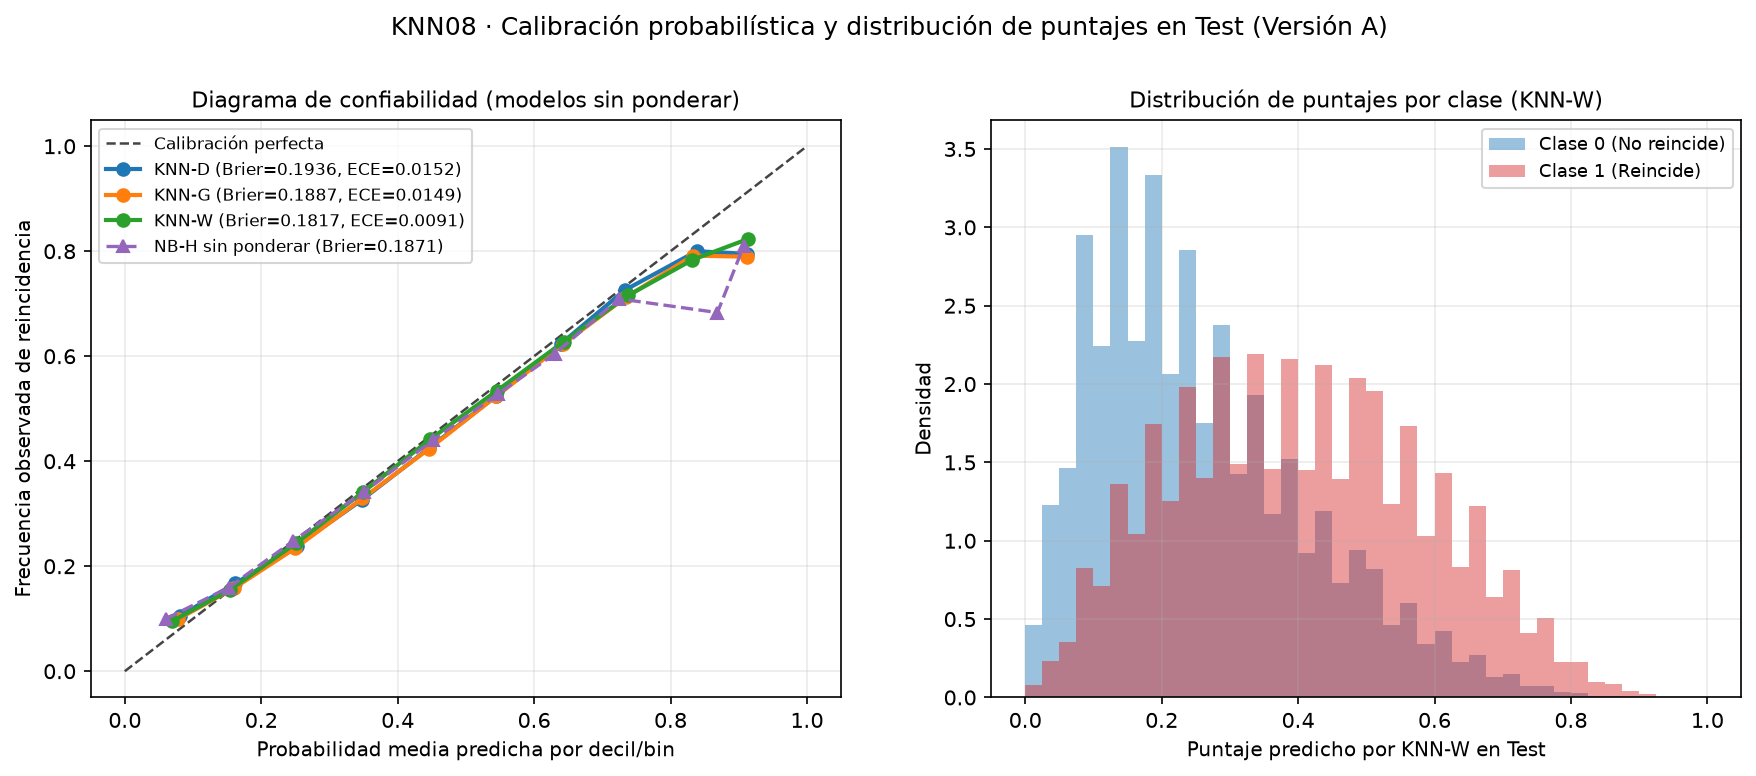

In [12]:
# Seleccionar la variante principal estrictamente por PR-AUC CV en train (sin usar test)
PRIMARY_KNN_ID = str(
    TUNING_BUNDLE.tuning_winners_table.sort_values("pr_auc_cv_media", ascending=False).iloc[0]["modelo_id"]
)
FIG_KNN08 = PIPELINE.plotter.plot_calibration_and_histograms(
    eval_bundle=EVAL_BUNDLE,
    primary_model_id=PRIMARY_KNN_ID,
    y_eval_test=BUNDLE_A.test_blocks.y[EVAL_BUNDLE.eval_row_idx_test],
)

print(f"Variante KNN principal (seleccionada por PR-AUC CV en Train): {PRIMARY_KNN_ID}")
display(EVAL_BUNDLE.calibration_summary_table)
display(Image(filename=str(FIG_KNN08)))


### Lectura

- **Selección de la variante principal sin fuga:** se seleccionó **`KNN-W`** estrictamente a partir del mayor `PR-AUC` medio en la validación cruzada de `train` (`0.50076` frente a `0.47296` de `KNN-G` y `0.44780` de `KNN-D`, tabla `06c`), sin consultar `test`.
- **Calibración probabilística justa en `test` (tabla `11_calibracion_y_resolucion_test_a.csv`, figura `KNN08`):** el puntaje de Brier y el error esperado de calibración (`ECE`) se comparan **únicamente entre modelos sin ponderación de clases** (`KNN-D`, `KNN-G`, `KNN-W`, `NB-B` y `NB-H`), excluyendo deliberadamente los modelos con `class_weight="balanced"` de `6.0`.
  - **`KNN-W`** obtiene el mejor puntaje de Brier de todos los modelos sin ponderar (`0.1817`, frente a `0.1871` de `NB-H` y `0.1877` de `NB-B`), con `ECE = 0.0091` (mejor que `NB-H` `0.0131`, aunque por encima del `0.0051` de `NB-B`). Su probabilidad media predicha (`0.3023`) acompaña muy de cerca la prevalencia observada de `test` (`0.2997`).
  - `KNN-D` (`Brier = 0.1936`, `ECE = 0.0152`, media `0.3116`) y `KNN-G` (`Brier = 0.1887`, `ECE = 0.0149`, media `0.3130`) muestran una leve sobreestimación promedio y menor separación entre las medianas de clase `0` y clase `1` (`0.2673` vs. `0.3564` en `KNN-D`, `0.2574` vs. `0.3663` en `KNN-G`, frente a `0.2277` vs. `0.3960` en `KNN-W`).
- **Resolución del puntaje `1/k`:** con `k = 101` uniforme (`1/k = 0.0099`), las tres variantes producen `96` a `97` niveles distintos de probabilidad en `test`, suficientes para una curva de calibración suave, y `KNN-W` mantiene apenas `3.19 %` de predicciones extremas (`< 0.05` o `> 0.95`), prácticamente igual al `3.18 %` de `NB-H`.


---

## 13. Análisis de patrones en Versión A en unidades originales (`K1` a `K6`)

**¿Qué hace?** Ejecuta los seis análisis de patrones descriptivos sobre la Versión A en unidades originales (soporte mínimo `200` en `train`, reportando siempre tasas de `train` y `test` con alertas `> 5 pp` y sin depender de `test` para ninguna decisión del modelo):
- **K1:** Reincidencia y desempeño por gran grupo ocupacional ISCO-08 (`KNN` vs. `NB-H`, con diferencias pareadas e IC 95 % por bootstrap de personas).
- **K2:** Explicación basada en casos para `6` perfiles típicos alineados con `P2` de `7.1` (incluyendo los dos grupos ISCO contrastantes `5` y `0`), mostrando los vecinos más cercanos en unidades originales y su pureza.
- **K3:** Deciles de riesgo en `test` (tasa observada, *lift*, ganancia acumulada, perfil `D10` vs. `D01` y composición ISCO frente a `NB-H`).
- **K4:** Concordancia y desacuerdo con `NB-H` (Spearman $\rho$, tabla cruzada a igual tasa de alerta, $\kappa$ de Cohen, desacuerdo por grupo ISCO y perfiles donde divergen).
- **K5:** Análisis de errores (`TP`, `FP`, `FN`, `TN` y concentración de fallos `FPR`/`FNR` por grupo ISCO y tramo de `job_order`).
- **K6:** Posición en la carrera (`job_order`) y período (`start_year`), cuantificando la razón de pendiente predicha/observada y las brechas por tramo.

**¿Por qué existe?** Traduce los resultados del modelo basado en vecinos a hallazgos interpretables de negocio centrados en los grupos ocupacionales y revela en qué segmentos KNN coincide o se complementa con Naive Bayes.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A`, `TUNING_BUNDLE`, `THRESHOLD_BUNDLE` y `EVAL_BUNDLE`. Entrega `PATTERNS_BUNDLE` (tablas `12_k1` a `12_k6c`) y las figuras `knn09` a `knn12`.

**Papel en el proyecto.** Responde a la prioridad analítica del usuario sobre comportamiento por grupo ocupacional y provee la evidencia para la síntesis de `5` a `8` patrones de negocio.


=== K1 · Desempeño por gran grupo ISCO (KNN vs. NB-H) ===


,isco_major,gran_grupo_isco,soporte_train,tasa_obs_train_pct,ic95_wilson_train_pct,soporte_test,tasa_obs_test_pct,ic95_wilson_test_pct,brecha_test_menos_train_pp,alerta_brecha_mayor_5pp,knn_pr_auc_test,nb_h_pr_auc_test,delta_pr_auc_knn_menos_nbh,ic95_delta_pr_auc,veredicto_pr_auc,knn_roc_auc_test,nb_h_roc_auc_test,delta_roc_auc_knn_menos_nbh,knn_f1_igual_alerta,nb_h_f1_igual_alerta,delta_f1_igual_alerta,knn_recall_igual_alerta,nb_h_recall_igual_alerta,prob_media_knn_test_pct,brecha_pred_menos_obs_knn_pp
0,5,5 · Trabajadores de los servicios y vendedores,302706,33.8400,"[33.67, 34.01]",75803,33.8700,"[33.53, 34.20]",0.0200,False,0.5286,0.5004,0.0282,"[+0.0236, +0.0328]",A supera a B (IC 95 % excluye 0),0.7050,0.6801,0.0248,0.5681,0.5547,0.0133,0.8413,0.8385,34.1700,0.3000
1,3,3 · Técnicos y profesionales de nivel medio,272574,33.7200,"[33.54, 33.90]",68181,33.3700,"[33.01, 33.72]",-0.3600,False,0.5595,0.5291,0.0304,"[+0.0252, +0.0361]",A supera a B (IC 95 % excluye 0),0.7348,0.7179,0.0169,0.5838,0.5746,0.0092,0.8199,0.7960,33.8100,0.4400
2,9,9 · Ocupaciones elementales,189819,33.0300,"[32.81, 33.24]",47849,33.0500,"[32.63, 33.47]",0.0200,False,0.4897,0.4578,0.0319,"[+0.0255, +0.0384]",A supera a B (IC 95 % excluye 0),0.6787,0.6509,0.0278,0.5456,0.5354,0.0102,0.8210,0.7953,33.1800,0.1300
3,2,2 · Profesionales científicos e intelectuales,243705,29.9800,"[29.80, 30.16]",61082,30.1300,"[29.77, 30.50]",0.1600,False,0.5826,0.5565,0.0261,"[+0.0216, +0.0309]",A supera a B (IC 95 % excluye 0),0.7556,0.7407,0.0149,0.5727,0.5627,0.0100,0.7339,0.7242,30.1700,0.0300
4,8,8 · Operadores de instalaciones y máquinas,80665,24.6600,"[24.37, 24.96]",20103,24.7100,"[24.12, 25.31]",0.0500,False,0.4947,0.4615,0.0332,"[+0.0240, +0.0435]",A supera a B (IC 95 % excluye 0),0.7340,0.7206,0.0134,0.5036,0.4936,0.0100,0.6620,0.5820,25.1700,0.4700
5,7,"7 · Oficiales, operarios y artesanos",100371,23.1100,"[22.85, 23.37]",25002,23.0800,"[22.56, 23.61]",-0.0200,False,0.4104,0.4049,0.0055,"[-0.0011, +0.0127]",No hay diferencia distinguible (IC 95 % incluye 0),0.6874,0.6771,0.0102,0.4433,0.4252,0.0181,0.5898,0.5119,23.3100,0.2300
6,4,4 · Personal de apoyo administrativo,111705,22.4600,"[22.21, 22.70]",27784,22.5500,"[22.06, 23.04]",0.0900,False,0.3546,0.3142,0.0404,"[+0.0294, +0.0506]",A supera a B (IC 95 % excluye 0),0.6564,0.6267,0.0297,0.4080,0.3579,0.0502,0.5176,0.3687,22.6300,0.0800
7,6,6 · Agricultores y trabajadores agropecuarios,5080,21.1200,"[20.02, 22.27]",1241,21.9200,"[19.70, 24.30]",0.8000,False,0.2982,0.2866,0.0115,"[-0.0264, +0.0478]",No hay diferencia distinguible (IC 95 % incluye 0),0.6031,0.6034,-0.0003,0.3782,0.3724,0.0057,0.5478,0.6360,21.2300,-0.6900
8,1,1 · Directores y gerentes,81000,22.0700,"[21.78, 22.35]",19873,21.3700,"[20.81, 21.95]",-0.7000,False,0.4139,0.3737,0.0402,"[+0.0317, +0.0508]",A supera a B (IC 95 % excluye 0),0.7077,0.6832,0.0245,0.4447,0.4080,0.0367,0.5670,0.4686,22.0400,0.6700
9,0,0 · Ocupaciones militares,3393,7.4300,"[6.59, 8.36]",802,7.6100,"[5.97, 9.65]",0.1800,False,0.1411,0.1160,0.0251,"[-0.0665, +0.1153]",No hay diferencia distinguible (IC 95 % incluye 0),0.6094,0.5447,0.0647,0.0000,0.0563,-0.0563,0.0000,0.0328,6.8900,-0.7200


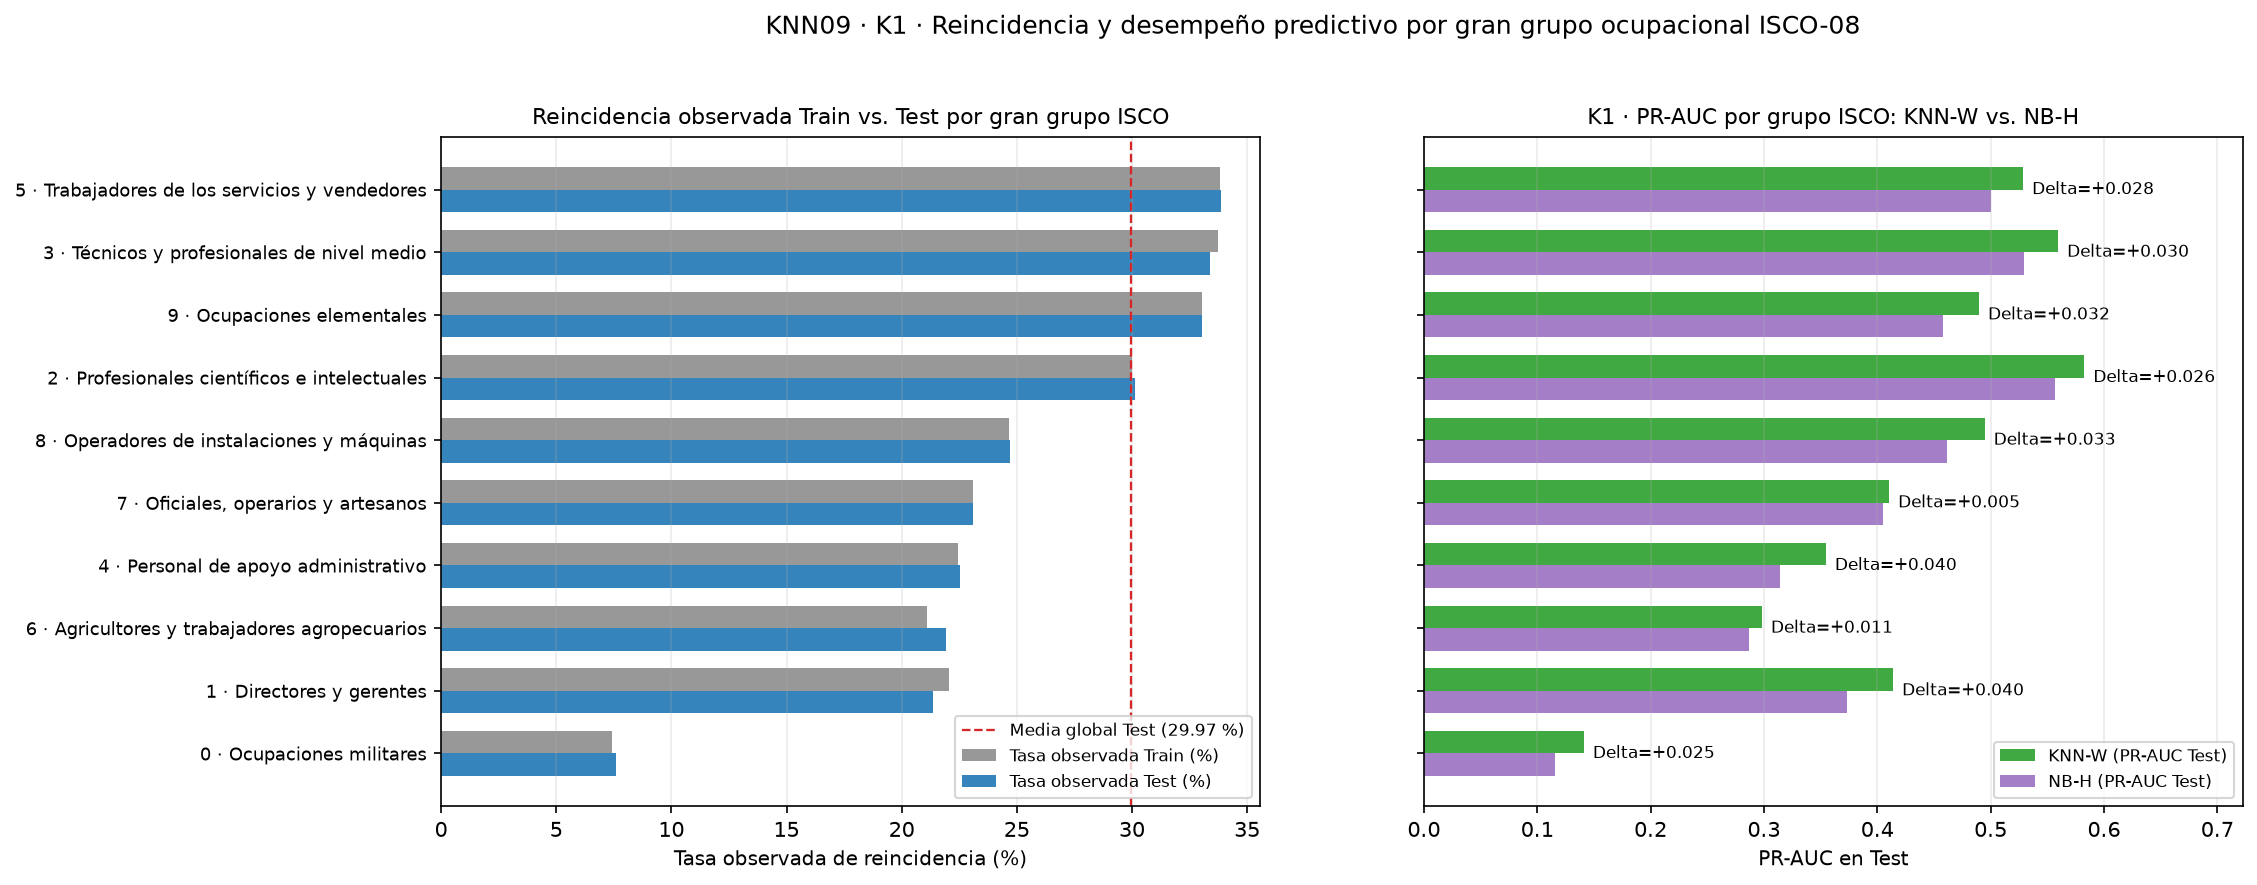

=== K2 · Explicación basada en casos (6 perfiles típicos y top-5 vecinos) ===


,perfil_id,perfil_descripcion,fila_test_idx,gran_grupo_isco,ocupacion_esco,job_order,duracion_trimestres,anio_inicio,es_vigente,nivel_educativo,skills_esenciales,k_vecinos,vecinos_con_reincide_1,pureza_misma_ocupacion_pct,pureza_mismo_isco_pct,dist_vecino_1,dist_vecino_k,prob_knn_pct,prob_knn_directa_pct,prob_nb_h_pct,y_real
0,K2-01 (P2-01),1. Carrera corta y reciente (primer empleo),104,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,0,Secondary school,17.0000,101,20/101 (19.8%),100.0000,100.0000,0.0000,0.7434,19.8000,19.8000,27.8800,0
1,K2-02 (P2-02),2. Carrera larga con empleo vigente,62,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,8,45.0000,2015,1,Bachelor,33.0000,101,21/101 (20.8%),100.0000,100.0000,0.7339,3.1309,20.7900,20.7900,21.9000,0
2,K2-03 (P2-03),3. Ocupación de alta exigencia de competencias ESCO (>= P90),18,2 · Profesionales científicos e intelectuales,2221.2 · nurse responsible for general care,3,2.0000,2011,0,Bachelor,92.0000,101,77/101 (76.2%),100.0000,100.0000,0.0000,0.3852,76.2400,76.2400,86.7300,0
3,K2-04 (P2-04),4. Educación 'No reportado' en trayectoria media,325,5 · Trabajadores de los servicios y vendedores,5311.1.2 · babysitter,3,5.0000,2009,0,No reportado,10.0000,101,31/101 (30.7%),100.0000,100.0000,0.0000,0.9848,30.6900,30.6900,28.6100,0
4,K2-05 (P2-05),5. Grupo ISCO de mayor reincidencia (5 · Trabajadores de los servicios y vendedores) con rotación previa,25,5 · Trabajadores de los servicios y vendedores,5312.1 · early years teaching assistant,6,2.0000,2018,0,Bachelor,19.0000,101,65/101 (64.4%),100.0000,100.0000,0.0447,0.3635,64.3600,64.3600,65.5000,1
5,K2-06 (P2-06),6. Grupo ISCO de menor reincidencia (0 · Ocupaciones militares) en primer empleo,1513,0 · Ocupaciones militares,0310.3 · infantry soldier,1,5.0000,1989,0,Secondary school,12.0000,101,1/101 (1.0%),100.0000,100.0000,0.0000,1.0158,0.9900,0.9900,4.0300,0


,perfil_id,rango_vecino,distancia,misma_ocupacion_esco,mismo_grupo_isco,gran_grupo_isco_vecino,ocupacion_esco_vecino,job_order_vecino,duracion_trim_vecino,anio_inicio_vecino,nivel_educativo_vecino,reincide_vecino
0,K2-01 (P2-01),1,0.0000,Sí,Sí,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,Secondary school,0
1,K2-01 (P2-01),2,0.0000,Sí,Sí,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,Secondary school,0
2,K2-01 (P2-01),3,0.0000,Sí,Sí,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,Secondary school,0
3,K2-01 (P2-01),4,0.0000,Sí,Sí,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,Secondary school,0
4,K2-01 (P2-01),5,0.0000,Sí,Sí,5 · Trabajadores de los servicios y vendedores,5244.1 · call centre agent,1,5.0000,2017,Secondary school,0
5,K2-02 (P2-02),1,0.7339,Sí,Sí,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,8,57.0000,2012,Bachelor,1
6,K2-02 (P2-02),2,0.7619,Sí,Sí,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,10,49.0000,2014,Bachelor,0
7,K2-02 (P2-02),3,0.8177,Sí,Sí,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,7,57.0000,2012,Bachelor,0
8,K2-02 (P2-02),4,1.0292,Sí,Sí,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,6,57.0000,2012,Bachelor,0
9,K2-02 (P2-02),5,1.1207,Sí,Sí,2 · Profesionales científicos e intelectuales,2433.6.4 · technical sales representative in machinery and industrial equipment,8,45.0000,2015,Secondary school,0


=== K3 · Deciles de riesgo, perfil D10 vs. D01 y composición ISCO ===


,decil_riesgo,decil_orden,soporte_test,prob_media_knn_pct,tasa_obs_knn_test_pct,brecha_pred_menos_obs_knn_pp,lift_knn_test,ganancia_acum_knn_pct,tasa_obs_nb_h_test_pct,lift_nb_h_test,ganancia_acum_nb_h_pct,pct_poblacion_acumulada
0,D10 (Mayor riesgo),10,34772,65.5400,63.5800,1.9600,2.1210,21.2100,58.8900,1.9650,19.6500,10.0000
1,D09,9,34772,50.9300,50.1700,0.7600,1.6740,37.9500,48.4600,1.6170,35.8200,20.0000
2,D08,8,34772,42.1300,41.4800,0.6500,1.3840,51.7900,41.4900,1.3840,49.6600,30.0000
3,D07,7,34772,35.2600,34.3300,0.9300,1.1450,63.2400,34.6800,1.1570,61.2300,40.0000
4,D06,6,34772,29.5400,29.1100,0.4400,0.9710,72.9500,29.9300,0.9980,71.2100,50.0000
5,D05,5,34772,24.6300,23.8000,0.8300,0.7940,80.8900,24.8600,0.8290,79.5100,60.0000
6,D04,4,34772,20.1600,19.4800,0.6800,0.6500,87.3900,20.8900,0.6970,86.4800,70.0000
7,D03,3,34772,16.0000,16.1300,-0.1300,0.5380,92.7700,16.9700,0.5660,92.1400,80.0000
8,D02,2,34772,11.8200,12.5200,-0.7000,0.4180,96.9500,13.5100,0.4510,96.6500,90.0000
9,D01 (Menor riesgo),1,34772,6.3200,9.1400,-2.8200,0.3050,100.0000,10.0500,0.3350,100.0000,100.0000


,indicador_unidades_originales,D01_KNN,D10_KNN,diff_D10_menos_D01_KNN,D01_NB_H,D10_NB_H
0,Soporte de filas (test),"34,772","34,772",0,"34,772","34,772"
1,Tasa observada de reincidencia (%),9.1400,63.5800,54.4300,10.0500,58.8900
2,Empleos previos acumulados (media / mediana),2.40 / 2.0,4.85 / 4.0,2.4400,2.44 / 2.0,3.80 / 3.0
3,Duración del empleo en trimestres (media / mediana),18.08 / 9.0,7.19 / 4.0,-10.8900,30.52 / 13.0,6.11 / 5.0
4,Año de inicio (media / mediana),2006.8 / 2010,2009.9 / 2011,3.0200,2004.5 / 2008,2010.3 / 2012
5,Competencias esenciales ESCO (media / mediana),21.20 / 18.0,29.04 / 24.0,7.8400,19.37 / 17.0,31.90 / 27.0
6,Proporción de empleos vigentes (%),6.9300,3.0800,-3.8500,16.9300,0.8200


,isco_major,gran_grupo_isco,participacion_test_total_pct,participacion_D01_KNN_pct,participacion_D10_KNN_pct,diff_D10_menos_D01_KNN_pp,participacion_D01_NB_H_pct,participacion_D10_NB_H_pct,sobremuestreo_D10_KNN_vs_total
0,0,0 · Ocupaciones militares,0.2300,1.6200,0.0000,-1.6200,1.7600,0.0000,0.0000
1,1,1 · Directores y gerentes,5.7200,10.0800,1.7300,-8.3500,9.9600,0.9800,0.3000
2,2,2 · Profesionales científicos e intelectuales,17.5700,23.6200,28.1200,4.5000,22.0600,36.9500,1.6000
3,3,3 · Técnicos y profesionales de nivel medio,19.6100,18.2100,31.9700,13.7700,18.2500,47.1200,1.6300
4,4,4 · Personal de apoyo administrativo,7.9900,7.1100,0.6400,-6.4800,7.1400,0.0000,0.0800
5,5,5 · Trabajadores de los servicios y vendedores,21.8000,13.2700,22.0900,8.8200,11.2100,9.0400,1.0100
6,6,6 · Agricultores y trabajadores agropecuarios,0.3600,0.5900,0.0000,-0.5900,0.5800,0.0000,0.0000
7,7,"7 · Oficiales, operarios y artesanos",7.1900,10.6400,1.8100,-8.8300,11.7000,2.2700,0.2500
8,8,8 · Operadores de instalaciones y máquinas,5.7800,9.4600,3.8800,-5.5800,11.6300,2.6500,0.6700
9,9,9 · Ocupaciones elementales,13.7600,5.4000,9.7600,4.3600,5.7000,0.9800,0.7100


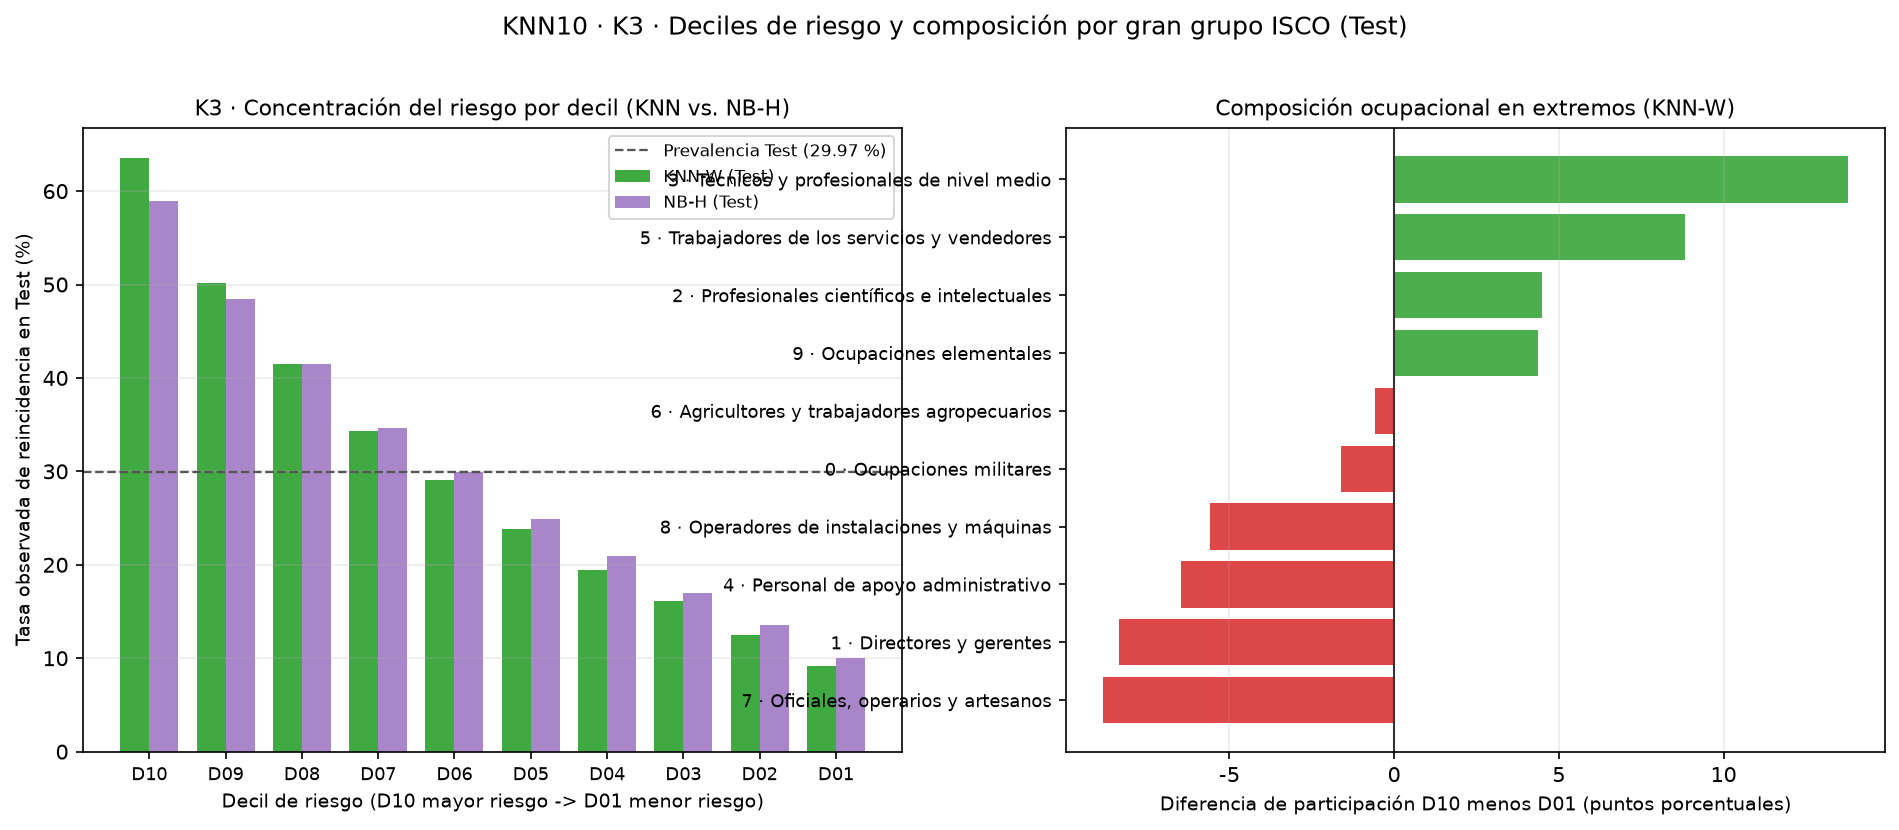

=== K4 · Concordancia y desacuerdo con NB-H ===
Resumen K4: {'spearman_rho_test': 0.8757, 'pearson_r_test': 0.8704, 'acuerdo_binario_igual_alerta_pct': 86.02, 'desacuerdo_binario_igual_alerta_pct': 13.98, 'cohen_kappa_igual_alerta': 0.7196, 'tasa_alerta_knn_pct': 53.63, 'tasa_alerta_nb_h_pct': 51.78, 'pr_auc_knn_test': 0.5247, 'pr_auc_nb_h_test': 0.4962, 'pr_auc_promedio_rangos_50_50_descriptivo': 0.5232, 'roc_auc_promedio_rangos_50_50_descriptivo': 0.722, 'ganancia_complementariedad_pr_auc_vs_mejor': -0.0014}


,celda_concordancia,filas_test,pct_del_test,tasa_obs_reincidencia_test_pct,prob_media_knn_pct,prob_media_nb_h_pct
0,Ambos predicen 1 (Acuerdo positivo),158941,45.7100,44.9300,45.6200,44.9000
1,Solo KNN predice 1 (Desacuerdo KNN+ / NB-H-),27527,7.9200,28.4100,30.8000,21.3400
2,Solo NB-H predice 1 (Desacuerdo KNN- / NB-H+),21095,6.0700,21.0900,20.0100,33.5800
3,Ambos predicen 0 (Acuerdo negativo),140157,40.3100,14.6600,14.2200,14.5400


,isco_major,gran_grupo_isco,soporte_train,soporte_test,tasa_obs_train_pct,tasa_obs_test_pct,brecha_test_menos_train_pp,alerta_brecha_mayor_5pp,spearman_rho_grupo,desacuerdo_total_pct,solo_knn_alerta_pct,solo_nb_h_alerta_pct
0,4,4 · Personal de apoyo administrativo,111705,27784,22.4600,22.5500,0.0900,False,0.7503,19.2300,14.9900,4.2400
1,6,6 · Agricultores y trabajadores agropecuarios,5080,1241,21.1200,21.9200,0.8000,False,0.8078,16.5200,2.5800,13.9400
2,1,1 · Directores y gerentes,81000,19873,22.0700,21.3700,-0.7000,False,0.8372,16.0200,10.7200,5.3000
3,9,9 · Ocupaciones elementales,189819,47849,33.0300,33.0500,0.0200,False,0.7883,15.4200,8.3500,7.0700
4,5,5 · Trabajadores de los servicios y vendedores,302706,75803,33.8400,33.8700,0.0200,False,0.8305,13.8800,5.9100,7.9700
5,7,"7 · Oficiales, operarios y artesanos",100371,25002,23.1100,23.0800,-0.0200,False,0.8671,13.3400,9.6000,3.7400
6,8,8 · Operadores de instalaciones y máquinas,80665,20103,24.6600,24.7100,0.0500,False,0.9036,13.0600,9.8700,3.1900
7,2,2 · Profesionales científicos e intelectuales,243705,61082,29.9800,30.1300,0.1600,False,0.8914,12.6900,6.1800,6.5100
8,3,3 · Técnicos y profesionales de nivel medio,272574,68181,33.7200,33.3700,-0.3600,False,0.8926,12.1200,6.7000,5.4200
9,0,0 · Ocupaciones militares,3393,802,7.4300,7.6100,0.1800,False,0.7207,1.5000,0.2500,1.2500


,celda_concordancia,soporte_test,tasa_obs_reincide_pct,empleos_previos_mediana,duracion_mediana_trim,anio_inicio_mediana,skills_esenciales_mediana,pct_empleo_vigente,gran_grupo_isco_modal,nivel_educativo_modal
0,Ambos predicen 1 (Acuerdo positivo),158941,44.9300,3.0000,5.0000,2011,22.0000,3.1000,5 · Trabajadores de los servicios y vendedores,Secondary school
1,Solo KNN predice 1 (Desacuerdo KNN+ / NB-H-),27527,28.4100,3.0000,7.0000,2009,16.0000,13.5600,3 · Técnicos y profesionales de nivel medio,Secondary school
2,Solo NB-H predice 1 (Desacuerdo KNN- / NB-H+),21095,21.0900,1.0000,6.0000,2011,22.0000,1.4100,5 · Trabajadores de los servicios y vendedores,Bachelor
3,Ambos predicen 0 (Acuerdo negativo),140157,14.6600,2.0000,7.0000,2010,18.0000,7.0600,2 · Profesionales científicos e intelectuales,Secondary school


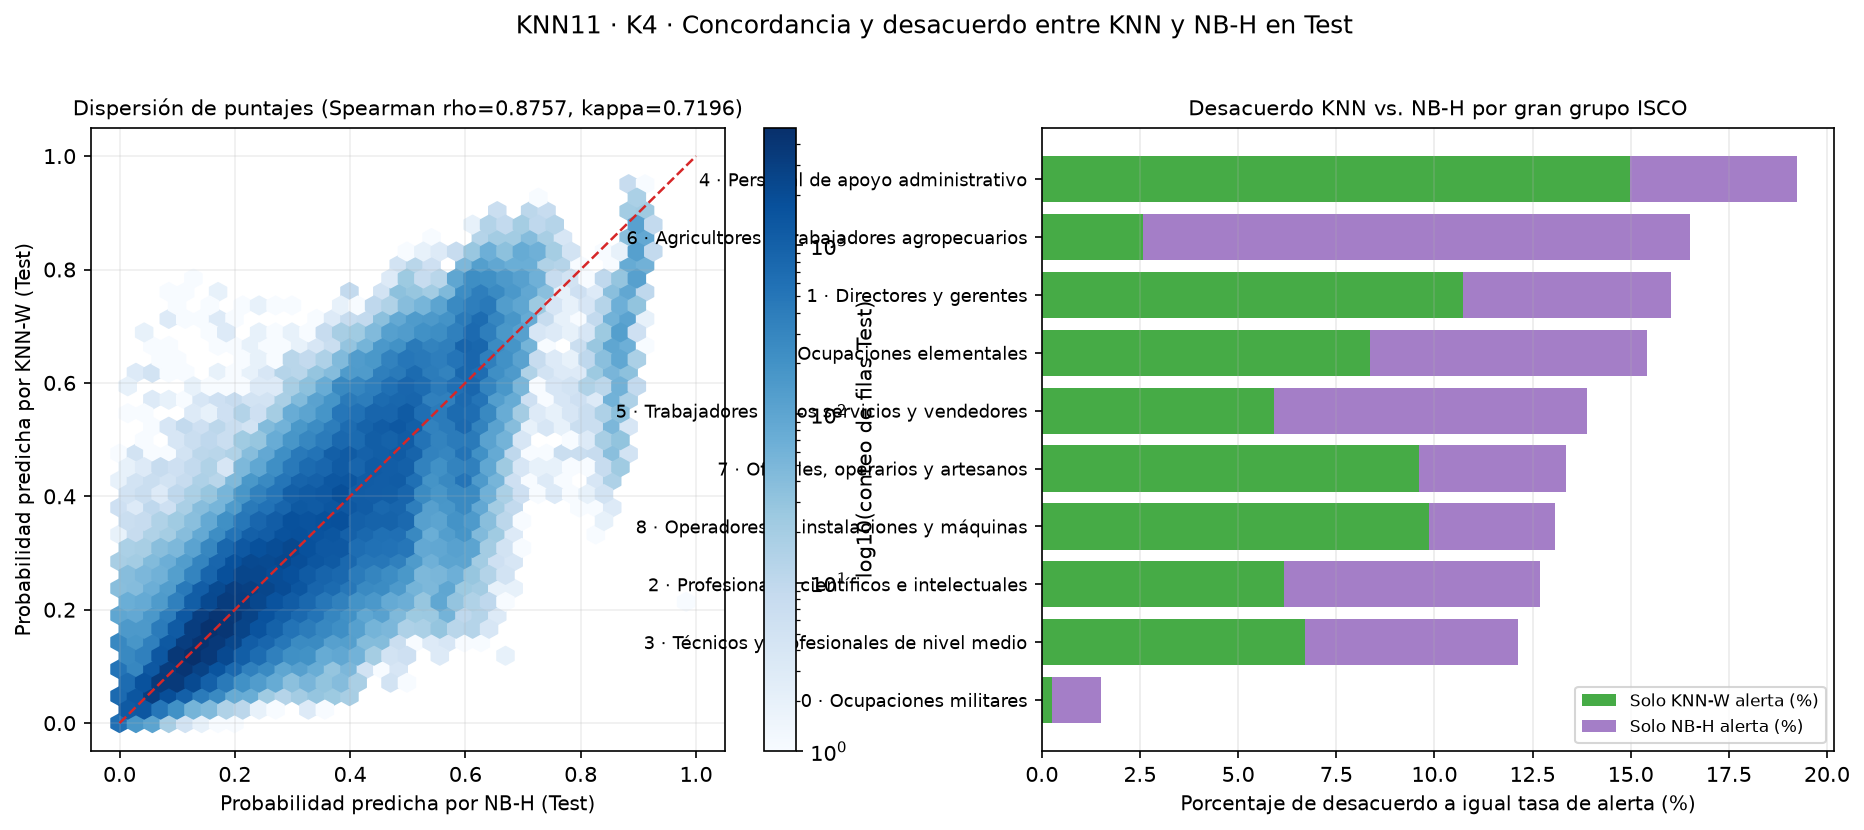

=== K5 · Análisis de errores (TP, FP, FN, TN y subgrupos) ===


,celda_confusion,soporte_test,pct_total_test,prob_media_knn_pct,empleos_previos_mediana,empleos_previos_media,duracion_mediana_trim,duracion_media_trim,anio_inicio_mediana,skills_esenciales_mediana,pct_empleo_vigente,gran_grupo_isco_modal,nivel_educativo_modal
0,"TP · Verdadero Positivo (reincide=1, pred=1)",73758,21.2100,49.1600,3.0000,3.7700,5.0000,9.2900,2011,22.0000,4.2000,5 · Trabajadores de los servicios y vendedores,Secondary school
1,"FP · Falso Positivo (reincide=0, pred=1)",91671,26.3600,42.6600,3.0000,3.1800,5.0000,10.4600,2011,22.0000,4.7500,5 · Trabajadores de los servicios y vendedores,Secondary school
2,"FN · Falso Negativo (reincide=1, pred=0)",30467,8.7600,18.6300,2.0000,2.8300,5.0000,14.4100,2010,19.0000,6.7300,2 · Profesionales científicos e intelectuales,Secondary school
3,"TN · Verdadero Negativo (reincide=0, pred=0)",151824,43.6600,15.8700,2.0000,2.4800,7.0000,15.6400,2010,19.0000,6.1600,2 · Profesionales científicos e intelectuales,Secondary school


,dimension,subgrupo,soporte_train,soporte_test,tasa_obs_train_pct,tasa_obs_test_pct,brecha_test_menos_train_pp,alerta_brecha_mayor_5pp,tasa_error_global_test_pct,FPR_falsos_positivos_pct,FNR_falsos_negativos_pct,tipo_fallo_dominante
0,Gran grupo ISCO,0 · Ocupaciones militares,3393,802,7.4300,7.6100,0.1800,False,7.6100,0.0000,100.0000,Falsos Negativos (omisión)
1,Gran grupo ISCO,1 · Directores y gerentes,81000,19873,22.0700,21.3700,-0.7000,False,27.2600,20.8400,50.8800,Falsos Negativos (omisión)
2,Gran grupo ISCO,2 · Profesionales científicos e intelectuales,243705,61082,29.9800,30.1300,0.1600,False,30.5300,30.3500,30.9400,Falsos Negativos (omisión)
3,Gran grupo ISCO,3 · Técnicos y profesionales de nivel medio,272574,68181,33.7200,33.3700,-0.3600,False,36.4400,43.4900,22.3600,Falsos Positivos (sobrepredicción)
4,Gran grupo ISCO,4 · Personal de apoyo administrativo,111705,27784,22.4600,22.5500,0.0900,False,29.7900,21.7700,57.3700,Falsos Negativos (omisión)
5,Gran grupo ISCO,5 · Trabajadores de los servicios y vendedores,302706,75803,33.8400,33.8700,0.0200,False,40.4800,50.8000,20.3200,Falsos Positivos (sobrepredicción)
6,Gran grupo ISCO,6 · Agricultores y trabajadores agropecuarios,5080,1241,21.1200,21.9200,0.8000,False,33.9200,26.7300,59.5600,Falsos Negativos (omisión)
7,Gran grupo ISCO,"7 · Oficiales, operarios y artesanos",100371,25002,23.1100,23.0800,-0.0200,False,30.6000,25.0600,49.0600,Falsos Negativos (omisión)
8,Gran grupo ISCO,8 · Operadores de instalaciones y máquinas,80665,20103,24.6600,24.7100,0.0500,False,29.4400,26.0200,39.8600,Falsos Negativos (omisión)
9,Gran grupo ISCO,9 · Ocupaciones elementales,189819,47849,33.0300,33.0500,0.0200,False,42.2500,51.6200,23.2600,Falsos Positivos (sobrepredicción)


=== K6 · Posición en la carrera (job_order) y período (start_year) ===


,tramo_job_order,soporte_train,tasa_obs_train_pct,soporte_test,tasa_obs_test_pct,ic95_wilson_test_pct,brecha_test_menos_train_pp,alerta_brecha_mayor_5pp,prob_media_knn_test_pct,brecha_knn_menos_obs_test_pp,prob_media_nb_h_test_pct,brecha_nb_h_menos_obs_test_pp
0,1 (1er empleo),263187,21.5800,65882,21.5200,"[21.21, 21.84]",-0.0600,False,25.0400,3.5200,27.8200,6.3000
1,2 (2do empleo),248254,26.3200,62082,26.3900,"[26.05, 26.74]",0.0800,False,27.0100,0.6100,28.6400,2.2500
2,3 (3er empleo),219727,29.1500,55007,29.2300,"[28.85, 29.61]",0.0800,False,28.8000,-0.4300,29.2300,0.0000
3,4–5 empleos,323258,32.2200,81038,31.9800,"[31.66, 32.30]",-0.2400,False,31.3700,-0.6100,30.3100,-1.6700
4,6–8 empleos,233882,36.0000,58496,35.9900,"[35.61, 36.38]",-0.0100,False,35.0100,-0.9800,32.2300,-3.7700
5,9+ empleos,102710,41.8000,25215,42.0800,"[41.47, 42.69]",0.2800,False,40.1300,-1.9500,36.1200,-5.9600


,periodo_anio_inicio,soporte_train,tasa_obs_train_pct,soporte_test,tasa_obs_test_pct,ic95_wilson_test_pct,brecha_test_menos_train_pp,alerta_brecha_mayor_5pp,prob_media_knn_test_pct,brecha_knn_menos_obs_test_pp,prob_media_nb_h_test_pct,brecha_nb_h_menos_obs_test_pp
0,<= 1999,183416,25.8000,45258,25.6200,"[25.22, 26.02]",-0.1800,False,26.3100,0.6900,23.7800,-1.8400
1,2000–2004,136571,28.9700,34004,28.6600,"[28.18, 29.14]",-0.3200,False,28.6300,-0.0300,27.3800,-1.2800
2,2005–2009,298002,30.1400,74736,30.0300,"[29.70, 30.36]",-0.1100,False,29.6700,-0.3600,29.4800,-0.5500
3,2010–2014,499602,31.2300,125364,31.2600,"[31.00, 31.51]",0.0200,False,31.3400,0.0800,31.8100,0.5500
4,2015–2019,273369,30.9900,68349,31.1000,"[30.75, 31.45]",0.1100,False,32.2200,1.1200,33.2500,2.1500


,dimension_temporal_carrera,rango_observado_test_pp,rango_predicho_knn_test_pp,razon_pendiente_knn_sobre_obs,brecha_max_abs_tramo_knn_pp,brecha_media_abs_tramo_knn_pp,rango_predicho_nb_h_test_pp,razon_pendiente_nb_h_sobre_obs,brecha_max_abs_tramo_nb_h_pp
0,Posición en la carrera (job_order: 1er empleo -> 9+),20.5600,15.0900,0.7339,3.5200,1.3500,8.3000,0.4037,6.3000
1,Período calendario (start_year: <=1999 -> 2020+),5.4800,5.9100,1.0785,1.1200,0.4600,9.4700,1.7281,2.1500


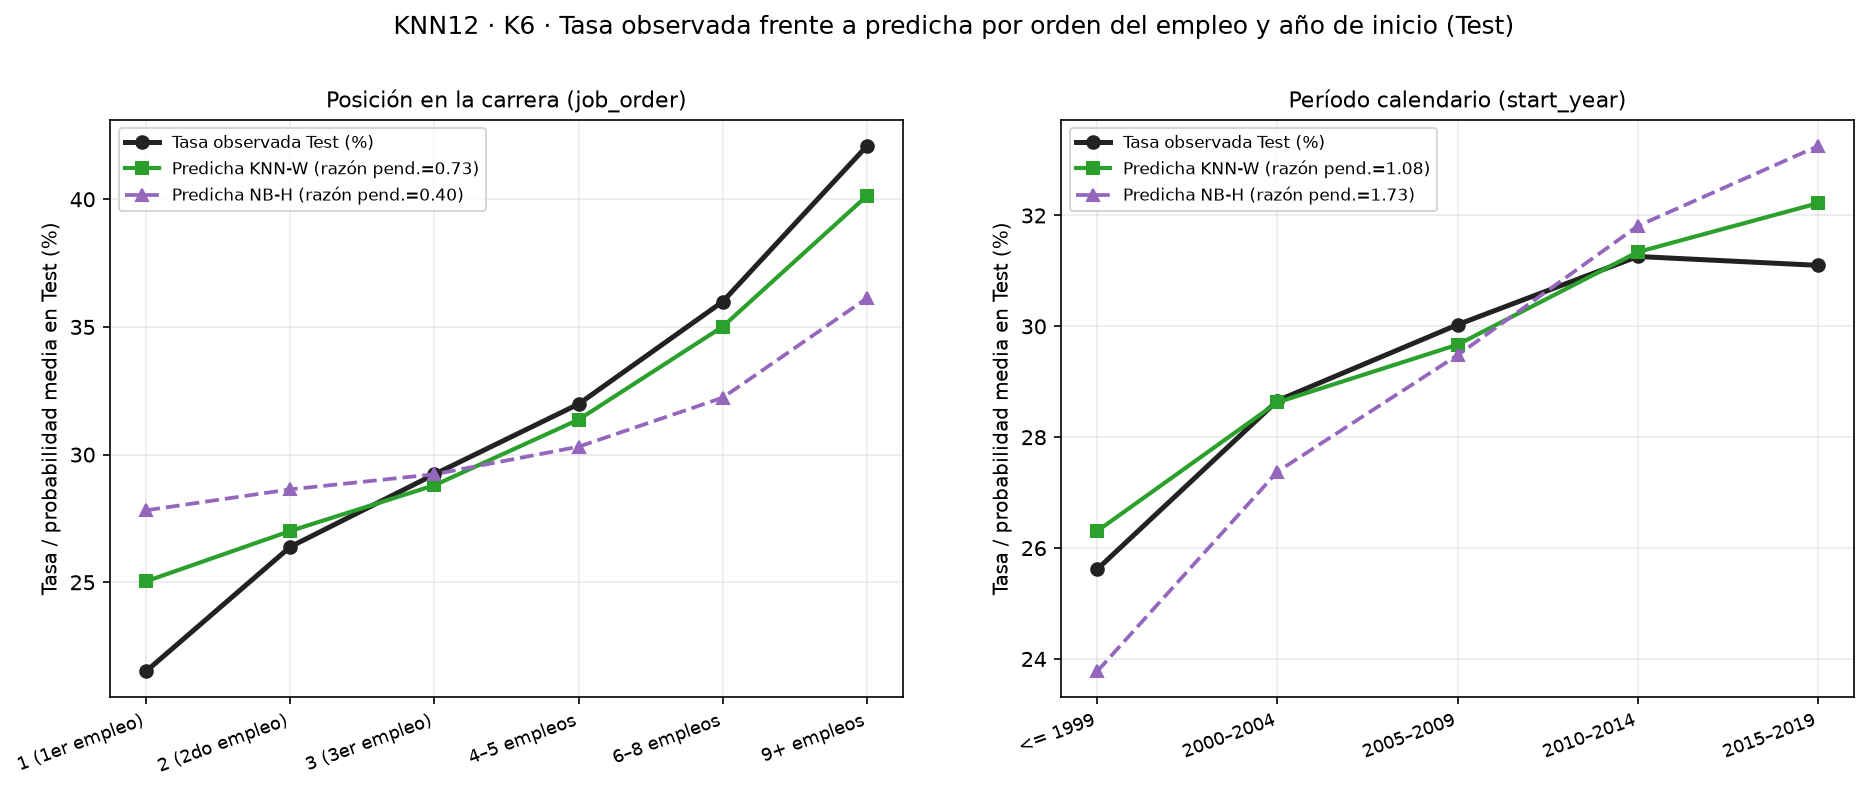

In [13]:
PATTERNS_BUNDLE = PIPELINE.patterns_analyzer.run_all_patterns(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    orig_train=BUNDLE_A.orig_train,
    orig_test=BUNDLE_A.orig_test,
    primary_spec=TUNING_BUNDLE.winner_specs[PRIMARY_KNN_ID],
    knn_test_proba=EVAL_BUNDLE.test_proba_by_model[PRIMARY_KNN_ID],
    knn_tau_oof=THRESHOLD_BUNDLE.oof_thresholds_tau[PRIMARY_KNN_ID],
    nb_h_test_proba=EVAL_BUNDLE.baseline_test_proba["NB-H"],
    nb_h_tau=EVAL_BUNDLE.baseline_thresholds["NB-H"],
    eval_row_idx_test=EVAL_BUNDLE.eval_row_idx_test,
)

FIG_KNN09 = PIPELINE.plotter.plot_k1_isco_comparison(PATTERNS_BUNDLE)
FIG_KNN10 = PIPELINE.plotter.plot_k3_deciles_and_isco(PATTERNS_BUNDLE)
FIG_KNN11 = PIPELINE.plotter.plot_k4_agreement(
    PATTERNS_BUNDLE,
    knn_prob=EVAL_BUNDLE.test_proba_by_model[PRIMARY_KNN_ID],
    nb_h_prob=EVAL_BUNDLE.baseline_test_proba["NB-H"],
)
FIG_KNN12 = PIPELINE.plotter.plot_k6_career_and_period(PATTERNS_BUNDLE)

print("=== K1 · Desempeño por gran grupo ISCO (KNN vs. NB-H) ===")
display(PATTERNS_BUNDLE.k1_isco_performance_table)
display(Image(filename=str(FIG_KNN09)))

print("=== K2 · Explicación basada en casos (6 perfiles típicos y top-5 vecinos) ===")
display(PATTERNS_BUNDLE.k2_case_explanations.profiles_summary_table)
display(PATTERNS_BUNDLE.k2_case_explanations.neighbors_detail_table)

print("=== K3 · Deciles de riesgo, perfil D10 vs. D01 y composición ISCO ===")
display(PATTERNS_BUNDLE.k3_deciles_table)
display(PATTERNS_BUNDLE.k3_top_vs_bottom_profile_table)
display(PATTERNS_BUNDLE.k3_isco_composition_table)
display(Image(filename=str(FIG_KNN10)))

print("=== K4 · Concordancia y desacuerdo con NB-H ===")
print("Resumen K4:", PATTERNS_BUNDLE.k4_agreement_summary)
display(PATTERNS_BUNDLE.k4_crosstab_table)
display(PATTERNS_BUNDLE.k4_disagreement_by_isco_table)
display(PATTERNS_BUNDLE.k4_disagreement_profiles_table)
display(Image(filename=str(FIG_KNN11)))

print("=== K5 · Análisis de errores (TP, FP, FN, TN y subgrupos) ===")
display(PATTERNS_BUNDLE.k5_error_profiles_table)
display(PATTERNS_BUNDLE.k5_error_subgroups_table)

print("=== K6 · Posición en la carrera (job_order) y período (start_year) ===")
display(PATTERNS_BUNDLE.k6_job_order_table)
display(PATTERNS_BUNDLE.k6_start_year_table)
display(PATTERNS_BUNDLE.k6_slope_summary_table)
display(Image(filename=str(FIG_KNN12)))


### Lectura

*(Nota metodológica global: todos los análisis `K1`–`K6` se ejecutan sobre la Versión A en unidades originales con soporte mínimo de `200` filas en `train`; las predicciones sobre `test` se usan exclusivamente de forma descriptiva. En todos los subgrupos se compararon las tasas observadas de `train` y `test` y **ningún subgrupo presentó brecha superior a `5` puntos porcentuales**: la mayor diferencia fue `+0.80 pp` en el grupo `6 · Agricultores`, de menor soporte. Todas las relaciones son **asociaciones observables**, nunca causalidad.)*

#### Hallazgos por bloque (`K1` a `K6`)

- **K1 · Desempeño por gran grupo ocupacional ISCO-08 (`12_k1_desempeno_por_isco_knn_vs_nb_h.csv`, figura `KNN09`):**
  - `KNN-W` supera a `NB-H` de forma estadísticamente distinguible (IC 95 % pareado por persona excluyendo `0` en `PR-AUC`) en **`7` de los `10` grandes grupos**: `4 · Personal de apoyo administrativo` (`0.3546` vs. `0.3142`, $\Delta =$ `0.0404`, `[+0.0294, +0.0506]`; `F1` igual alerta `+0.0502`), `1 · Directores y gerentes` (`0.4139` vs. `0.3737`, $\Delta =$ `0.0402`, `[+0.0317, +0.0508]`; `F1` `+0.0367`), `8 · Operadores de instalaciones y máquinas` (`0.4947` vs. `0.4615`, $\Delta =$ `0.0332`, `[+0.0240, +0.0435]`), `9 · Ocupaciones elementales` (`0.4897` vs. `0.4578`, $\Delta =$ `0.0319`, `[+0.0255, +0.0384]`), `3 · Técnicos y profesionales de nivel medio` (`0.5595` vs. `0.5291`, $\Delta =$ `0.0304`, `[+0.0252, +0.0361]`), `5 · Trabajadores de los servicios y vendedores` (`0.5286` vs. `0.5004`, $\Delta =$ `0.0282`, `[+0.0236, +0.0328]`) y `2 · Profesionales científicos e intelectuales` (`0.5826` vs. `0.5565`, $\Delta =$ `0.0261`, `[+0.0216, +0.0309]`, grupo con el mayor `PR-AUC` y `ROC-AUC = 0.7556` del conjunto).
  - En los `3` grupos restantes **no hay diferencia distinguible** en `PR-AUC` (IC 95 % incluye `0`): `7 · Oficiales, operarios y artesanos` (`+0.0055`, `[-0.0011, +0.0127]`, aunque `KNN-W` mejora en `ROC-AUC` `+0.0102` y `F1` igual alerta `+0.0181`), `6 · Agricultores y trabajadores agropecuarios` (`+0.0115`, `[-0.0264, +0.0478]`, soporte acotado de `1,241` filas en `test`) y `0 · Ocupaciones militares` (`+0.0251`, `[-0.0665, +0.1153]`, soporte de `802` filas y tasa de reincidencia de apenas `7.61 %`, donde las probabilidades de `KNN-W` promedian `6.89 %` y ninguna supera el corte global de alerta).
  - **Hipótesis sobre la ventaja por grupo:** `NB-H` asume independencia condicional entre la ocupación y las variables de trayectoria, mientras que `KNN-W` captura combinaciones locales específicas de oficio, duración y orden laboral; esto explicaría por qué la ventaja relativa de `KNN-W` es mayor en grupos heterogéneos de tasa intermedia (`4 · Administrativos` y `1 · Directores`). Asimismo, aunque entre los `10` grupos el `PR-AUC` se asocia positivamente con la tasa de reincidencia y con el tamaño muestral, cualquier correlación calculada sobre solo `10` grupos es frágil y se interpreta únicamente como tendencia descriptiva.
- **K2 · Explicación basada en casos en unidades originales (`12_k2a`, `12_k2b`):** en los `6` perfiles típicos alineados con `P2` de `7.1`, los `101` vecinos recuperados por `KNN-W` exhiben **`100.0 %` de pureza de misma ocupación ESCO y mismo gran grupo ISCO**, ofreciendo una explicación directa por ejemplos reales. En `K2-03` (`nurse responsible for general care`, `92.0` skills, `job_order = 3`, `2.0` trimestres), `77` de `101` vecinos reincidieron (`76.24 %`, frente a `86.73 %` en `NB-H`; los `5` vecinos más cercanos están a distancia `0.0`). En `K2-05` (`early years teaching assistant`, grupo `5`, `job_order = 6`, `2.0` trimestres), `65` de `101` reincidieron (`64.36 %`). En contraste, en `K2-06` (`infantry soldier`, grupo `0`, primer empleo, `1989`), solo `1` de `101` vecinos reincidió (`0.99 %`, `NB-H` `4.03 %`), y en `K2-01` (`call centre agent`, grupo `5`, primer empleo, `2017`), `KNN-W` estima `19.80 %` (`20/101`) frente a `27.88 %` de `NB-H`, moderando el riesgo por ser primer empleo. En `K2-02` (carrera larga vigente de `45.0` trimestres y `job_order = 8`), las distancias al vecindario son claramente mayores (`0.7339` a `3.1309`), reflejando menor densidad de casos extremos.
- **K3 · Deciles de riesgo, perfil `D10` vs. `D01` y composición ISCO (`12_k3a`, `12_k3b`, `12_k3c`, figura `KNN10`):** en `test` (`34,772` filas por decil), la reincidencia observada crece de forma estrictamente monótona desde `9.14 %` en `D01` (*lift* `0.305`) hasta `63.58 %` en `D10` (*lift* `2.121`, concentrando `21.21 %` de todos los casos reincidentes en el `10 %` superior y `51.79 %` en los tres deciles altos `D08`–`D10`). Frente a `NB-H`, `KNN-W` eleva la concentración en `D10` (`63.58 %` vs. `58.89 %`, *lift* `2.121` vs. `1.965`) y reduce la contaminación en `D01` (`9.14 %` vs. `10.05 %`). Comparando `D10` frente a `D01` (`12_k3b`), los casos de mayor riesgo acumulan más del doble de empleos previos (`4.85` vs. `2.40` de media), duran menos de la mitad (`7.19` vs. `18.08` trimestres), tienen más competencias esenciales (`29.04` vs. `21.20`) y menos empleos vigentes (`3.08 %` vs. `6.93 %`). En composición ISCO (`12_k3c`), `NB-H` concentraba `D10` casi solo en Técnicos (`47.12 %`) y Profesionales (`36.95 %`), mientras que `KNN-W` rebalancea `D10` manteniendo fuerte presencia de Técnicos (`31.97 %`) y Profesionales (`28.12 %`), pero incorporando a Servicios y vendedores (`22.09 %` vs. `9.04 %` en `NB-H`) y Ocupaciones elementales (`9.76 %` vs. `0.98 %`).
- **K4 · Concordancia, desacuerdo y complementariedad con `NB-H` (`12_k4a`, `12_k4b`, `12_k4c`, figura `KNN11`):** ambos modelos presentan alta concordancia global en `test` (Spearman $\rho =$ `0.8757`, Pearson $r =$ `0.8704`, acuerdo binario a igual tasa de alerta de `86.02 %`, $\kappa =$ `0.7196`). Cuando ambos alertan (`45.71 %` de `test`), la tasa observada es `44.93 %`; cuando ambos descartan (`40.31 %`), cae a `14.66 %`. En el `13.98 %` donde discrepan, **`KNN-W` acierta mejor**: donde solo `KNN-W` alerta (`7.92 %`, `27,527` filas, con `13.56 %` de empleos vigentes y mediana `3.0` empleos previos, predominando ISCO `3`, `4` y `1`), la tasa real es `28.41 %` (cercana a su media predicha `30.80 %`), mientras que donde solo `NB-H` alerta (`6.07 %`, `21,095` filas, mayoritariamente primeros empleos con mediana `1.0` y `22.0` competencias en ISCO `5`), la tasa real cae a `21.09 %` pese a que `NB-H` predecía `33.58 %`. El desacuerdo es máximo en `4 · Personal de apoyo administrativo` (`19.23 %`, $\rho =$ `0.7503`) y `6 · Agricultores` (`16.52 %`). Un ensamble descriptivo `50/50` por promedio de rangos obtiene `PR-AUC = 0.5232` (`-0.0014` frente a `KNN-W` solo `0.5247`), mostrando que `NB-H` **no añade complementariedad neta** sobre `KNN-W` en una mezcla simple.
- **K5 · Análisis de errores (`12_k5a`, `12_k5b`):** al umbral OOF $\tau^* =$ `0.28`, el `26.36 %` de `test` son falsos positivos (`91,671` filas, perfil casi superpuesto al de los `TP`: mediana `3.0` empleos, `5.0` trimestres, `22.0` competencias, grupo modal `5`) y el `8.76 %` son falsos negativos (`30,467` filas, empleos más largos de `14.41` trimestres en promedio y grupo modal `2`). Por subgrupo (`12_k5b`), el corte global único produce una asimetría clara: en los grupos de prevalencia alta (`5 · Servicios`, `9 · Elementales`, `3 · Técnicos`) y en carreras de `6+` empleos dominan los **Falsos Positivos** (`FPR` de `43.49 %` a `51.62 %`), mientras que en los grupos de menor prevalencia (`0 · Militares` `FNR = 100.00 %`, `6 · Agricultores` `59.56 %`, `4 · Administrativos` `57.37 %`, `1 · Directores` `50.88 %`, `7 · Operarios` `49.06 %`) y en el primer empleo (`FNR = 39.82 %`) dominan los **Falsos Negativos**.
- **K6 · Posición en la carrera (`job_order`) y período (`start_year`) (`12_k6a`, `12_k6b`, `12_k6c`, figura `KNN12`):**
  - En `job_order`, la tasa observada en `test` prácticamente se duplica de `21.52 %` (`1er empleo`, `65,882` filas; `21.58 %` en `train`) a `42.08 %` (`9+ empleos`, `25,215` filas; `41.80 %` en `train`), un rango de `20.56 pp`. `KNN-W` captura `15.09 pp` (de `25.04 %` a `40.13 %`, **razón de pendiente `0.7339`** frente a apenas `0.4037` en `NB-H`), con brecha máxima absoluta de `3.52 pp` en el primer empleo (vs. `6.30 pp` en `NB-H`) y brecha media absoluta de `1.35 pp`; la compresión residual en los extremos refleja el suavizado inherente a promediar `k = 101` vecinos.
  - En `start_year`, la tasa observada sube de `25.62 %` (`<= 1999`, `45,258` filas) a `31.26 %` (`2010–2014`, `125,364` filas) y `31.10 %` (`2015–2019`, `68,349` filas; rango `5.48 pp`). `KNN-W` reproduce el patrón temporal con gran fidelidad (rango predicho `5.91 pp`, **razón de pendiente `1.0785`**, brecha máxima `1.12 pp`, media `0.46 pp`), corrigiendo la sobrependiente de `NB-H` (`1.7281`, rango `9.47 pp`). Como **hipótesis**, la menor tasa observada antes del año `2000` y la meseta en `2015–2019` pueden asociarse con efectos de censura en los bordes de la ventana histórica de los currículums.

---

#### Síntesis de `7` patrones en lenguaje de negocio (`5` centrados en grupos ocupacionales ISCO)

1. **Brecha estructural y estable de reincidencia entre grandes grupos ISCO (Patrón ocupacional):** en JobPath la reincidencia se concentra en tres grandes grupos —`5 · Trabajadores de los servicios y vendedores` (`33.84 %` en `train`, `302,706` filas; `33.87 %` en `test`, `75,803` filas), `3 · Técnicos y profesionales de nivel medio` (`33.72 %` en `train`, `272,574`; `33.37 %` en `test`, `68,181`) y `9 · Ocupaciones elementales` (`33.03 %` en `train`, `189,819`; `33.05 %` en `test`, `47,849`)—, desciende en `2 · Profesionales` (`29.98 %` / `30.13 %`, `61,082` en `test`), cae a `21.37 %`–`24.71 %` en `1 · Directores`, `4 · Administrativos`, `6 · Agricultores`, `7 · Operarios` y `8 · Operadores`, y toca mínimo en `0 · Ocupaciones militares` (`7.43 %` en `train`, `3,393`; `7.61 %` en `test`, `802`). *Advertencia:* es una asociación histórica entre grupos ocupacionales, no prueba causal de que un oficio cause reincidencia; en `6` y `0` el soporte reducido amplía el IC de Wilson.
2. **Mayor ganancia de la similitud local en grupos de oficina, gestión y operación intermedia (Patrón ocupacional):** `KNN-W` supera de forma distinguible a `NB-H` en `7` de `10` grupos ISCO sobre `test` (`12_k1`), con mayores saltos de `PR-AUC` en `4 · Personal de apoyo administrativo` (`+0.0404`, `[+0.0294, +0.0506]`, soporte `27,784`), `1 · Directores y gerentes` (`+0.0402`, `[+0.0317, +0.0508]`, soporte `19,873`) y `8 · Operadores` (`+0.0332`, `[+0.0240, +0.0435]`, soporte `20,103`), mientras que en `7 · Operarios` (`25,002`), `6 · Agricultores` (`1,241`) y `0 · Militares` (`802`) no hay diferencia distinguible. *Advertencia:* la explicación de interacciones oficio-trayectoria es una **hipótesis** coherente con el contraste `KNN-W` vs. `NB-H`, y en `6` y `0` el bajo soporte limita la potencia estadística.
3. **Captura más equilibrada y potente del decil superior de riesgo `D10` (Patrón ocupacional):** el `10 %` de empleos con mayor puntaje de `KNN-W` en `test` (`34,772` filas, `12_k3a`, `12_k3c`) alcanza `63.58 %` de reincidencia real (*lift* `2.121`) frente a `58.89 %` en `NB-H`, rescatando perfiles de `5 · Servicios y vendedores` (`22.09 %` de `D10` vs. `9.04 %` en `NB-H`) y `9 · Ocupaciones elementales` (`9.76 %` vs. `0.98 %`) junto a `3 · Técnicos` (`31.97 %`) y `2 · Profesionales` (`28.12 %`). *Advertencia:* `D10` concentra riesgo pero aún incluye `36.42 %` de casos que no reinciden; sirve para priorizar orientación laboral, no para decisiones deterministas.
4. **Asimetría operativa de alertas entre grupos ISCO bajo un umbral único (Patrón ocupacional):** al aplicar el umbral global $\tau^* =$ `0.28` en `test` (`12_k5b`), los grupos de mayor prevalencia (`5`, `9`, `3`) concentran tasas altas de falsos positivos (`FPR` `50.80 %`, `51.62 %` y `43.49 %`), mientras que los grupos de baja prevalencia (`0` `FNR = 100.00 %`, `6` `59.56 %`, `4` `57.37 %`, `1` `50.88 %`) sufren mayor omisión. *Advertencia:* si JobPath necesitara cobertura homogénea entre sectores ocupacionales, requeriría definir políticas de corte diferenciadas por grupo (siempre calibradas fuera de `test`).
5. **Explicabilidad por pares del mismo oficio y freno a falsas alertas de `NB-H` (Patrón ocupacional):** con `w = 8`, `KNN-W` evalúa los `6` perfiles `K2` con `100.0 %` de vecinos del mismo oficio exacto, lo que evita disparar falsas alertas en primeros empleos de oficios rotativos como `5 · Servicios`: en las `21,095` filas de `test` donde solo `NB-H` alerta (`12_k4a`, `12_k4c`), la reincidencia observada es solo `21.09 %` (mediana `1.0` empleo previo), frente a `28.41 %` en las `27,527` filas donde solo `KNN-W` alerta (mediana `3.0` empleos previos, `13.56 %` vigentes). *Advertencia:* en ocupaciones ESCO muy raras (con menos de `101` ejemplos en `train`), la pureza de oficio disminuye y el modelo se apoya en oficios distintos con trayectoria similar.
6. **Gradiente monótono de reincidencia a lo largo de la carrera laboral (`job_order`):** la reincidencia observada crece desde `21.52 %` en el primer empleo (`65,882` filas en `test`; `21.58 %` en `263,187` filas de `train`) hasta `42.08 %` en personas con `9+` empleos (`25,215` en `test`; `41.80 %` en `102,710` de `train`), y `KNN-W` reproduce `73.39 %` de esa pendiente (`12_k6c`), casi el doble que `NB-H` (`40.37 %`). *Advertencia:* asociación descriptiva sujeta a efecto mecánico de exposición (quien acumula más empleos ha tenido más oportunidades de repetir oficio).
7. **Trayectorias cortas y no vigentes asociadas al segmento de alto riesgo (`D10` vs. `D01` y `start_year`):** los casos en `D10` en `test` (`34,772` filas) promedian `7.19` trimestres de duración y `3.08 %` de empleos vigentes frente a `18.08` trimestres y `6.93 %` en `D01` (`12_k3b`), mientras la reincidencia por cohorte pasa de `25.62 %` en `<= 1999` (`45,258` filas) a `31.26 %` en `2010–2014` (`125,364` filas), seguida por `KNN-W` con razón de pendiente `1.0785` (`12_k6b`, `12_k6c`). *Advertencia:* los empleos vigentes y los posteriores a `2015` pueden presentar censura por derecha en la observación de futuras reincidencias (**hipótesis**).


---

## 14. Comparación final homogénea, IC 95 % pareados, costos computacionales y recomendación para JobPath

**¿Qué hace?** Presenta las comparaciones metodológicamente justas de las tres variantes KNN frente a las referencias `1`–`3`, los árboles de `7.0`, `NB-B` y `NB-H` de `7.1`, y los modelos de `6.0`: verificación exacta de baselines reproducidos, tablas homogéneas (*like-for-like*: solo denso contra solo denso; con ocupación contra con ocupación), intervalos de confianza al `95 %` por **bootstrap pareado por persona**, comparación de `F1` a igual tasa de alerta que `NB-H`, tabla consolidada de costos (`fit`, predicción por `1,000` filas, memoria y escalabilidad) y figura de frontera desempeño-costo (`KNN13`).

**¿Por qué existe?** Aplica integralmente las lecciones de la revisión de `7.1`: solo se afirma superioridad si el IC 95 % pareado excluye `0`, `HistGradientBoosting` (`14` cols densas) se compara únicamente con modelos densos y el puntaje de Brier se compara exclusivamente entre modelos sin ponderación de clases.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE`. Entrega las tablas `13a` a `13g` y la figura `knn13_frontera_desempeno_vs_costo.png`.

**Papel en el proyecto.** Integra el balance exacto entre poder predictivo, interpretabilidad por ejemplos y costo operativo para formular una recomendación fundamentada para JobPath.


=== Verificación de reproducción exacta de baselines 6.0 y 7.1 ===


,modelo_referencia,n_variables_X,ponderacion_clases,pr_auc_csv,pr_auc_reproducido,diff_abs_pr_auc,roc_auc_csv,roc_auc_reproducido,diff_abs_roc_auc,coincide_tolerancia_5e4
0,NB-B · BernoulliNB (7.1),2971,Sin ponderar (empírico),0.4829,0.4829,0.0000,0.7024,0.7024,0.0000,True
1,NB-H · HybridNaiveBayes (7.1),2981,Sin ponderar (empírico),0.4962,0.4962,0.0000,0.7058,0.7058,0.0000,True
2,Logística Regularizada (6.0),2981,Balanceada (class_weight='balanced'),0.5109,0.5109,0.0000,0.7133,0.7133,0.0000,True
3,HistGradientBoosting (6.0),14,Balanceada (class_weight='balanced'),0.4951,0.4951,0.0000,0.6936,0.6936,0.0000,True


=== Comparación homogénea 1 · Solo bloque denso ===


,modelo,n_variables_X,ponderacion_clases,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_umbral_propio,f1_igual_alerta_NB_H,brier_solo_sin_ponderar
0,KNN-D · Bloque denso auditado (11 cols),11,Sin ponderar (empírico),0.4652,"[0.4609, 0.4693]",0.6677,"[0.6651, 0.6705]",0.5010,0.5002,0.1936
1,NB-G · GaussianNB (7.1 · 14 cols densas),14,Sin ponderar (empírico),0.3778,"[0.3736, 0.3821]",0.5921,"[0.5892, 0.5945]",0.4687,NaN,0.2086
2,HistGradientBoosting (6.0 · 14 cols densas),14,Balanceada (class_weight='balanced'),0.4951,"[0.4904, 0.4995]",0.6936,"[0.6909, 0.6963]",0.5151,0.5204,NaN


=== Comparación homogénea 2 · Con información ocupacional ===


,modelo,n_variables_X,ponderacion_clases,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_umbral_propio,f1_igual_alerta_NB_H,brier_solo_sin_ponderar
0,KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),21,Sin ponderar (empírico),0.4928,"[0.4880, 0.4971]",0.6919,"[0.6897, 0.6945]",0.5186,0.5186,0.1887
1,"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)",2978,Sin ponderar (empírico),0.5247,"[0.5193, 0.5288]",0.7245,"[0.7220, 0.7271]",0.5471,0.5451,0.1817
2,NB-B · BernoulliNB (7.1),2971,Sin ponderar (empírico),0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,0.5324,0.1877
3,NB-H · HybridNaiveBayes (7.1),2981,Sin ponderar (empírico),0.4962,"[0.4910, 0.5004]",0.7058,"[0.7033, 0.7083]",0.5337,0.5337,0.1871
4,Logística Regularizada (6.0),2981,Balanceada (class_weight='balanced'),0.5109,"[0.5058, 0.5150]",0.7133,"[0.7108, 0.7157]",0.5321,0.5384,NaN


... (4 outputs left out)

=== Tabla de costos computacionales y escalabilidad ===


,familia,modelo,algoritmo_o_motor,tiempo_fit_s,tiempo_predict_por_1000_filas_s,tiempo_predict_total_eval_s,memoria_matriz_train_mb,rss_pico_mb,escalabilidad_inferencia
0,KNN (7.2),KNN-D · Bloque denso auditado (11 cols),"KNeighborsClassifier (kd_tree, n_jobs=8)",5.2160,0.2059,71.5900,58.3700,"1,807.8000",Sublineal en d baja (árbol exacto)
1,KNN (7.2),KNN-G · Denso + 10 grupos ISCO ponderados (21 cols),"KNeighborsClassifier (kd_tree, n_jobs=8)",8.8150,3.1770,"1,104.7100",111.4300,"2,051.3000",Sublineal en d baja (árbol exacto)
2,KNN (7.2),"KNN-W · Denso + 2,967 ocupaciones ESCO ponderadas (2,978 cols)","KNeighborsClassifier (brute, n_jobs=8)",0.0760,83.8227,"29,146.8300",121.5400,"1,931.7000",O(N_train * N_test) fuerza bruta
3,Naive Bayes (7.1),NB-B · BernoulliNB,Producto matricial CSR,0.0910,0.0002,0.0540,36.7400,NaN,O(1) en N_train; lineal en N_test
4,Naive Bayes (7.1),NB-H · HybridNaiveBayes,Gaussiano denso + Bernoulli CSR,0.5600,0.0007,0.2410,118.1900,NaN,O(1) en N_train; lineal en N_test
5,Lineal (6.0),Logística Regularizada (6.0),SGDClassifier log-loss CSR,4.0050,0.0000,0.0100,118.1900,NaN,O(1) en N_train; lineal en N_test
6,Boosting (6.0),HistGradientBoosting (6.0),Histogramas densos (14 cols),8.5850,0.0012,0.4070,74.2900,NaN,O(1) en N_train; rápido en N_test


=== Tabla unificada (Versión A · Referencias, 7.0, 7.1 y 7.2) ===


,familia,modelo,n_variables_X,ponderacion_clases,test_pr_auc,test_roc_auc,test_f1_clase_1,test_recall_clase_1,test_precision_clase_1,test_accuracy,test_brier_sin_ponderar
0,Referencia,Ref 1 · Baseline Mayoritario (0),0,Sin ponderar,0.2997,0.5000,0.0000,0.0000,0.0000,0.7003,NaN
1,Referencia,Ref 2 · Trivial Todo-Positivo (1),0,Sin ponderar,0.2997,0.5000,0.4612,1.0000,0.2997,0.2997,NaN
2,Referencia,Ref 3 · Techo 6.0 (Logística OHE),2981,Balanceada,0.5109,0.7133,0.5321,0.6147,0.4691,0.6760,NaN
3,Árbol de Decisión (7.0),Árbol 1 · ISCO [Exactitud (None)],10,Sin ponderar,NaN,0.5459,0.0000,0.0000,0.0000,0.7003,NaN
4,Árbol de Decisión (7.0),Árbol 1 · ISCO [Recall (balanced)],10,Balanceada,NaN,0.5459,0.4620,0.7961,0.3254,0.4443,NaN
5,Árbol de Decisión (7.0),Árbol 2 · Education level [Exactitud (None)],2,Sin ponderar,NaN,0.5208,0.0000,0.0000,0.0000,0.7003,NaN
6,Árbol de Decisión (7.0),Árbol 2 · Education level [Recall (balanced)],2,Balanceada,NaN,0.5208,0.4564,0.8738,0.3088,0.3760,NaN
7,Árbol de Decisión (7.0),Árbol 3 · Skills [Exactitud (None)],7,Sin ponderar,NaN,0.6145,0.1769,0.1060,0.5363,0.7046,NaN
8,Árbol de Decisión (7.0),Árbol 3 · Skills [Recall (balanced)],7,Balanceada,NaN,0.6157,0.4550,0.5421,0.3920,0.6107,NaN
9,Naive Bayes (7.1),NB-G (tau*=0.295),14,Sin ponderar,0.3778,0.5921,0.4687,0.8551,0.3228,0.4190,0.2086


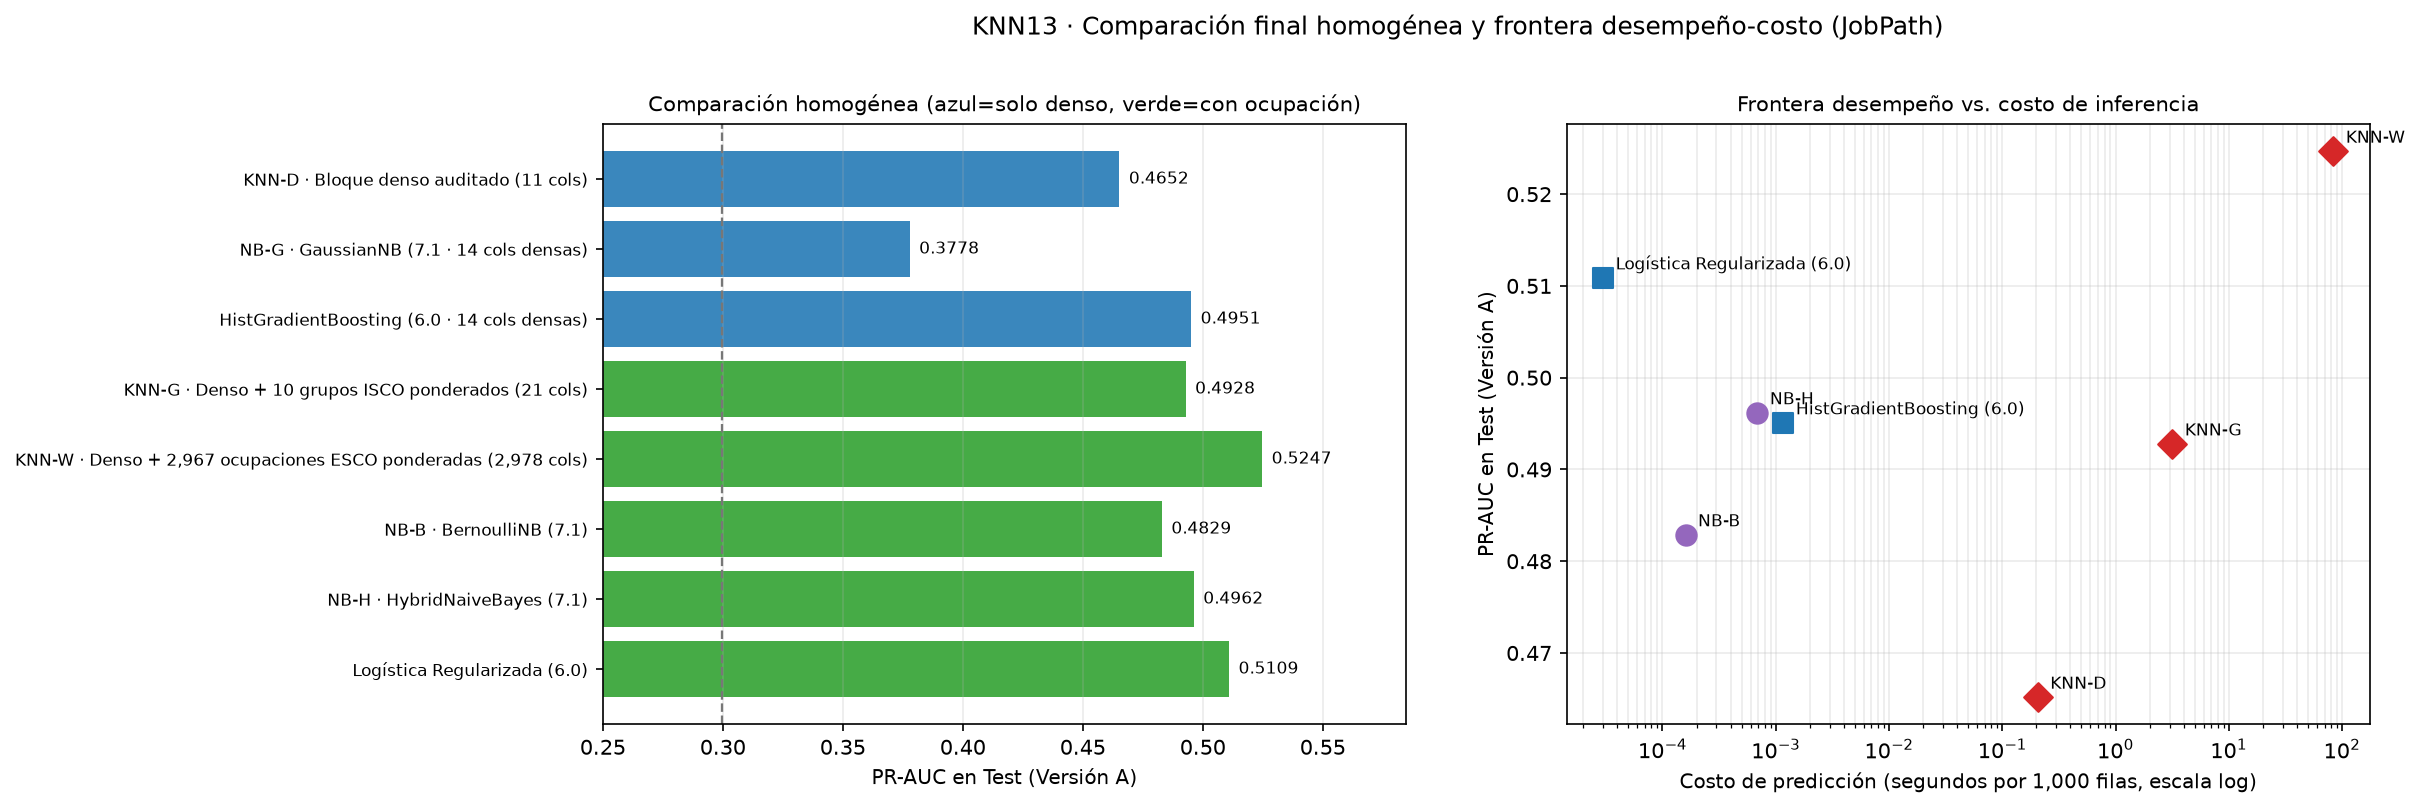

In [14]:
FIG_KNN13 = PIPELINE.plotter.plot_final_frontier(EVAL_BUNDLE)

print("=== Verificación de reproducción exacta de baselines 6.0 y 7.1 ===")
display(EVAL_BUNDLE.reproduced_baselines_table)
print("=== Comparación homogénea 1 · Solo bloque denso ===")
display(EVAL_BUNDLE.like_for_like_dense_table)
print("=== Comparación homogénea 2 · Con información ocupacional ===")
display(EVAL_BUNDLE.like_for_like_occ_table)
print("=== Diferencias pareadas con IC 95 % por bootstrap de personas ===")
display(EVAL_BUNDLE.paired_bootstrap_table)
print("=== Comparación justa a igual tasa de alerta (NB-H) ===")
display(EVAL_BUNDLE.equal_alert_rate_table)
print("=== Tabla de costos computacionales y escalabilidad ===")
display(EVAL_BUNDLE.cost_comparison_table)
print("=== Tabla unificada (Versión A · Referencias, 7.0, 7.1 y 7.2) ===")
display(EVAL_BUNDLE.final_unified_comparison_table)
display(Image(filename=str(FIG_KNN13)))


### Lectura

- **Reproducción exacta de baselines previos (`13a_reproduccion_baselines_6_0_y_7_1.csv`):** las cuatro referencias reestimadas sobre la misma partición (`NB-B`, `NB-H`, `Logística Regularizada 6.0` y `HistGradientBoosting 6.0`) reproducen los CSV exportados de `6.0` y `7.1` con diferencias absolutas inferiores a `0.00005` tanto en `PR-AUC` como en `ROC-AUC`, asegurando comparaciones pareadas exactas fila por fila.
- **Comparación homogénea 1 · Solo bloque denso (`13b`, `13d`, muestra `test` completo):**
  - `KNN-D` (`11` cols, `PR-AUC = 0.4652`, `ROC-AUC = 0.6677`, `Brier = 0.1936`) aventaja con holgura a `NB-G` (`14` cols densas, `PR-AUC = 0.3778`, `ROC-AUC = 0.5921`, `Brier = 0.2086`).
  - Sin embargo, frente a `HistGradientBoosting (6.0)` (`14` cols densas, sin ocupación), `KNN-D` **pierde de forma distinguible** en todas las métricas de ranking y a igual alerta: $\Delta$ `PR-AUC = -0.0298` (`[-0.0313, -0.0282]`), $\Delta$ `ROC-AUC = -0.0259` (`[-0.0272, -0.0245]`) y $\Delta$ `F1` igual alerta `-0.0202` (`[-0.0219, -0.0185]`). *(No se compara Brier contra `HistGradientBoosting` porque utiliza `class_weight="balanced"`.)* Sin la señal del oficio, los árboles de boosting explotan mucho mejor las no linealidades y umbrales del bloque denso que la distancia isotrópica de KNN.
- **Comparación homogénea 2 · Con información ocupacional (`13c`, `13d`, `13e`, `13g`, muestra `test` completo):**
  - Añadir los `10` grandes grupos ISCO (`KNN-G`, `21` cols) aporta una ganancia distinguible sobre `KNN-D` (`+0.0276` `PR-AUC`, `[+0.0259, +0.0293]`), supera a `NB-B` en `PR-AUC` (`+0.0099`, `[+0.0074, +0.0125]`, aunque pierde en `ROC-AUC` `-0.0105` y `F1` igual alerta `-0.0138`), y queda por debajo de `NB-H` (`-0.0033`, `[-0.0055, -0.0006]`) y de `Logística Regularizada (6.0)` (`-0.0181`, `[-0.0203, -0.0158]`).
  - **`KNN-W` (`2,978` cols) establece el mejor desempeño predictivo medido hasta ahora en todo el proyecto JobPath (Versión A):** supera de manera estadísticamente distinguible (IC 95 % pareado por persona excluyendo `0` en `PR-AUC`, `ROC-AUC` y `F1` a igual tasa de alerta) a todos los modelos de `6.0`, `7.0` y `7.1`:
    - Frente a **`Logística Regularizada (6.0)` (`Ref 3`, techo previo del proyecto):** $\Delta$ `PR-AUC = +0.0137` (`[+0.0119, +0.0157]`, `0.5247` vs. `0.5109`), $\Delta$ `ROC-AUC = +0.0113` (`[+0.0101, +0.0125]`, `0.7245` vs. `0.7133`) y $\Delta$ `F1` a igual tasa de alerta `+0.0067` (`[+0.0052, +0.0082]`, `0.5451` vs. `0.5384`; nótese que la tasa efectiva de `KNN-W` queda en `53.63 %` vs. `51.78 %` por la discretización `1/101`, y ya con su umbral OOF $\tau^* =$ `0.28` logra `F1 = 0.5471` con alerta menor `47.58 %`). *(Brier no se compara con `6.0` por ser balanceada.)*
    - Frente a **`NB-H (7.1)`:** $\Delta$ `PR-AUC = +0.0285` (`[+0.0267, +0.0309]`, `0.5247` vs. `0.4962`), $\Delta$ `ROC-AUC = +0.0187` (`[+0.0177, +0.0200]`), $\Delta$ `F1` igual alerta `+0.0114` (`[+0.0100, +0.0131]`) y mejor Brier sin ponderar (`0.1817` vs. `0.1871`).
    - Frente a **`NB-B (7.1)`:** $\Delta$ `PR-AUC = +0.0417` (`[+0.0394, +0.0442]`).
    - Frente a **`KNN-G`:** $\Delta$ `PR-AUC = +0.0318` (`[+0.0299, +0.0335]`), demostrando que el detalle fino de las `2,967` ocupaciones ESCO supera con creces al proxy de `10` grupos ISCO.
    - Frente a todos los árboles individuales de `7.0` (`ROC-AUC` entre `0.5208` y `0.6157`, `F1` máximo `0.4620`) y frente a `Ref 1` y `Ref 2`.
- **Frontera desempeño vs. costo computacional (`13f_comparacion_costos_computacionales.csv`, figura `KNN13`):**
  - El salto de `+0.0137` `PR-AUC` de `KNN-W` sobre `Logística Regularizada (6.0)` y de `+0.0285` sobre `NB-H` conlleva una penalización extrema en latencia de inferencia: evaluar las `347,720` filas de `test` cuesta `0.010 s` en `Logística (6.0)` (`0.00003 s/1k`), `0.054 s` en `NB-B` (`0.00016 s/1k`), `0.241 s` en `NB-H` (`0.00069 s/1k`) y `0.407 s` en `HistGradientBoosting` (`0.00117 s/1k`), frente a `71.59 s` en `KNN-D` (`0.2059 s/1k`), `1,104.71 s` en `KNN-G` (`3.177 s/1k`) y **`29,146.83 s` en `KNN-W` (`83.8227 s/1k`)** —más de cinco órdenes de magnitud más lento que Naive Bayes y seis órdenes más lento que la regresión logística, requiriendo además retener en memoria la matriz completa de entrenamiento (`121.54 MB`).
- **Recomendación razonada para JobPath y límites del enfoque:**
  1. **Despliegue masivo en producción:** **no se recomienda desplegar `KNN-W` exacto** como motor de inferencia masiva por lotes o en tiempo real; su costo $O(N_{\text{train}} \cdot N_{\text{test}})$ no escala cuando crece la base de currículums. Para scoring rápido masivo sigue siendo preferible `Logística Regularizada (6.0)` (calibrando sus probabilidades si se necesitan scores no balanceados) o `NB-H (7.1)` cuando se exige calibración empírica inmediata en subsegundos.
  2. **Uso recomendado de `KNN-W` en JobPath:** emplearlo en dos roles donde sí brilla: (a) **herramienta de explicabilidad bajo demanda por casos** para orientadores o auditorías (mostrando los vecinos históricos del mismo oficio exacto; además, como con `w = 8` casi todos los vecinos comparten ocupación ESCO, en producción una consulta individual puede prefiltrar por ocupación y ejecutarse en milisegundos); y (b) **nuevo techo empírico de referencia (`PR-AUC = 0.5247`)**, que prueba que existen interacciones locales oficio-trayectoria aprovechables por futuros modelos rápidos (como gradient boosting con codificación de ocupación o modelos lineales con interacciones `oficio x job_order` / `duración`).
  3. **Límites del enfoque:** ausencia de búsqueda aproximada (ANN) por restricción de dependencias, escalado lineal en tiempo de consulta en alta dimensión, resolución discreta `1/101`, falta de coeficientes globales interpretables, asimetría de `FPR`/`FNR` bajo un corte único y sensibilidad a Versión B evaluada en `test` completo únicamente en `KNN-D`.


---

## 15. Bitácora de decisiones, exportación de tablas y figuras, y verificación SHA-256 final

**¿Qué hace?** Construye la bitácora trazable de decisiones (`reports/knn_jobpath/tables/decision_log_knn.csv`) a partir de las cifras ejecutadas, exporta todas las tablas CSV en `UTF-8`, lista las `13` figuras PNG generadas en `reports/knn_jobpath/figures/` y ejecuta `PIPELINE.verify_inputs(SNAPSHOT_BEFORE)` para confirmar que las huellas SHA-256 de los `13` archivos de entrada permanecen intactas.

**¿Por qué existe?** Cumple las reglas de trazabilidad, reproducibilidad e inmutabilidad del repositorio: cada cifra del cuaderno queda respaldada en un archivo CSV y se prueba criptográficamente que ningún archivo fuente fue alterado.

**¿Qué recibe y qué entrega?** Recibe todos los paquetes de resultados y `SNAPSHOT_BEFORE`. Entrega `DECISION_LOG_DF`, `EXPORTED_TABLES_DF`, `FIGURES_INVENTORY_DF` e `INTEGRITY_REPORT_DF`.

**Papel en el proyecto.** Cierra operativamente el cuaderno `7.2` dejando todos sus artefactos listos para auditoría automática y revisión final.


In [15]:
DECISION_LOG_DF = PIPELINE.build_decision_log(
    alignment_checks=BUNDLE_A.alignment_checks,
    manual_res=MANUAL_DEMO,
    geo_bundle=GEO_BUNDLE,
    sens_bundle=SENS_BUNDLE,
    pilot_bundle=PILOT_BUNDLE,
    tuning_bundle=TUNING_BUNDLE,
    cost_bundle=COST_BUNDLE,
    proj_bundle=PROJ_BUNDLE,
    threshold_bundle=THRESHOLD_BUNDLE,
    eval_bundle=EVAL_BUNDLE,
    patterns_bundle=PATTERNS_BUNDLE,
)
EXPORTED_TABLES_DF = PIPELINE.export_all_tables(
    manual_res=MANUAL_DEMO,
    scale_audit_df=BUNDLE_A.scale_audit_table,
    geo_bundle=GEO_BUNDLE,
    sens_bundle=SENS_BUNDLE,
    pilot_bundle=PILOT_BUNDLE,
    tuning_bundle=TUNING_BUNDLE,
    cost_bundle=COST_BUNDLE,
    proj_bundle=PROJ_BUNDLE,
    threshold_bundle=THRESHOLD_BUNDLE,
    eval_bundle=EVAL_BUNDLE,
    patterns_bundle=PATTERNS_BUNDLE,
    decision_log_df=DECISION_LOG_DF,
)
INTEGRITY_REPORT_DF = PIPELINE.verify_inputs(SNAPSHOT_BEFORE)
FIGURES_INVENTORY_DF = pd.DataFrame(
    [
        {"archivo_figura": p.name, "tamano_kb": round(p.stat().st_size / 1024.0, 2)}
        for p in sorted(CONFIG.figures_dir.glob("knn*.png"))
    ]
)

print(
    f"Tablas CSV exportadas: {len(EXPORTED_TABLES_DF)} | "
    f"Figuras PNG exportadas: {len(FIGURES_INVENTORY_DF)} | "
    f"Insumos intactos (SHA-256): {bool(INTEGRITY_REPORT_DF['sin_cambios'].all())} | "
    f"RSS final: {current_process_rss_mb():.1f} MB"
)
display(DECISION_LOG_DF)
display(EXPORTED_TABLES_DF)
display(FIGURES_INVENTORY_DF)
display(INTEGRITY_REPORT_DF)


Tablas CSV exportadas: 48 | Figuras PNG exportadas: 13 | Insumos intactos (SHA-256): True | RSS final: 1657.2 MB


,id_decision,etapa,decision,evidencia_cuantitativa,justificacion_metodologica
0,KNN-01,"Matrices sin fuga, alineación ISCO y auditoría de escala (Paso 3)","Descarte de 3 columnas casi constantes (< 1 % minoría: n_skills_sin_tipo_rob, tiene_skills, tiene_sin_tipo); Standar...","Train=1,391,018 filas (281,674 personas), Test=347,720 filas (70,419 personas), 0 personas solapadas, alineación ISC...",Iguala la varianza de continuas y bins uint8 sin amplificar banderas binarias raras (es_vigente=5.47 %) y ajusta tod...
1,KNN-02,Geometría y ponderación del bloque ocupacional (Paso 4),"Evaluación explícita de contraste de distancias y pureza ocupacional para KNN-D, KNN-G (w_g) y KNN-W (w)",KNN-D (w=0) logra pureza misma ocupación=10.64% y mismo ISCO=29.26%; al subir w en KNN-W hasta 4.0 la pureza ocupaci...,Permite balancear la señal del oficio frente a las 11 variables de trayectoria sin añadir librerías aproximadas.
2,KNN-03,"Sensibilidad a escala, outliers Tukey, entrenamiento sin outliers y Versión B (Paso 5)",Versión A escalada se mantiene como alcance principal tras auditar los 5 regímenes en CV agrupada,25.06% de filas de train tienen algún extremo Tukey (prevalencia 29.50% vs. 30.18% en inliers). En KNN-D (manhattan)...,Versión B solo recorta 4 columnas (IQR_WINSOR_BOUNDS_INFO; 2 en X) y no toca dur_q ni job_order; la winsorización pr...
3,KNN-04,"Algoritmo exacto, paralelismo n_jobs y curvas de costo (Pasos 6, 8 y 9)","Algoritmos seleccionados en piloto: {'KNN-W': 'brute', 'KNN-D': 'kd_tree', 'KNN-G': 'brute'}; n_jobs=8; predicción l...",Pendientes log-log tiempo vs N_train (KNN-D: b=0.23; KNN-G: b=0.64; KNN-W: b=0.99). Proyección total Paso 9=2.914 h ...,Controla memoria RSS evitando duplicación de matrices y garantiza reanudación exacta ante interrupciones.
4,KNN-05,"Ajuste honesto en CV agrupada, curva de aprendizaje y umbral OOF (Pasos 7 y 10)","Tuning en submuestra de 10 % de personas (StratifiedGroupKFold 5 pliegues, 0 personas solapadas), verificación de es...","KNN-D: k=101, uniform, manhattan, w=0, PR-AUC CV=0.4478, tau*=0.270; KNN-G: k=101, uniform, manhattan, w=8, PR-AUC C...",Los pliegues agrupados por resume_id impiden fuga entre experiencias de la misma persona y el umbral nunca mira test.
5,KNN-06,"Evaluación única en Test, calibración y comparación homogénea (Pasos 11, 12 y 14)","Selección de KNN-W como variante KNN principal para análisis de patrones y comparación con 6.0, 7.0 y 7.1","En Test completo: KNN-W obtiene PR-AUC=0.5247 [0.5193, 0.5288], ROC-AUC=0.7245 [0.7220, 0.7271], F1=0.5471 [0.5441, ...","Comparaciones estrictamente homogéneas (denso vs. denso; ocupación vs. ocupación), IC 95 % por bootstrap pareado por..."
6,KNN-07,"Patrones ocupacionales, concordancia K4 y errores K5-K6 (Paso 13)","Análisis K1 a K6 en unidades originales (Versión A, soporte mínimo 200 en train, tasas train y test)","Concordancia KNN-W vs. NB-H en Test: Spearman rho=0.8757, acuerdo a igual alerta=86.02%, kappa=0.7196.","Todas las interpretaciones se formulan como asociaciones observables, cuantificando razones de pendiente y brechas p..."


,archivo_tabla,filas,columnas,tamano_kb,ruta_relativa
0,01a_knn_manual_comparacion.csv,4,5,0.5300,reports/knn_jobpath/tables/01a_knn_manual_comparacion.csv
1,01b_knn_manual_vecinos_unidades_originales.csv,5,13,0.9100,reports/knn_jobpath/tables/01b_knn_manual_vecinos_unidades_originales.csv
2,02_auditoria_escala_y_columnas_knn.csv,14,16,3.5200,reports/knn_jobpath/tables/02_auditoria_escala_y_columnas_knn.csv
3,03_geometria_contraste_y_pureza_vecinos.csv,11,16,1.9900,reports/knn_jobpath/tables/03_geometria_contraste_y_pureza_vecinos.csv
4,04a_auditoria_extremos_tukey_train_test.csv,14,12,1.2600,reports/knn_jobpath/tables/04a_auditoria_extremos_tukey_train_test.csv
5,04b_alcance_version_b_cotas_iqr.csv,9,7,1.8100,reports/knn_jobpath/tables/04b_alcance_version_b_cotas_iqr.csv
6,04c_distorsion_distancias_inliers_vs_extremos.csv,8,8,0.8900,reports/knn_jobpath/tables/04c_distorsion_distancias_inliers_vs_extremos.csv
7,04d_sensibilidad_escala_outliers_version_b_cv.csv,10,13,1.7800,reports/knn_jobpath/tables/04d_sensibilidad_escala_outliers_version_b_cv.csv
8,04e_sensibilidad_bootstrap_pareado_ic95.csv,8,12,2.3000,reports/knn_jobpath/tables/04e_sensibilidad_bootstrap_pareado_ic95.csv
9,04f_desglose_oof_sin_outliers_inliers_vs_extremos.csv,15,9,2.2500,reports/knn_jobpath/tables/04f_desglose_oof_sin_outliers_inliers_vs_extremos.csv


,archivo_figura,tamano_kb
0,knn01_auditoria_escala_dense.png,68.4000
1,knn02_geometria_contraste_y_pureza.png,165.0600
2,knn03_sensibilidad_escala_y_outliers.png,115.3300
3,knn04_curvas_validacion_k_y_pesos.png,184.1700
4,knn05_curva_aprendizaje_estabilidad.png,179.7100
5,knn06_curvas_costo_computacional.png,154.7200
6,knn07_umbral_oof_y_curvas_pr_roc_test.png,260.5600
7,knn08_calibracion_y_resolucion_puntajes.png,120.4900
8,knn09_k1_desempeno_por_grupo_isco.png,128.2300
9,knn10_k3_deciles_riesgo_y_composicion_isco.png,114.3600


,archivo,ruta,sha256_antes,sha256_despues,sin_cambios
0,empleos_unificado_limpio.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\03_processed\empleos_unificado_limpio.csv,ae0cbc6ebd86bcf3…,ae0cbc6ebd86bcf3…,True
1,empleos_limpio_con_competencias_sin_outliers.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\03_processed\empleos_limpio_con_competencias_sin_outli...,de8515e31565ca0b…,de8515e31565ca0b…,True
2,split_map_resume_id.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\reports\eda_jobpath\tables\split_map_resume_id.csv,67dd3e3d68e1ff5e…,67dd3e3d68e1ff5e…,True
3,X_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\train\X_train.csv,84326e5737831b79…,84326e5737831b79…,True
4,y_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\train\y_train.csv,07d22441c00832e8…,07d22441c00832e8…,True
5,X_test.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\test\X_test.csv,785a51c74e626e9f…,785a51c74e626e9f…,True
6,y_test.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\test\y_test.csv,38f822d6ac471ec8…,38f822d6ac471ec8…,True
7,transformers.joblib,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\transformers\con_outliers\transformers....,b64f676458f3ef33…,b64f676458f3ef33…,True
8,X_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\sin_outliers\train\X_train.csv,5bca3c92a9043c9b…,5bca3c92a9043c9b…,True
9,y_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\sin_outliers\train\y_train.csv,07d22441c00832e8…,07d22441c00832e8…,True


### Lectura

- **Trazabilidad completa:** se exportaron exactamente `48` tablas CSV en `UTF-8` dentro de `reports/knn_jobpath/tables/` (incluyendo `decision_log_knn.csv` con las `7` decisiones metodológicas `KNN-01` a `KNN-07` respaldadas con cifras ejecutadas) y `13` figuras PNG (`knn01` a `knn13`) en `reports/knn_jobpath/figures/`, todas con títulos y leyendas en español y sin emojis.
- **Integridad criptográfica confirmada:** la comparación de huellas SHA-256 antes y después de toda la ejecución (`INTEGRITY_REPORT_DF`) confirma `sin_cambios = True` en los `13` archivos de entrada (`13` de `13` intactos), garantizando inmutabilidad total del repositorio de datos.


---

## 16. Cierre: respuesta explícita a la pregunta guía

> *«¿Qué tan bien anticipa la reincidencia ocupacional un modelo basado en vecinos, cómo cambia según el grupo ocupacional, y qué costo computacional y qué sensibilidad a la escala y a los valores extremos implica frente a los árboles y a Naive Bayes?»*

A partir de la evaluación única sobre el conjunto `test` completo de la Versión A (`347,720` experiencias de `70,419` personas disjuntas de las `281,674` personas de `train`), las pruebas de sensibilidad en validación cruzada agrupada y las curvas de costo medidas, la respuesta cuantitativa es:

1. **Capacidad predictiva frente a referencias, árboles y Naive Bayes:**
   - El modelo basado en vecinos que combina las `11` variables densas auditadas con las `2,967` ocupaciones ESCO ponderadas (**`KNN-W`**, `k = 101`, `uniform`, `euclidean`, `w = 8`, $\tau^* =$ `0.28`) alcanza el **mejor desempeño predictivo medido hasta ahora en JobPath**: `PR-AUC = 0.5247` (`[0.5193, 0.5288]`), `ROC-AUC = 0.7245` (`[0.7220, 0.7271]`), `F1 = 0.5471` (`[0.5441, 0.5499]`) y mejor `Brier` entre los modelos sin ponderación de clases (`0.1817`, `ECE = 0.0091`).
   - Supera de forma estadísticamente distinguible (IC 95 % pareado por persona excluyendo `0`) al techo previo **`Logística Regularizada (6.0)`** (`+0.0137` `PR-AUC`, `[+0.0119, +0.0157]`; `+0.0113` `ROC-AUC`), a **`NB-H (7.1)`** (`+0.0285` `PR-AUC`, `[+0.0267, +0.0309]`), a **`NB-B (7.1)`** (`+0.0417` `PR-AUC`), a los tres árboles individuales de `7.0` (`ROC-AUC` `0.5208`–`0.6157`) y a las referencias triviales (`Ref 1` y `Ref 2`).
   - Sin embargo, esa superioridad depende decisivamente de la granularidad ocupacional: `KNN-G` (`10` grupos ISCO, `PR-AUC = 0.4928`) pierde `-0.0318` frente a `KNN-W` y queda ligeramente debajo de `NB-H` (`-0.0033`), y **`KNN-D`** (solo `11` variables densas, `PR-AUC = 0.4652`) supera a `NB-G` (`0.3778`) pero pierde claramente frente a **`HistGradientBoosting (6.0)`** (`0.4951`, $\Delta =$ `-0.0298`, `[-0.0313, -0.0282]`).

2. **Variación según el gran grupo ocupacional ISCO-08:**
   - La reincidencia varía fuertemente por grupo (desde `7.61 %` en `0 · Ocupaciones militares` hasta `33.87 %` en `5 · Servicios y vendedores`, `33.37 %` en `3 · Técnicos` y `33.05 %` en `9 · Elementales`, con brechas `train` vs. `test` menores a `1` punto porcentual en todos los grupos).
   - `KNN-W` supera de forma distinguible a `NB-H` en **`7` de los `10` grupos** —destacando `4 · Personal de apoyo administrativo` (`+0.0404` `PR-AUC`) y `1 · Directores y gerentes` (`+0.0402`)—, mientras que en `7 · Operarios` (`+0.0055`), `6 · Agricultores` (`+0.0115`) y `0 · Militares` (`+0.0251`) no hay diferencia distinguible. Además, `KNN-W` eleva la reincidencia real del decil superior `D10` a `63.58 %` (*lift* `2.121` vs. `1.965` en `NB-H`) incorporando perfiles de `5 · Servicios` (`22.09 %`) y `9 · Elementales` (`9.76 %`), y ofrece explicaciones locales con `100.0 %` de pureza de oficio en los `6` casos arquetípicos `K2`.

3. **Costo computacional frente a árboles y Naive Bayes:**
   - Mientras los árboles (`7.0`), `NB-B`/`NB-H` (`7.1`), `Logística (6.0)` y `HistGradientBoosting (6.0)` predicen el `test` completo en menos de medio segundo (`0.010 s` a `0.407 s`, costo constante respecto a `N_train`), KNN traslada el cómputo a la predicción. `KNN-D` (`kd_tree`) escala sublinealmente (`b = 0.2258`, `71.59 s` en `test`) y `KNN-G` (`kd_tree` en `1.39M`) toma `1,104.71 s`, pero **`KNN-W` (fuerza bruta CSR)** escala cuasilinealmente (`b = 0.9930`, `R^2 = 0.9992`) y requirió **`29,146.83 s`** acumulados en bloques (`83.8227 s` por `1,000` consultas), aunque con memoria de matriz moderada (`121.54 MB`, RSS pico `1931.7 MB`). Por este costo, `KNN-W` exacto no es recomendable para scoring masivo en producción, pero sí como techo de desempeño y motor explicativo bajo demanda.

4. **Sensibilidad a la escala y a los valores extremos (demostración sobre entrenamiento sin outliers y Versión B):**
   - La auditoría reveló escalas muy dispares en `dense_clean` (`std` entre `0.2231` y `1.7218`), `3` columnas casi constantes `< 1 %` descartadas y un `25.06 %` de filas de `train` con extremos Tukey (especialmente `dur_q_rob`, `11.56 %`, factor `2.935` en desviación estándar) que multiplican por `1.834`–`1.922` la distancia a los vecinos y explican por qué `manhattan` (`L1`) vence a `euclidean` (`L2`) en `KNN-D` y `KNN-G`.
   - **Resultado decisivo sobre outliers:** entrenar `KNN-D` **exclusivamente sin filas con outliers Tukey (`R4_A_solo_inliers`) empeora significativamente el desempeño** tanto en CV (`-0.01269` `PR-AUC`, `[-0.01630, -0.00848]` en `manhattan`; `-0.01734` en `euclidean`) como en el **`test` completo (`0.4652` a `0.4496`, $\Delta =$ `-0.01561`, `[-0.01780, -0.01350]`)**. Aunque ayuda levemente en *inliers* (`0.4353` a `0.4391`), desploma la predicción en el `25 %` de trayectorias extremas reales (`0.4774` a `0.4229`) al dejarlas sin vecinos propios. La winsorización Tukey de las `6` continuas (`-0.00243` en `test`) y la Versión B (`-0.00187` en `test`, que en rigor solo recorta `2` columnas de `X`: `n_skills_essential` y `n_skills_knowledge`, dejando intactas `dur_q`, `job_order`, `start_ord` y `end_ord`) también pierden ligeramente en `PR-AUC` a cambio de mejoras marginales en `ROC-AUC`. En JobPath, conservar los extremos reales de la Versión A escalada preserva la información necesaria para anticipar trayectorias largas y veteranas.


---

## 17. Guía en lenguaje sencillo para cualquier lector (sin tecnicismos)

Esta sección resume en palabras cotidianas qué hicimos, qué encontramos y qué significa para el proyecto JobPath. Cada cifra indicada entre comillas de código proviene directamente de los resultados ejecutados en el cuaderno, señalando en qué sección, tabla o figura se puede verificar.

### 1. ¿Qué datos estamos analizando?
Trabajamos con historiales laborales reales clasificados por oficio (Sección 3, tablas `02_auditoria_escala_y_columnas_knn.csv` y `13g_comparacion_unificada_version_a.csv`). Para evaluar con total honestidad, dividimos los datos por persona sin mezclar a nadie entre entrenamiento y prueba:
- **Datos para aprender (`train`):** `1,391,018` empleos pertenecientes a `281,674` personas.
- **Datos reservados para probar (`test`):** `347,720` empleos pertenecientes a `70,419` personas completamente distintas (`0` personas repetidas entre ambos grupos).
- **Qué queremos anticipar:** si la persona volverá a trabajar en ese mismo oficio más adelante en su carrera. Esto ocurre en casi `3` de cada `10` empleos (`30.01 %` en entrenamiento y `29.97 %` en prueba).

### 2. ¿Cómo funciona este método (KNN)?
A diferencia de un árbol de reglas o de una fórmula matemática fija, **KNN busca en el historial los casos más parecidos al empleo actual y mira qué pasó con ellos** (Sección 2, tablas `01a_knn_manual_comparacion.csv` y `01b_knn_manual_vecinos_unidades_originales.csv`).
- Primero comprobamos con una cuenta hecha a mano sobre `1` empleo de prueba frente a todo el historial que el programa coincide exactamente con el cálculo manual (`0.000e+00` de error en distancias y puntajes uniformes).
- Tras probar `228` combinaciones sin tocar los datos de prueba (Sección 7, tabla `06c_tuning_ganadores_cv.csv`, figura `KNN04`), la mejor configuración consiste en buscar los **`101` empleos pasados más parecidos**, dando mucho peso a que pertenezcan **al mismo oficio exacto**, y contar qué porcentaje de esos `101` casos terminó repitiendo el oficio. Usar `101` vecinos evita estimaciones bruscas (como ocurría con solo `5` vecinos) y permite explicar cualquier resultado mostrando ejemplos concretos de personas con trayectorias reales muy similares (Sección 13, tablas `12_k2a` y `12_k2b`).

### 3. ¿Qué tan bien funcionó frente a los otros modelos del proyecto?
Probamos tres versiones de KNN en las `347,720` experiencias de prueba (Sección 11, tabla `10a_resultados_test_version_a_ic95.csv`, figura `KNN07`; Sección 14, tablas `13b`, `13c`, `13d`, `13g`, figura `KNN13`):
- **Solo con datos de trayectoria, sin oficio (`KNN-D`):** alcanza `0.4652` en el indicador principal de acierto sobre quienes repiten oficio (`PR-AUC`). Supera al Naive Bayes más simple (`0.3778`), pero pierde con claridad frente al modelo de árboles combinados de la etapa `6.0` (`0.4951`). Sin saber el oficio, buscar vecinos no basta.
- **Añadiendo solo `10` grandes familias de ocupación (`KNN-G`):** sube a `0.4928`, acercándose a Naive Bayes híbrido (`0.4962`), pero aún por debajo de la regresión logística (`0.5109`).
- **Añadiendo los `2,967` oficios específicos (`KNN-W`):** alcanza **`0.5247`**, el **mejor resultado de todo el proyecto hasta ahora**. Supera con certeza estadística a la regresión logística de `6.0` (`0.5109`), a Naive Bayes híbrido (`0.4962`) y a todos los árboles individuales de `7.0`. Además, sus porcentajes estimados de riesgo son muy realistas: el promedio predicho (`30.23 %`, tabla `11`) casi coincide con el promedio real (`29.97 %`).
- **Qué significa en la práctica (Sección 13, tabla `12_k3a`, figura `KNN10`):** si ordenamos todos los empleos de prueba según el puntaje de `KNN-W` y tomamos el `10 %` con mayor riesgo estimado (`34,772` casos), en ese grupo **`63.58 %`** realmente repitió el oficio —más del doble del promedio general—, frente a solo **`9.14 %`** en el `10 %` de menor riesgo.

### 4. ¿Qué encontramos según el grupo ocupacional?
La frecuencia con la que se repite un oficio y la precisión del modelo varían mucho entre grupos ocupacionales (Sección 13, tablas `12_k1`, `12_k3c`, `12_k5b`, figuras `KNN09` y `KNN10`), y todos los porcentajes se mantuvieron estables entre entrenamiento y prueba (diferencias menores a `1` punto porcentual):
- **Grupos donde más se repite el oficio:** trabajadores de servicios y ventas (`33.87 %` en `75,803` casos de prueba), técnicos y profesionales de nivel medio (`33.37 %` en `68,181`) y ocupaciones elementales (`33.05 %` en `47,849`), seguidos de profesionales científicos e intelectuales (`30.13 %` en `61,082`).
- **Grupos con menor repetición:** operadores de máquinas (`24.71 %`), operarios y artesanos (`23.08 %`), personal de apoyo administrativo (`22.55 %`), trabajadores agropecuarios (`21.92 %`), directores y gerentes (`21.37 %`) y, muy por debajo del resto, ocupaciones militares (`7.61 %` en `802` casos).
- **Dónde aporta más buscar casos parecidos:** `KNN-W` supera de forma clara a Naive Bayes en **`7` de los `10` grupos**, con sus mayores mejoras en personal de apoyo administrativo (`0.3546` vs. `0.3142`) y directores y gerentes (`0.4139` vs. `0.3737`). En cambio, en operarios y artesanos, trabajadores agropecuarios y ocupaciones militares las diferencias no se distinguen estadísticamente del azar.
- **Trayectoria y duración (Sección 13, tablas `12_k3b`, `12_k6a`, figura `KNN12`):** la repetición casi se duplica conforme avanza la carrera —de `21.52 %` en el primer empleo a `42.08 %` en personas con `9` o más empleos— y los casos de mayor riesgo suelen ser empleos mucho más cortos (`7.19` trimestres de media frente a `18.08` en el grupo de menor riesgo).
- **Cautela importante:** todos estos resultados son **asociaciones observadas en el historial**, no relaciones de causa y efecto. Además, usar un único punto de corte para todos los grupos genera más falsas alarmas en sectores de alta repetición (como servicios y ocupaciones elementales) y más omisiones en sectores de baja repetición (como administrativos, directivos o militares).

### 5. ¿Cuánto cuesta en tiempo frente a los otros modelos?
Aquí aparece la gran desventaja de KNN (Sección 8, tabla `07b`, figura `KNN06`; Sección 9, tabla `08`; Sección 14, tabla `13f`, figura `KNN13`):
- Los árboles, Naive Bayes y la regresión logística resumen el historial en reglas o pesos compactos y evalúan los `347,720` casos de prueba en **menos de medio segundo** (`0.010` segundos la regresión logística y `0.241` segundos Naive Bayes híbrido).
- KNN no resume el pasado: cada vez que llega un caso nuevo tiene que compararlo contra el archivo de `1,391,018` empleos. Cuando usa los `2,967` oficios (`KNN-W`), el tiempo crece proporcionalmente al tamaño de la base y evaluar toda la prueba tomó **`29,146.83` segundos** de cómputo acumulado en bloques (algo más de ocho horas en total), aunque sin agotar la memoria del equipo (la tabla ocupó `121.54 MB` y el programa se mantuvo debajo de `2,100 MB` de RAM).
- **Conclusión práctica para JobPath:** para evaluar miles de perfiles al instante conviene mantener el modelo lineal rápido de `6.0` (o Naive Bayes si se requieren probabilidades directas sin ajuste). `KNN-W` es valioso como **apoyo explicativo para consultas individuales** (mostrar casos reales parecidos del mismo oficio) y como **referencia de calidad (`0.5247`)** que demuestra que modelos futuros más rápidos pueden mejorar si aprenden combinaciones entre oficio y trayectoria.

### 6. ¿Qué ocurre con las escalas y los casos extremos (y por qué no se deben eliminar los extremos)?
Como KNN mide distancias entre perfiles, tuvimos que cuidar dos aspectos clave (Sección 3, tabla `02`, figura `KNN01`; Sección 5, tablas `04a` a `04g`, figura `KNN03`):
- **Escalas comparables:** antes de medir distancias se descartaron `3` columnas casi siempre constantes (cambiaban en menos del `1 %` de los casos) y se llevaron las `9` variables numéricas y ordinales a una misma escala usando solo los datos de entrenamiento, conservando las `2` banderas de sí/no en `0` y `1`.
- **Casos extremos reales:** `25.06 %` de los empleos de entrenamiento (`348,621` registros) tienen al menos un valor extremo —por ejemplo empleos muy duraderos (`11.56 %`) o carreras muy largas (`4.82 %`)— que casi duplican la distancia a sus vecinos (`1.834` veces en distancia euclidiana).
- **Por qué no conviene entrenar KNN sin casos extremos:** pusimos a prueba directamente la idea de entrenar KNN excluyendo todas las filas con valores extremos. El resultado fue contundente: el modelo **empeoró claramente**, cayendo en la prueba completa de `0.4652` a **`0.4496`** (tabla `04g`). El motivo quedó medido en validación (tabla `04f`): quitar los extremos mejora apenas unas milésimas en los casos habituales (`0.4353` a `0.4391`), pero **hace que el modelo falle mucho en el `25 %` de personas con trayectorias largas o extremas** (cae de `0.4774` a `0.4229`), porque al borrarlos del historial el modelo se queda sin ejemplos parecidos con los cuales compararlas.
- **Recortar suavemente los extremos también resta un poco:** tanto recortar las `6` variables numéricas por vallas estadísticas (`0.4628` en prueba) como usar la llamada Versión B del proyecto (`0.4634` —que en realidad solo recorta `2` columnas de conteo de competencias y deja intactas la duración y el orden de los empleos, tabla `04b`) reducen ligeramente el indicador principal respecto a mantener los datos completos (`0.4652`). Por eso el análisis principal conserva todos los registros históricos reales.
